# Analiza międzyplatformowa: Wykop, YouTube, Bluesky

Notebook porównuje mowę nienawiści wobec migrantów na trzech platformach wokół tych samych wydarzeń i testuje hipotezy:

| | Hipoteza | Sekcja |
|---|---|---|
| **H1** | Istotne wydarzenia związane z migrantami powodują zmiany poziomu mowy nienawiści wobec migrantów w polskojęzycznych mediach społecznościowych. | 1 |
| **H4** | Zależność między wydarzeniami a poziomem mowy nienawiści różni się między YouTube, Wykopem a Bluesky. | 1 |
| **H2** | Siła i kierunek zmian mowy nienawiści zależą od rodzaju wydarzenia (kryminalne, polityczne, zagraniczne). | 7 |

Plan, decyzje i ich uzasadnienie: [`docs/ANALIZA_MIEDZYPLATFORMOWA.md`](../../docs/ANALIZA_MIEDZYPLATFORMOWA.md).
Wyjaśnienie technik (RR, OR, meta-analiza, Holm, log-odds, Gini…): [`docs/METODY_ANALIZY.md`](../../docs/METODY_ANALIZY.md).

**Najważniejsze ustalenia:**
- wspólne okno **−7..+14 dni**; przed = dni −7..−1, po = dni 0..+14 (data komentarza),
- trzy miary: **`hate_migrant/all`** (główna), `migrant/all`, `hate_migrant/migrant`,
- **poziomy (%) porównujemy tylko w obrębie platformy**; między platformami porównujemy **zmianę przed → po** (OR, RR),
- liczby bezwzględne jako **średnia dzienna** (okres „przed” ma 7 dni, „po” 15),
- platformy łączymy **meta-analizą**, a nie sumowaniem komentarzy,
- YouTube / Smierc_Zolnierza wykluczone (cały okres „przed” to jeden film).

## 0. Konfiguracja i dane

In [1]:
import json
import re
import sys
from collections import Counter
from itertools import combinations
from math import comb
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import simplemma
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import confint_proportions_2indep
from wordcloud import WordCloud

# katalog projektu = pierwszy katalog w górę, który zawiera events.json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())
sys.path.insert(0, str(ROOT))
from src.lexicon.slurs import find_slurs  # noqa: E402

# ---- konfiguracja ----
PLATFORMS = ["wykop", "youtube", "bluesky"]
EVENTS = json.loads((ROOT / "events.json").read_text(encoding="utf-8"))

# typ (H2) i zasięg wydarzenia – PRZYPISANE RĘCZNIE (docs/ANALIZA_MIEDZYPLATFORMOWA.md, §2.2)
EVENT_META = {
    "Pakt_Azyl_PE":               ("polityczne",       "zagraniczne"),
    "Smierc_Zolnierza":           ("kryminalne",       "krajowe"),
    "Bojka_Srem":                 ("kryminalne",       "krajowe"),
    "Strategia_Migracyjna":       ("polityczne",       "krajowe"),
    "Dezinformacja_Krakow":       ("dezinformacja",    "krajowe"),
    "Ceuta_Masowe_Przekroczenie": ("kryzys graniczny", "zagraniczne"),
    "Atak_Kamienna_Gora":         ("kryminalne",       "krajowe"),
}
EXCLUDE = {("youtube", "Smierc_Zolnierza")}  # cały okres "przed" to 99 komentarzy pod jednym filmem

WINDOW = (-7, 14)          # okno główne (relative_day, data komentarza)
POST_FROM_DAY = 0          # dzień 0 należy do "po"
DAYS_PRE = POST_FROM_DAY - WINDOW[0]
DAYS_POST = WINDOW[1] - POST_FROM_DAY + 1
PLACEBO_WINDOW = (-21, -1)  # test placebo (tylko Wykop i Bluesky, które mają dane ±28)
PLACEBO_DAY = -14
MIN_LABEL_MATCH = 0.8      # min. odsetek id z labeled/, które są w clean/comments.csv (kontrola spójności danych)
MIN_N_PERIOD = 30          # min. komentarzy w okresie przed/po, żeby liczyć efekt komórki
MIN_K_PRE_TOP = 20         # min. komentarzy z hejtem "przed", żeby komórka weszła do rankingu top 3
TOP_K = 3
MIN_DAILY_N = 10           # min. komentarzy w mianowniku dnia, żeby liczyć dzienny odsetek
ROLL_DAYS = 3
TOP_N_WORDS = 30
ALPHA = 0.05

# miara -> (licznik, warunek mianownika); None = wszystkie komentarze
METRICS = {
    "hate_migrant/all": ("hate_migrant", None),
    "migrant/all": ("migrant", None),
    "hate_migrant/migrant": ("hate_migrant", "migrant"),
}
MAIN = "hate_migrant/all"
METRIC_NAMES = {
    "hate_migrant/all": "hejt wobec migrantów / wszystkie komentarze",
    "migrant/all": "komentarze o migracji / wszystkie komentarze",
    "hate_migrant/migrant": "hejt wobec migrantów / komentarze o migracji",
}

HATE_MIGRANT_COLS = ["llm_is_hate_migrants", "model_hate_migrants", "human_hate_migrants"]
CLEAN_COLS = ["comment_id", "relative_day", "thread_id", "author_id", "likes", "text"]

PLATFORM_COLORS = {"wykop": "#2a78d6", "youtube": "#eb6834", "bluesky": "#1baf7a"}
TYPE_ORDER = ["kryminalne", "polityczne", "dezinformacja", "kryzys graniczny"]
TYPE_COLORS = dict(zip(TYPE_ORDER, ["#c2410c", "#7c3aed", "#0f766e", "#b45309"]))
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#8a8984"
BLUES = LinearSegmentedColormap.from_list("blues", ["#f2f7fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])

plt.rcParams.update({
    "figure.figsize": (13, 4.5), "figure.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)


def fmt_p(t, digits=3):
    # kolumny z p-value jako tekst w notacji naukowej (round() zamieniłby małe p na 0)
    t = t.copy()
    for c in t.columns:
        name = c[0] if isinstance(c, tuple) else c
        if name == "p" or str(name).startswith("p ") or str(name).startswith("p("):
            t[c] = t[c].map(lambda v: "" if pd.isna(v) else f"{v:.3g}")
    return t.round(digits)


def holm(p):
    # korekta Holma, która przepuszcza NaN
    p = pd.Series(p, dtype=float)
    out = pd.Series(np.nan, index=p.index)
    ok = p.notna()
    if ok.any():
        out[ok] = multipletests(p[ok], method="holm")[1]
    return out


def platform_legend(fig, platforms=None, extra=(), top=0.9, **kw):
    platforms = platforms or PL
    handles = [plt.Line2D([], [], marker="o", ls="", ms=9, color=PLATFORM_COLORS[p]) for p in platforms]
    labels = list(platforms)
    for h, l in extra:
        handles.append(h)
        labels.append(l)
    fig.tight_layout(rect=(0, 0, 1, top))
    fig.legend(handles, labels, loc="upper center", ncol=len(labels), bbox_to_anchor=(0.5, 1.0), **kw)

### Wczytanie i ujednolicenie etykiet

Dla każdej platformy i wydarzenia bazą są **wszystkie komentarze z `clean/comments.csv`**, do których doklejamy
`labeled/` (LEFT JOIN po `comment_id`; dla Wykopu `comments_corrected.csv`, jeśli istnieje).

| etykieta | Wykop | YouTube, Bluesky |
|---|---|---|
| `migrant` | komentarz z `topic/` (regex) **i** LLM: o migracji | komentarz jest w `labeled/` (regex + LLM: o migracji) |
| `hate_migrant` | komentarz z `topic/` **i** (LLM: hejt wobec migrantów **lub** leksykon `hate_migrants_auto`) | `labeled/` **i** LLM: hejt wobec migrantów |

Na YouTube i Bluesky komentarz spoza `labeled/` ma z definicji `migrant = hate_migrant = 0`.
W mierze `hate_migrant/migrant` liczymy tylko komentarze z `migrant = 1` (leksykon na Wykopie czasem trafia komentarz,
którego LLM nie uznał za dotyczący migracji – liczy się on w `hate_migrant/all`, ale nie w `hate_migrant/migrant`).

In [2]:
def to_bool(s):
    return s.fillna(False).astype(str).str.strip().str.lower().isin(["true", "1", "1.0"])


def flag(d, cols):
    # OR po wszystkich kolumnach z listy, które istnieją w danych
    out = pd.Series(False, index=d.index)
    for c in cols:
        if c in d.columns:
            out |= to_bool(d[c])
    return out


def load_event(platform, event):
    event_dir = ROOT / "data" / "interim" / platform / f"{EVENTS[event]}_{event}"
    lab_file = event_dir / "labeled" / "comments_corrected.csv"
    if not lab_file.exists():
        lab_file = event_dir / "labeled" / "comments.csv"
    if not lab_file.exists():
        return None, "brak labeled/comments.csv"
    clean = pd.read_csv(event_dir / "clean" / "comments.csv", encoding="utf-8-sig", usecols=CLEAN_COLS,
                        dtype={"comment_id": str, "thread_id": str, "author_id": str}).drop_duplicates("comment_id")
    labeled = pd.read_csv(lab_file, encoding="utf-8-sig", dtype={"comment_id": str})
    if not isinstance(labeled.index, pd.RangeIndex):
        # wiersze mają o jedno pole więcej niż nagłówek (bluesky:Atak_Kamienna_Gora – brak nazwy "parent_context"),
        # więc pandas wziął comment_id za indeks; dokładamy brakującą nazwę kolumny po post_context
        cols = list(labeled.columns)
        i = cols.index("post_context") + 1
        labeled = labeled.reset_index()
        labeled.columns = [*cols[:i], "parent_context", *cols[i:]]
        labeled["comment_id"] = labeled["comment_id"].astype(str)
    labeled = labeled.drop(columns=["text", "event", "post_id"], errors="ignore").drop_duplicates("comment_id")
    match = labeled["comment_id"].isin(clean["comment_id"]).mean()
    if match < MIN_LABEL_MATCH:
        return None, (f"tylko {match:.0%} id z labeled/ jest w clean/comments.csv "
                      f"(etykiety dotyczą innych obiektów, np. postów) – komórka pominięta")
    d = clean.merge(labeled, on="comment_id", how="left", indicator=True)
    in_labeled = d.pop("_merge").eq("both")

    if platform == "wykop":
        topic = pd.read_csv(event_dir / "topic" / "comments.csv", encoding="utf-8-sig", usecols=["comment_id"],
                            dtype=str)["comment_id"]
        in_topic = in_labeled & d["comment_id"].isin(topic)
        d["migrant"] = in_topic & flag(d, ["llm_is_about_migration"])
        d["hate_migrant"] = in_topic & flag(d, ["llm_is_hate_migrants", "hate_migrants_auto"])
    else:
        d["migrant"] = in_labeled
        d["hate_migrant"] = in_labeled & flag(d, HATE_MIGRANT_COLS)

    # tekst trzymamy tylko tam, gdzie jest potrzebny (słowa, grupy, obelgi) – oszczędza pamięć przy YouTube
    d["text"] = d["text"].fillna("").astype(str).where(d["migrant"] | d["hate_migrant"], "")
    d = d[["comment_id", "relative_day", "thread_id", "author_id", "likes", "text", "migrant", "hate_migrant"]].copy()
    d["platform"], d["event"] = platform, event
    d["typ"], d["zasieg"] = EVENT_META[event]
    d["cell"] = platform + ":" + event
    d["thread"] = d["cell"] + ":" + d["thread_id"].astype(str)  # wątki rozdzielne między komórkami
    # identyfikator komentarza unikalny w obrębie platformy: na YouTube i Bluesky pseudonimy (K000001…) są nadawane
    # od nowa w każdym wydarzeniu, na Wykopie id jest globalne (ten sam komentarz w dwóch nakładających się oknach)
    d["uid"] = d["comment_id"] if platform == "wykop" else event + ":" + d["comment_id"]
    return d, None


frames, skipped = [], {}
for platform in PLATFORMS:
    for event in EVENT_META:
        if (platform, event) in EXCLUDE:
            continue
        d, why = load_event(platform, event)
        if d is None:
            skipped[f"{platform}:{event}"] = why
        else:
            frames.append(d)
for cell, why in skipped.items():
    if not why.startswith("brak"):
        print(f"POMINIĘTA KOMÓRKA {cell}: {why}")
full = pd.concat(frames, ignore_index=True)

PL = [p for p in PLATFORMS if p in set(full["platform"])]
EVENT_ORDER = [e for e in EVENT_META if e in set(full["event"])]  # chronologicznie
CELLS = [f"{p}:{e}" for p in PL for e in EVENT_ORDER if f"{p}:{e}" in set(full["cell"])]
COMMON_EVENTS = [e for e in EVENT_ORDER if all(f"{p}:{e}" in CELLS for p in PL)]

df = full[full["relative_day"].between(*WINDOW)].copy()
df["po"] = (df["relative_day"] >= POST_FROM_DAY).astype(int)
df["okres"] = np.where(df["po"] == 1, "po", "przed")

print(f"komórek wydarzenie × platforma: {len(CELLS)}  ({', '.join(f'{p}: {sum(c.startswith(p) for c in CELLS)}' for p in PL)})")
print("wydarzenia wspólne dla wszystkich platform:", COMMON_EVENTS)
print(f"komentarze w oknie {WINDOW}: {len(df):,} (z {len(full):,} wczytanych)")

komórek wydarzenie × platforma: 16  (wykop: 7, youtube: 6, bluesky: 3)
wydarzenia wspólne dla wszystkich platform: ['Dezinformacja_Krakow', 'Ceuta_Masowe_Przekroczenie', 'Atak_Kamienna_Gora']
komentarze w oknie (-7, 14): 629,105 (z 787,328 wczytanych)


In [3]:
overview = (df.groupby(["platform", "event"], sort=False)
            .agg(komentarze=("comment_id", "size"),
                 przed=("po", lambda s: int((s == 0).sum())), po=("po", "sum"),
                 wątki=("thread", "nunique"),
                 migrant=("migrant", "sum"), hate_migrant=("hate_migrant", "sum")))
overview.insert(0, "typ", [EVENT_META[e][0] for _, e in overview.index])
overview["migrant %"] = 100 * overview["migrant"] / overview["komentarze"]
overview["hate_migrant %"] = 100 * overview["hate_migrant"] / overview["komentarze"]
overview["hate_migrant | migrant %"] = 100 * (
    df[df["migrant"]].groupby(["platform", "event"], sort=False)["hate_migrant"].mean().reindex(overview.index))
display(overview.round(2))
print("Poziomy (%) porównujemy tylko w obrębie platformy – różnice między platformami wynikają głównie ze sposobu zbierania.")

typ  komentarze  przed     po  wątki  migrant  hate_migrant  migrant %  hate_migrant %  hate_migrant | migrant %
platform event                                                                                                                                                    
wykop    Pakt_Azyl_PE                      polityczne       10412   3458   6954    501     2586          1099      24.84           10.56                     42.03
         Smierc_Zolnierza                  kryminalne       10543   2991   7552    234     4346          1771      41.22           16.80                     40.36
         Bojka_Srem                        kryminalne       10473   3408   7065    534     3412          1239      32.58           11.83                     35.93
         Strategia_Migracyjna              polityczne        9551   3227   6324    408     4350          1437      45.54           15.05                     33.03
         Dezinformacja_Krakow           dezinformacja        7559   2468   5091    650     2067           868      27.34           11.48                     41.36
         Ceuta_Masowe_Przekroczenie  kryzys graniczny       10266   3579   6687    708     4683          1744      45.62           16.99                     37.24
         Atak_Kamienna_Gora                kryminalne        9058   2924   6134    733     2944          1328      32.50           14.66                     44.53
youtube  Pakt_Azyl_PE                      polityczne       87296  35967  51329    509     1847           891       2.12            1.02                     48.24
         Bojka_Srem                        kryminalne      107271  27959  79312    856     2397          1569       2.23            1.46                     65.46
         Strategia_Migracyjna              polityczne      114604  25699  88905    891     4814          2033       4.20            1.77                     42.23
         Dezinformacja_Krakow           dezinformacja       54430  17573  36857    662     1964           930       3.61            1.71                     47.35
         Ceuta_Masowe_Przekroczenie  kryzys graniczny       63939  16961  46978    647     5922          3191       9.26            4.99                     53.88
         Atak_Kamienna_Gora                kryminalne      105881  14833  91048   1000     4998          2967       4.72            2.80                     59.36
bluesky  Dezinformacja_Krakow           dezinformacja        9236   2976   6260   2733      305            73       3.30            0.79                     23.93
         Ceuta_Masowe_Przekroczenie  kryzys graniczny        9715   3061   6654   2663      621           258       6.39            2.66                     41.55
         Atak_Kamienna_Gora                kryminalne        8871   2780   6091   2365      320            89       3.61            1.00                     27.81

Poziomy (%) porównujemy tylko w obrębie platformy – różnice między platformami wynikają głównie ze sposobu zbierania.


## 1. Odsetek przed i po, liczba hejtu i komentarzy (H1, H4)

Dla każdej komórki wydarzenie × platforma i każdej miary:
- % przed i % po, **różnica w pp** z 95% CI (Newcombe),
- **RR** (ryzyko względne) z 95% CI,
- **OR z regresji logistycznej `y ~ po` z błędami klastrowanymi po wątku** – na nim opieramy testy i meta-analizę,
- p z **korektą Holma** w obrębie miary (wszystkie komórki),
- liczby jako **średnia dzienna** przed (7 dni) i po (15 dni).

Cztery widoki: (a) wydarzenia osobno na każdej platformie, (b) wydarzenia wspólnie dla platform,
(c) przed / po wspólnie dla wydarzeń, osobno na platformę, (d) przed / po wspólnie dla wydarzeń i platform.

In [4]:
def woolf(k1, n1, k2, n2):
    # log OR z poprawką 0.5 – zapas, gdy regresja się nie da (zera w komórce)
    a, b, c, e = k2 + 0.5, n2 - k2 + 0.5, k1 + 0.5, n1 - k1 + 0.5
    lor, se = np.log(a * e / (b * c)), np.sqrt(1 / a + 1 / b + 1 / c + 1 / e)
    return lor, se, 2 * stats.norm.sf(abs(lor / se))


def logit_cluster(d, col, formula):
    return smf.logit(formula, data=d.assign(y=d[col].astype(int))).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread"])[0]}, maxiter=200)


def cell_effect(d, col):
    pre, post = d.loc[d["po"] == 0, col], d.loc[d["po"] == 1, col]
    k1, n1, k2, n2 = int(pre.sum()), len(pre), int(post.sum()), len(post)
    out = {"n przed": n1, "n po": n2, "k przed": k1, "k po": k2,
           "przed %": 100 * k1 / n1 if n1 else np.nan, "po %": 100 * k2 / n2 if n2 else np.nan}
    if min(n1, n2) < MIN_N_PERIOD or k1 + k2 == 0:
        return out
    p1, p2 = k1 / n1, k2 / n2
    lo, hi = confint_proportions_2indep(k2, n2, k1, n1, method="newcomb")
    if 0 < k1 < n1 and 0 < k2 < n2:
        try:
            m = logit_cluster(d, col, "y ~ po")
            b, se, p = m.params["po"], m.bse["po"], m.pvalues["po"]
        except Exception:
            b, se, p = woolf(k1, n1, k2, n2)
        rr, se_rr = np.log(p2 / p1), np.sqrt(1 / k2 - 1 / n2 + 1 / k1 - 1 / n1)
    else:
        b, se, p = woolf(k1, n1, k2, n2)
        rr, se_rr = np.nan, np.nan
    return {**out, "różnica pp": 100 * (p2 - p1), "CI lo pp": 100 * lo, "CI hi pp": 100 * hi,
            "RR": np.exp(rr), "RR lo": np.exp(rr - 1.96 * se_rr), "RR hi": np.exp(rr + 1.96 * se_rr),
            "log OR": b, "se": se, "OR": np.exp(b), "OR lo": np.exp(b - 1.96 * se), "OR hi": np.exp(b + 1.96 * se),
            "p": p}


def subset(d, metric):
    col, cond = METRICS[metric]
    return (d[d[cond]] if cond else d), col


def effects(data, metrics=METRICS):
    rows = []
    for cell, d in data.groupby("cell", sort=False):
        p, e = cell.split(":")
        for metric in metrics:
            dd, col = subset(d, metric)
            rows.append({"miara": metric, "cell": cell, "platform": p, "event": e,
                         "typ": EVENT_META[e][0], "zasieg": EVENT_META[e][1], **cell_effect(dd, col)})
    out = pd.DataFrame(rows)
    out["p (Holm)"] = out.groupby("miara")["p"].transform(holm)
    out["istotne"] = out["p (Holm)"] < ALPHA
    out["kierunek"] = np.select([out["istotne"] & (out["log OR"] > 0), out["istotne"] & (out["log OR"] < 0)],
                                ["↑", "↓"], "–")
    return out


eff = effects(df)
eff["cell"] = pd.Categorical(eff["cell"], CELLS, ordered=True)
eff = eff.sort_values(["miara", "cell"]).reset_index(drop=True)
eff["cell"] = eff["cell"].astype(str)


def E(metric):
    return eff[eff["miara"] == metric]

In [5]:
def meta_random(y, se):
    """Meta-analiza efektów losowych: DerSimonian–Laird + przedział Hartung–Knapp (t, k-1 df)."""
    y, se = np.asarray(y, float), np.asarray(se, float)
    ok = ~(np.isnan(y) | np.isnan(se))
    y, se = y[ok], se[ok]
    k = len(y)
    if k == 0:
        return {"k": 0, "mu": np.nan, "se": np.nan, "lo": np.nan, "hi": np.nan, "p": np.nan,
                "tau2": np.nan, "I2": np.nan, "Q": np.nan, "p Q": np.nan}
    w = 1 / se ** 2
    fixed = (w * y).sum() / w.sum()
    q = (w * (y - fixed) ** 2).sum()
    if k == 1:
        return {"k": 1, "mu": y[0], "se": se[0], "lo": y[0] - 1.96 * se[0], "hi": y[0] + 1.96 * se[0],
                "p": 2 * stats.norm.sf(abs(y[0] / se[0])), "tau2": 0.0, "I2": np.nan, "Q": np.nan, "p Q": np.nan}
    c = w.sum() - (w ** 2).sum() / w.sum()
    tau2 = max(0.0, (q - (k - 1)) / c)
    ws = 1 / (se ** 2 + tau2)
    mu = (ws * y).sum() / ws.sum()
    se_hk = max(np.sqrt((ws * (y - mu) ** 2).sum() / ((k - 1) * ws.sum())), np.sqrt(1 / ws.sum()))
    t = stats.t.ppf(1 - ALPHA / 2, k - 1)
    return {"k": k, "mu": mu, "se": se_hk, "lo": mu - t * se_hk, "hi": mu + t * se_hk,
            "p": 2 * stats.t.sf(abs(mu / se_hk), k - 1), "tau2": tau2,
            "I2": max(0.0, (q - (k - 1)) / q) if q > 0 else 0.0, "Q": q, "p Q": stats.chi2.sf(q, k - 1)}


def meta_fixed(y, se):
    """Meta-analiza efektów stałych (wagi 1/se²) – używana per wydarzenie, gdy są 2–3 platformy."""
    y, se = np.asarray(y, float), np.asarray(se, float)
    ok = ~(np.isnan(y) | np.isnan(se))
    y, se = y[ok], se[ok]
    k = len(y)
    if k == 0:
        return {"k": 0, "mu": np.nan, "se": np.nan, "lo": np.nan, "hi": np.nan, "p": np.nan, "I2": np.nan, "p Q": np.nan}
    w = 1 / se ** 2
    mu = (w * y).sum() / w.sum()
    s = np.sqrt(1 / w.sum())
    q = (w * (y - mu) ** 2).sum()
    return {"k": k, "mu": mu, "se": s, "lo": mu - 1.96 * s, "hi": mu + 1.96 * s,
            "p": 2 * stats.norm.sf(abs(mu / s)),
            "I2": max(0.0, (q - (k - 1)) / q) if k > 1 and q > 0 else np.nan,
            "p Q": stats.chi2.sf(q, k - 1) if k > 1 else np.nan}


def q_test(y, se):
    # test Q: czy efekty (np. łączne efekty platform) różnią się bardziej niż przez przypadek
    y, se = np.asarray(y, float), np.asarray(se, float)
    w = 1 / se ** 2
    mu = (w * y).sum() / w.sum()
    q = (w * (y - mu) ** 2).sum()
    return q, stats.chi2.sf(q, len(y) - 1)


def or_row(m):
    return {"OR": np.exp(m["mu"]), "OR lo": np.exp(m["lo"]), "OR hi": np.exp(m["hi"]), "p": m["p"]}


def dia(m, color):
    # romb na wykresie lasu z wyniku meta-analizy
    return {"OR": np.exp(m["mu"]), "lo": np.exp(m["lo"]), "hi": np.exp(m["hi"]), "color": color}


def forest(ax, groups, title="", xlabel="OR po vs przed (skala log)"):
    """Wykres lasu. groups = [{"label", "items": [{"label", "OR", "lo", "hi", "color"}], "diamond": {...} | None}]"""
    y, ticks, labels, bold, xs = 0.0, [], [], [], [1.0]
    for g in groups:
        for it in g["items"]:
            if pd.isna(it["OR"]):
                continue
            ax.hlines(y, it["lo"], it["hi"], color=it["color"], lw=1.6)
            ax.scatter(it["OR"], y, s=44, color=it["color"], edgecolor="white", linewidth=1.1, zorder=3)
            ticks.append(y)
            labels.append(it["label"])
            bold.append(False)
            xs += [it["lo"], it["hi"]]
            y -= 1
        m = g.get("diamond")
        if m is not None and not pd.isna(m["OR"]):
            ax.fill([m["lo"], m["OR"], m["hi"], m["OR"]], [y, y + 0.32, y, y - 0.32], color=m.get("color", INK), zorder=3)
            ax.text(m["hi"], y, f"  {m['OR']:.2f} [{m['lo']:.2f}; {m['hi']:.2f}]", va="center", fontsize=8, color=INK2)
            ticks.append(y)
            labels.append(g["label"])
            bold.append(True)
            xs += [m["lo"], m["hi"]]
            y -= 1
        y -= 0.6
    ax.axvline(1, color=INK2, ls="--", lw=1)
    ax.set_xscale("log")
    xmin, xmax = np.nanmin(xs) * 0.85, np.nanmax(xs) * 1.9
    ax.set_xlim(xmin, xmax)
    log_ticks(ax, "x")
    ax.set_yticks(ticks, labels, fontsize=8.5)
    for lab, b in zip(ax.get_yticklabels(), bold):
        if b:
            lab.set_fontweight("bold")
    ax.set_ylim(y + 0.4, 0.8)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_xlabel(xlabel)
    ax.set_title(title, fontsize=11)


def log_ticks(ax, axis="x"):
    # czytelne podziałki na osi logarytmicznej (bez nakładających się etykiet)
    lo, hi = ax.get_xlim() if axis == "x" else ax.get_ylim()
    tk = [t for t in [0.05, 0.1, 0.25, 0.5, 1, 2, 4, 10, 20] if lo <= t <= hi]
    if len(tk) < 3:
        tk = [t for t in [0.05, 0.1, 0.2, 0.33, 0.5, 0.67, 1, 1.5, 2, 3, 5, 10, 20] if lo <= t <= hi]
    a = ax.xaxis if axis == "x" else ax.yaxis
    (ax.set_xticks if axis == "x" else ax.set_yticks)(tk, [f"{t:g}" for t in tk])
    a.set_minor_locator(mticker.NullLocator())


def items_from(e, label_col, color_fn):
    return [{"label": r[label_col], "OR": r["OR"], "lo": r["OR lo"], "hi": r["OR hi"], "color": color_fn(r)}
            for _, r in e.iterrows()]

### 1a. Wydarzenia osobno, na każdej platformie

Tabela wszystkich komórek. `kierunek`: ↑ / ↓ = istotna zmiana po korekcie Holma, – = brak istotnej zmiany.

In [6]:
show = ["typ", "przed %", "po %", "różnica pp", "CI lo pp", "CI hi pp", "RR", "RR lo", "RR hi",
        "OR", "OR lo", "OR hi", "p (Holm)", "kierunek"]
for metric in METRICS:
    print(f"\n=== {metric}: {METRIC_NAMES[metric]} ===")
    display(fmt_p(E(metric).set_index(["platform", "event"])[show], 2))


=== hate_migrant/all: hejt wobec migrantów / wszystkie komentarze ===


typ  przed %   po %  różnica pp  CI lo pp  CI hi pp    RR  RR lo  RR hi    OR  OR lo  OR hi  p (Holm) kierunek
platform event                                                                                                                                                  
wykop    Pakt_Azyl_PE                      polityczne     6.10  12.77        6.67      5.53      7.77  2.09   1.81   2.42  2.25   1.59   3.19  8.34e-05        ↑
         Smierc_Zolnierza                  kryminalne    18.25  16.22       -2.03     -3.67     -0.44  0.89   0.81   0.97  0.87   0.65   1.15         1        –
         Bojka_Srem                        kryminalne    10.56  12.44        1.88      0.57      3.14  1.18   1.05   1.32  1.20   0.88   1.64         1        –
         Strategia_Migracyjna              polityczne    15.59  14.77       -0.82     -2.37      0.69  0.95   0.86   1.05  0.94   0.73   1.21         1        –
         Dezinformacja_Krakow           dezinformacja    10.70  11.86        1.17     -0.38      2.65  1.11   0.97   1.27  1.12   0.89   1.42         1        –
         Ceuta_Masowe_Przekroczenie  kryzys graniczny    18.08  16.40       -1.67     -3.23     -0.15  0.91   0.83   0.99  0.89   0.70   1.13         1        –
         Atak_Kamienna_Gora                kryminalne    17.95  13.09       -4.86     -6.52     -3.26  0.73   0.66   0.81  0.69   0.54   0.87    0.0265        ↓
youtube  Pakt_Azyl_PE                      polityczne     0.50   1.39        0.88      0.76      1.01  2.77   2.35   3.26  2.79   1.57   4.96   0.00686        ↑
         Bojka_Srem                        kryminalne     1.47   1.46       -0.01     -0.18      0.14  0.99   0.89   1.11  0.99   0.54   1.82         1        –
         Strategia_Migracyjna              polityczne     1.27   1.92        0.65      0.48      0.81  1.51   1.34   1.70  1.52   0.70   3.28         1        –
         Dezinformacja_Krakow           dezinformacja     2.57   1.30       -1.27     -1.54     -1.01  0.51   0.45   0.58  0.50   0.24   1.05     0.728        –
         Ceuta_Masowe_Przekroczenie  kryzys graniczny     7.56   4.06       -3.50     -3.95     -3.07  0.54   0.50   0.58  0.52   0.23   1.15         1        –
         Atak_Kamienna_Gora                kryminalne     1.05   3.09        2.04      1.83      2.23  2.94   2.50   3.45  3.00   1.37   6.55    0.0716        –
bluesky  Dezinformacja_Krakow           dezinformacja     1.01   0.69       -0.32     -0.78      0.06  0.68   0.43   1.08  0.68   0.32   1.44         1        –
         Ceuta_Masowe_Przekroczenie  kryzys graniczny     4.18   1.95       -2.23     -3.05     -1.48  0.47   0.37   0.59  0.46   0.28   0.75     0.025        ↓
         Atak_Kamienna_Gora                kryminalne     1.01   1.00       -0.01     -0.50      0.41  0.99   0.64   1.55  0.99   0.54   1.85         1        –


=== migrant/all: komentarze o migracji / wszystkie komentarze ===


typ  przed %   po %  różnica pp  CI lo pp  CI hi pp    RR  RR lo  RR hi    OR  OR lo  OR hi p (Holm) kierunek
platform event                                                                                                                                                 
wykop    Pakt_Azyl_PE                      polityczne    15.38  29.54       14.15     12.52     15.74  1.92   1.76   2.09  2.31   1.59   3.34  0.00017        ↑
         Smierc_Zolnierza                  kryminalne    41.99  40.92       -1.08     -3.17      1.00  0.97   0.93   1.02  0.96   0.69   1.32        1        –
         Bojka_Srem                        kryminalne    26.53  35.50        8.97      7.10     10.81  1.34   1.26   1.43  1.52   1.11   2.10    0.124        –
         Strategia_Migracyjna              polityczne    44.53  46.06        1.53     -0.58      3.64  1.03   0.99   1.08  1.06   0.76   1.49        1        –
         Dezinformacja_Krakow           dezinformacja    26.09  27.95        1.86     -0.29      3.96  1.07   0.99   1.16  1.10   0.79   1.53        1        –
         Ceuta_Masowe_Przekroczenie  kryzys graniczny    44.59  46.16        1.57     -0.45      3.59  1.04   0.99   1.08  1.07   0.84   1.35        1        –
         Atak_Kamienna_Gora                kryminalne    40.29  28.79      -11.50    -13.61     -9.39  0.71   0.67   0.76  0.60   0.43   0.83   0.0339        ↓
youtube  Pakt_Azyl_PE                      polityczne     0.73   3.09        2.36      2.19      2.53  4.24   3.72   4.83  4.34   1.86  10.16   0.0106        ↑
         Bojka_Srem                        kryminalne     1.96   2.33        0.37      0.17      0.56  1.19   1.08   1.30  1.19   0.65   2.18        1        –
         Strategia_Migracyjna              polityczne     2.16   4.79        2.63      2.40      2.85  2.22   2.03   2.42  2.28   1.02   5.07    0.478        –
         Dezinformacja_Krakow           dezinformacja     5.15   2.87       -2.28     -2.65     -1.91  0.56   0.51   0.61  0.54   0.21   1.43        1        –
         Ceuta_Masowe_Przekroczenie  kryzys graniczny    11.27   8.54       -2.73     -3.27     -2.20  0.76   0.72   0.80  0.74   0.31   1.73        1        –
         Atak_Kamienna_Gora                kryminalne     2.91   5.01        2.10      1.79      2.40  1.72   1.56   1.90  1.76   0.78   3.99        1        –
bluesky  Dezinformacja_Krakow           dezinformacja     3.86   3.04       -0.83     -1.68     -0.05  0.79   0.63   0.99  0.78   0.49   1.23        1        –
         Ceuta_Masowe_Przekroczenie  kryzys graniczny     8.85   5.26       -3.59     -4.77     -2.48  0.59   0.51   0.69  0.57   0.37   0.89    0.146        –
         Atak_Kamienna_Gora                kryminalne     3.63   3.60       -0.04     -0.92      0.77  0.99   0.79   1.25  0.99   0.64   1.52        1        –


=== hate_migrant/migrant: hejt wobec migrantów / komentarze o migracji ===


typ  przed %   po %  różnica pp  CI lo pp  CI hi pp    RR  RR lo  RR hi    OR  OR lo  OR hi  p (Holm) kierunek
platform event                                                                                                                                                  
wykop    Pakt_Azyl_PE                      polityczne    39.10  42.79        3.70     -1.02      8.29  1.09   0.97   1.23  1.17   0.92   1.48         1        –
         Smierc_Zolnierza                  kryminalne    43.07  39.26       -3.82     -7.06     -0.60  0.91   0.84   0.98  0.85   0.67   1.09         1        –
         Bojka_Srem                        kryminalne    38.83  34.89       -3.94     -7.65     -0.29  0.90   0.81   0.99  0.84   0.67   1.07         1        –
         Strategia_Migracyjna              polityczne    35.00  32.06       -2.94     -5.95      0.03  0.92   0.84   1.00  0.88   0.70   1.09         1        –
         Dezinformacja_Krakow           dezinformacja    40.22  41.88        1.67     -2.93      6.19  1.04   0.93   1.17  1.07   0.79   1.45         1        –
         Ceuta_Masowe_Przekroczenie  kryzys graniczny    40.54  35.54       -5.00     -7.95     -2.07  0.88   0.81   0.95  0.81   0.64   1.02     0.808        –
         Atak_Kamienna_Gora                kryminalne    44.14  44.79        0.65     -3.02      4.30  1.01   0.93   1.10  1.03   0.81   1.30         1        –
youtube  Pakt_Azyl_PE                      polityczne    68.70  44.86      -23.84    -29.69    -17.50  0.65   0.59   0.72  0.37   0.19   0.72    0.0493        ↓
         Bojka_Srem                        kryminalne    75.05  62.61      -12.44    -16.53     -8.07  0.83   0.79   0.89  0.56   0.29   1.08     0.916        –
         Strategia_Migracyjna              polityczne    58.92  40.06      -18.86    -23.14    -14.47  0.68   0.63   0.74  0.47   0.32   0.68  0.000977        ↓
         Dezinformacja_Krakow           dezinformacja    49.83  45.23       -4.60     -9.01     -0.17  0.91   0.83   1.00  0.83   0.36   1.91         1        –
         Ceuta_Masowe_Przekroczenie  kryzys graniczny    67.14  47.57      -19.57    -22.15    -16.93  0.71   0.68   0.74  0.44   0.22   0.91     0.333        –
         Atak_Kamienna_Gora                kryminalne    36.11  61.56       25.45     20.61     30.06  1.70   1.50   1.94  2.83   1.45   5.53    0.0342        ↑
bluesky  Dezinformacja_Krakow           dezinformacja    26.09  22.63       -3.46    -13.69      6.19  0.87   0.58   1.30  0.83   0.36   1.90         1        –
         Ceuta_Masowe_Przekroczenie  kryzys graniczny    47.23  37.14      -10.09    -17.79     -2.27  0.79   0.65   0.95  0.66   0.36   1.22         1        –
         Atak_Kamienna_Gora                kryminalne    27.72  27.85        0.13    -10.79     10.14  1.00   0.69   1.47  1.01   0.47   2.14         1        –

**Wykres dumbbell:** kółko puste = odsetek **przed**, pełne = **po**. Jeden panel na platformę, bo poziomy platform są
nieporównywalne. Kolor kreski: czerwony = istotny wzrost, niebieski = istotny spadek, szary = brak istotnej zmiany.

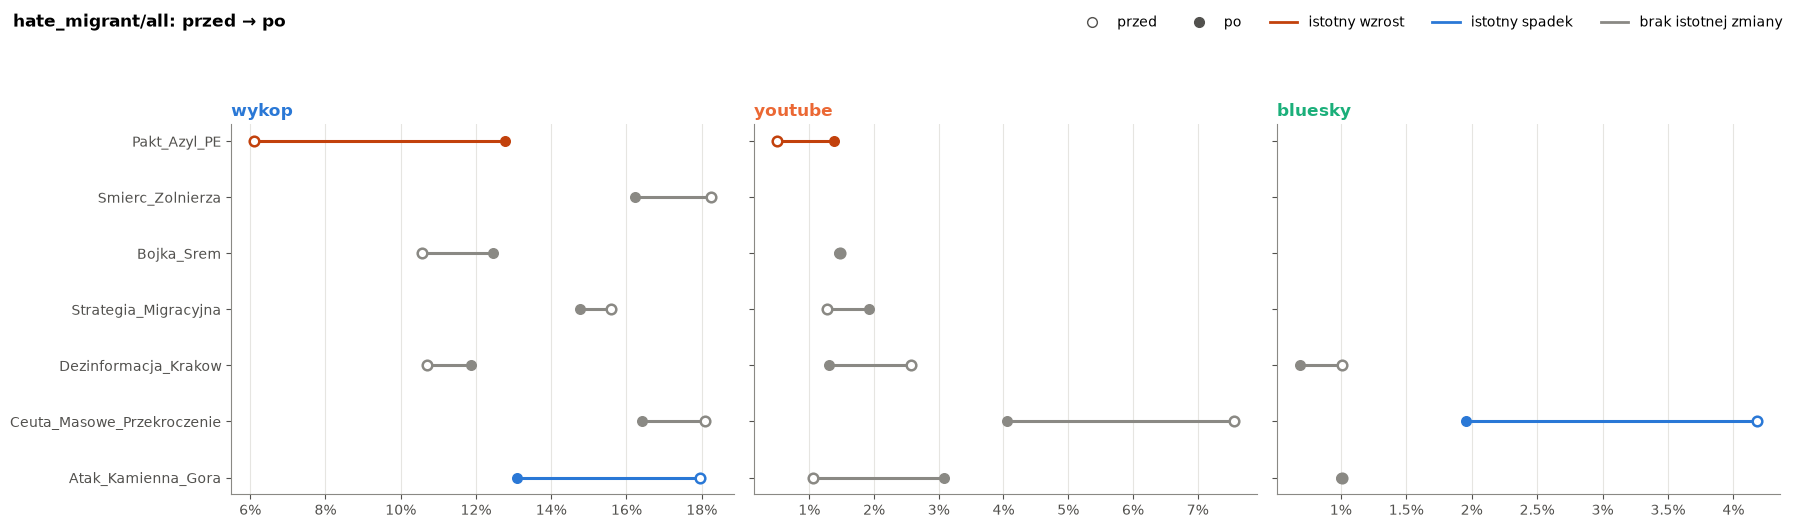

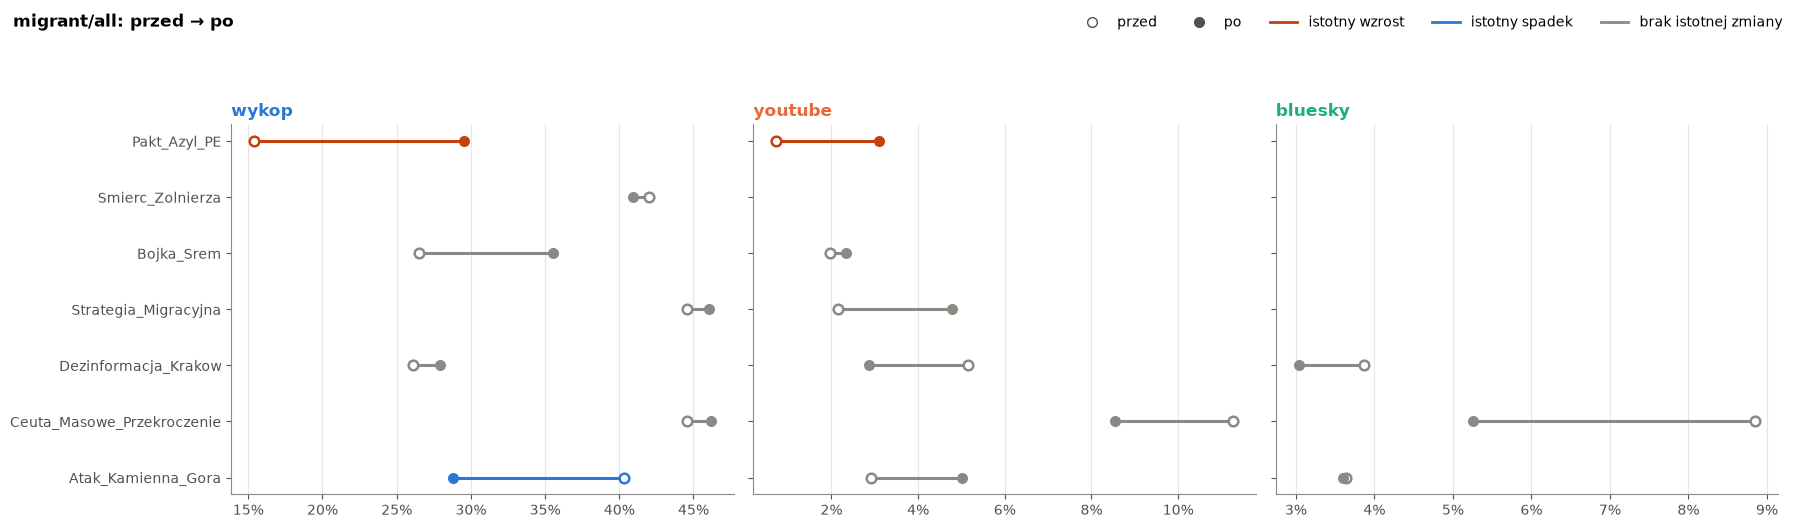

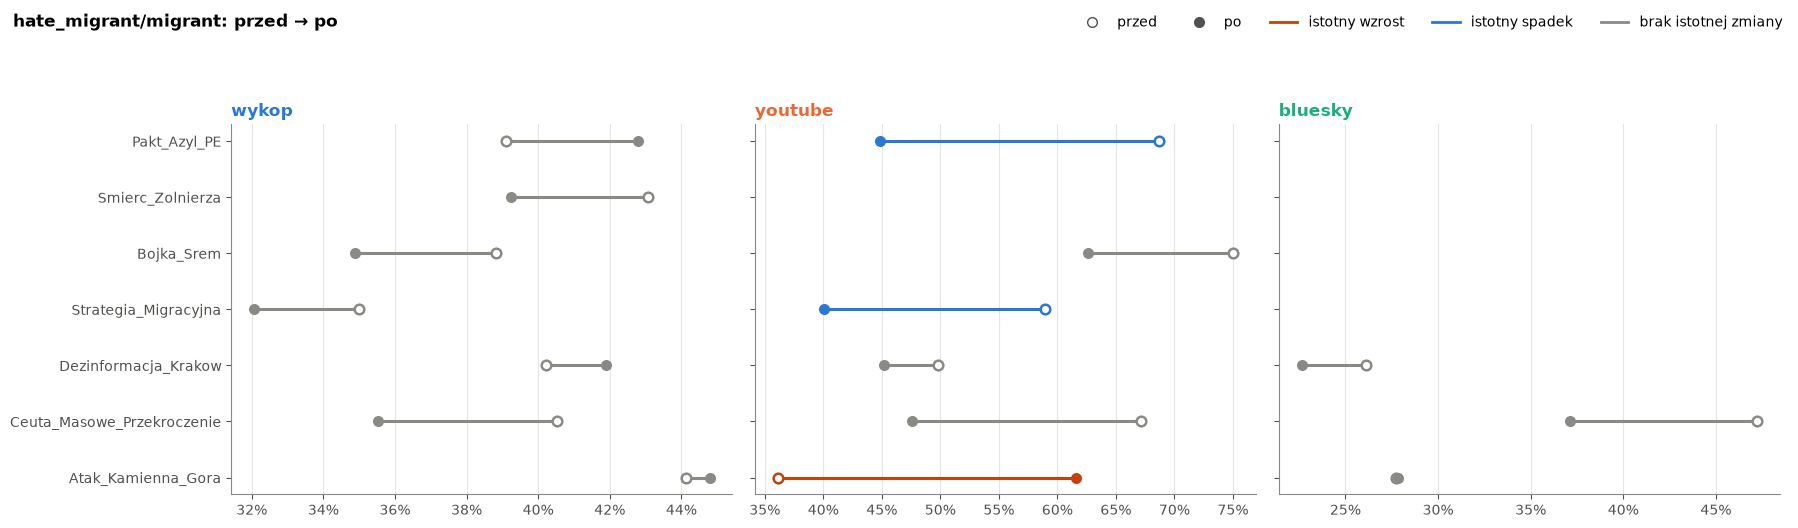

In [7]:
DIR_COLORS = {"↑": "#c2410c", "↓": "#2a78d6", "–": MUTED}
for metric in METRICS:
    fig, axes = plt.subplots(1, len(PL), figsize=(6 * len(PL), 0.5 * len(EVENT_ORDER) + 1.8), sharey=True)
    for ax, p in zip(axes, PL):
        e = E(metric)[E(metric)["platform"] == p].set_index("event").reindex(EVENT_ORDER)
        yy = np.arange(len(EVENT_ORDER))
        for yi, (ev, r) in zip(yy, e.iterrows()):
            if pd.isna(r["przed %"]):
                continue
            c = DIR_COLORS[r["kierunek"]] if isinstance(r["kierunek"], str) else MUTED
            ax.plot([r["przed %"], r["po %"]], [yi, yi], color=c, lw=2.2)
            ax.scatter(r["przed %"], yi, s=48, facecolor="white", edgecolor=c, linewidth=1.8, zorder=3)
            ax.scatter(r["po %"], yi, s=48, color=c, zorder=3)
        ax.set_yticks(yy, EVENT_ORDER)
        ax.invert_yaxis()
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}%"))
        ax.grid(axis="x", visible=True)
        ax.grid(axis="y", visible=False)
        ax.set_title(p, color=PLATFORM_COLORS[p])
    fig.suptitle(f"{metric}: przed → po", x=0.01, ha="left", fontweight="bold")
    fig.legend([plt.Line2D([], [], marker="o", ls="", ms=7, mfc="white", mec=INK2),
                plt.Line2D([], [], marker="o", ls="", ms=7, color=INK2),
                plt.Line2D([], [], color=DIR_COLORS["↑"]), plt.Line2D([], [], color=DIR_COLORS["↓"]),
                plt.Line2D([], [], color=MUTED)],
               ["przed", "po", "istotny wzrost", "istotny spadek", "brak istotnej zmiany"],
               loc="upper right", ncol=5, bbox_to_anchor=(1.0, 1.0))
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    plt.show()

**Liczby bezwzględne (średnia dzienna).** Komentarze i komentarze z hejtem wobec migrantów na dzień, przed i po.
Słupki dla wydarzenia są **skumulowane po platformach** – wysokość całego słupka to suma platform, kolory pokazują,
skąd pochodzą komentarze. Odsetków z tej sumy nie liczymy (YouTube dominuje wolumenem).

komentarze/dzień przed  komentarze/dzień po  komentarze ×  migrant/dzień przed  migrant/dzień po  migrant ×  hate_migrant/dzień przed  hate_migrant/dzień po  hate_migrant ×
wykop   Pakt_Azyl_PE                                 494.0                463.6           0.9                 76.0             136.9        1.8                      30.1                   59.2             2.0
        Smierc_Zolnierza                             427.3                503.5           1.2                179.4             206.0        1.1                      78.0                   81.7             1.0
        Bojka_Srem                                   486.9                471.0           1.0                129.1             167.2        1.3                      51.4                   58.6             1.1
        Strategia_Migracyjna                         461.0                421.6           0.9                205.3             194.2        0.9                      71.9                   62.3             0.9
        Dezinformacja_Krakow                         352.6                339.4           1.0                 92.0              94.9        1.0                      37.7                   40.3             1.1
        Ceuta_Masowe_Przekroczenie                   511.3                445.8           0.9                228.0             205.8        0.9                      92.4                   73.1             0.8
        Atak_Kamienna_Gora                           417.7                408.9           1.0                168.3             117.7        0.7                      75.0                   53.5             0.7
youtube Pakt_Azyl_PE                                5138.1               3421.9           0.7                 37.4             105.7        2.8                      25.7                   47.4             1.8
        Bojka_Srem                                  3994.1               5287.5           1.3                 78.4             123.2        1.6                      58.9                   77.1             1.3
        Strategia_Migracyjna                        3671.3               5927.0           1.6                 79.3             283.9        3.6                      46.7                  113.7             2.4
        Dezinformacja_Krakow                        2510.4               2457.1           1.0                129.3              70.6        0.5                      64.4                   31.9             0.5
        Ceuta_Masowe_Przekroczenie                  2423.0               3131.9           1.3                273.0             267.4        1.0                     183.3                  127.2             0.7
        Atak_Kamienna_Gora                          2119.0               6069.9           2.9                 61.7             304.4        4.9                      22.3                  187.4             8.4
bluesky Dezinformacja_Krakow                         425.1                417.3           1.0                 16.4              12.7        0.8                       4.3                    2.9             0.7
        Ceuta_Masowe_Przekroczenie                   437.3                443.6           1.0                 38.7              23.3        0.6                      18.3                    8.7             0.5
        Atak_Kamienna_Gora                           397.1                406.1           1.0                 14.4              14.6        1.0                       4.0                    4.1             1.0

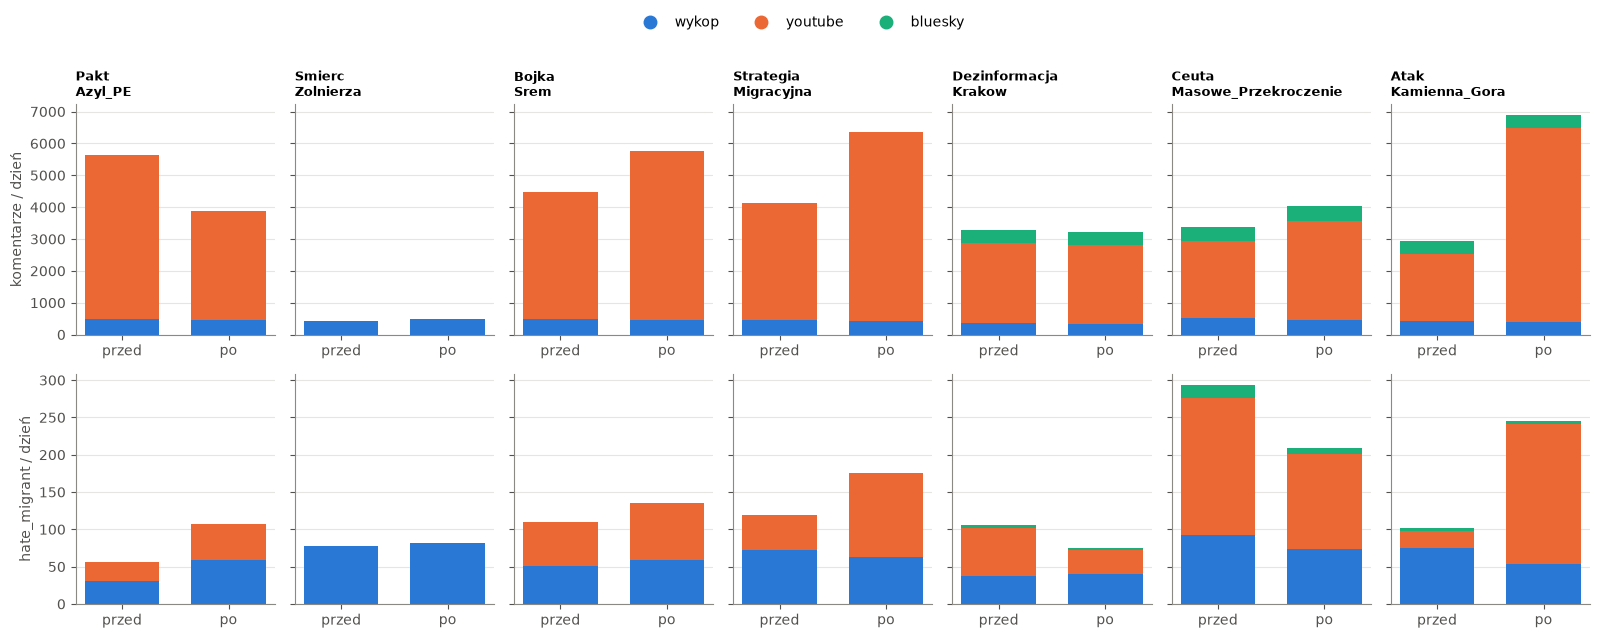

In [8]:
act = (df.groupby(["platform", "event", "okres"], sort=False)
       .agg(komentarze=("comment_id", "size"), hate_migrant=("hate_migrant", "sum"), migrant=("migrant", "sum")))
days = pd.Series({"przed": DAYS_PRE, "po": DAYS_POST})
per_day = act.div(act.index.get_level_values("okres").map(days).values, axis=0).unstack("okres")
counts_tab = pd.DataFrame(index=per_day.index)
for c in ["komentarze", "migrant", "hate_migrant"]:
    counts_tab[f"{c}/dzień przed"] = per_day[(c, "przed")]
    counts_tab[f"{c}/dzień po"] = per_day[(c, "po")]
    counts_tab[f"{c} ×"] = per_day[(c, "po")] / per_day[(c, "przed")]
counts_tab = counts_tab.reindex(pd.MultiIndex.from_tuples([tuple(c.split(":")) for c in CELLS]))
display(counts_tab.round(1))

fig, axes = plt.subplots(2, len(EVENT_ORDER), figsize=(2.3 * len(EVENT_ORDER), 6.4), sharey="row")
for j, ev in enumerate(EVENT_ORDER):
    for i, (c, lab) in enumerate([("komentarze", "komentarze / dzień"), ("hate_migrant", "hate_migrant / dzień")]):
        ax = axes[i, j]
        bottom = np.zeros(2)
        for p in PL:
            if (p, ev) not in counts_tab.index:
                continue
            v = counts_tab.loc[(p, ev), [f"{c}/dzień przed", f"{c}/dzień po"]].values.astype(float)
            ax.bar([0, 1], v, bottom=bottom, color=PLATFORM_COLORS[p], width=0.7)
            bottom += v
        ax.set_xticks([0, 1], ["przed", "po"])
        if j == 0:
            ax.set_ylabel(lab)
        if i == 0:
            ax.set_title(ev.replace("_", "\n", 1), fontsize=9)
platform_legend(fig, top=0.92)
plt.show()

Dolny rząd to średnia dzienna liczba komentarzy z hate_migrant przed i po wydarzeniu, a górny rząd to średnia dzienna liczba wszystkich komentarzy.

### 1b. Wydarzenia wspólnie dla wszystkich platform

Dla każdego wydarzenia łączymy efekty platform **meta-analizą efektów stałych** (przy 2–3 platformach model efektów
losowych jest niestabilny). Romb = łączny OR wydarzenia, kropki = poszczególne platformy.
`p Q` mówi, czy platformy w tym wydarzeniu reagowały różnie.


=== hate_migrant/all ===


,typ,platformy,k,OR,OR lo,OR hi,p,I²,p Q,p (Holm)
event,,,,,,,,,,
Pakt_Azyl_PE,polityczne,"wykop, youtube",2,2.39,1.77,3.22,1.11e-08,0.00,0.531,7.74e-08
Smierc_Zolnierza,kryminalne,wykop,1,0.87,0.65,1.15,0.327,NaN,,1
Bojka_Srem,kryminalne,"wykop, youtube",2,1.16,0.88,1.52,0.302,0.00,0.577,1
Strategia_Migracyjna,polityczne,"wykop, youtube",2,0.98,0.77,1.25,0.898,0.26,0.246,1
Dezinformacja_Krakow,dezinformacja,"wykop, youtube, bluesky",3,1.01,0.81,1.25,0.95,0.62,0.0697,1
Ceuta_Masowe_Przekroczenie,kryzys graniczny,"wykop, youtube, bluesky",3,0.76,0.62,0.94,0.01,0.70,0.036,0.0602
Atak_Kamienna_Gora,kryminalne,"wykop, youtube, bluesky",3,0.80,0.65,0.99,0.0426,0.85,0.00153,0.213



=== migrant/all ===


,typ,platformy,k,OR,OR lo,OR hi,p,I²,p Q,p (Holm)
event,,,,,,,,,,
Pakt_Azyl_PE,polityczne,"wykop, youtube",2,2.55,1.82,3.59,6.94e-08,0.44,0.181,4.86e-07
Smierc_Zolnierza,kryminalne,wykop,1,0.96,0.69,1.32,0.787,NaN,,1
Bojka_Srem,kryminalne,"wykop, youtube",2,1.44,1.09,1.92,0.0106,0.00,0.479,0.0633
Strategia_Migracyjna,polityczne,"wykop, youtube",2,1.19,0.88,1.62,0.265,0.66,0.0849,1
Dezinformacja_Krakow,dezinformacja,"wykop, youtube, bluesky",3,0.94,0.72,1.21,0.614,0.27,0.252,1
Ceuta_Masowe_Przekroczenie,kryzys graniczny,"wykop, youtube, bluesky",3,0.91,0.75,1.12,0.378,0.68,0.0432,1
Atak_Kamienna_Gora,kryminalne,"wykop, youtube, bluesky",3,0.78,0.61,1.01,0.0569,0.73,0.0247,0.284



=== hate_migrant/migrant ===


,typ,platformy,k,OR,OR lo,OR hi,p,I²,p Q,p (Holm)
event,,,,,,,,,,
Pakt_Azyl_PE,polityczne,"wykop, youtube",2,1.02,0.82,1.28,0.832,0.90,0.00151,1
Smierc_Zolnierza,kryminalne,wykop,1,0.85,0.67,1.09,0.208,NaN,,0.832
Bojka_Srem,kryminalne,"wykop, youtube",2,0.81,0.65,1.01,0.0564,0.26,0.246,0.282
Strategia_Migracyjna,polityczne,"wykop, youtube",2,0.75,0.62,0.90,0.00231,0.88,0.00425,0.0162
Dezinformacja_Krakow,dezinformacja,"wykop, youtube, bluesky",3,1.01,0.77,1.33,0.916,0.00,0.752,1
Ceuta_Masowe_Przekroczenie,kryzys graniczny,"wykop, youtube, bluesky",3,0.75,0.61,0.92,0.00648,0.25,0.265,0.0389
Atak_Kamienna_Gora,kryminalne,"wykop, youtube, bluesky",3,1.14,0.92,1.41,0.237,0.75,0.0187,0.832


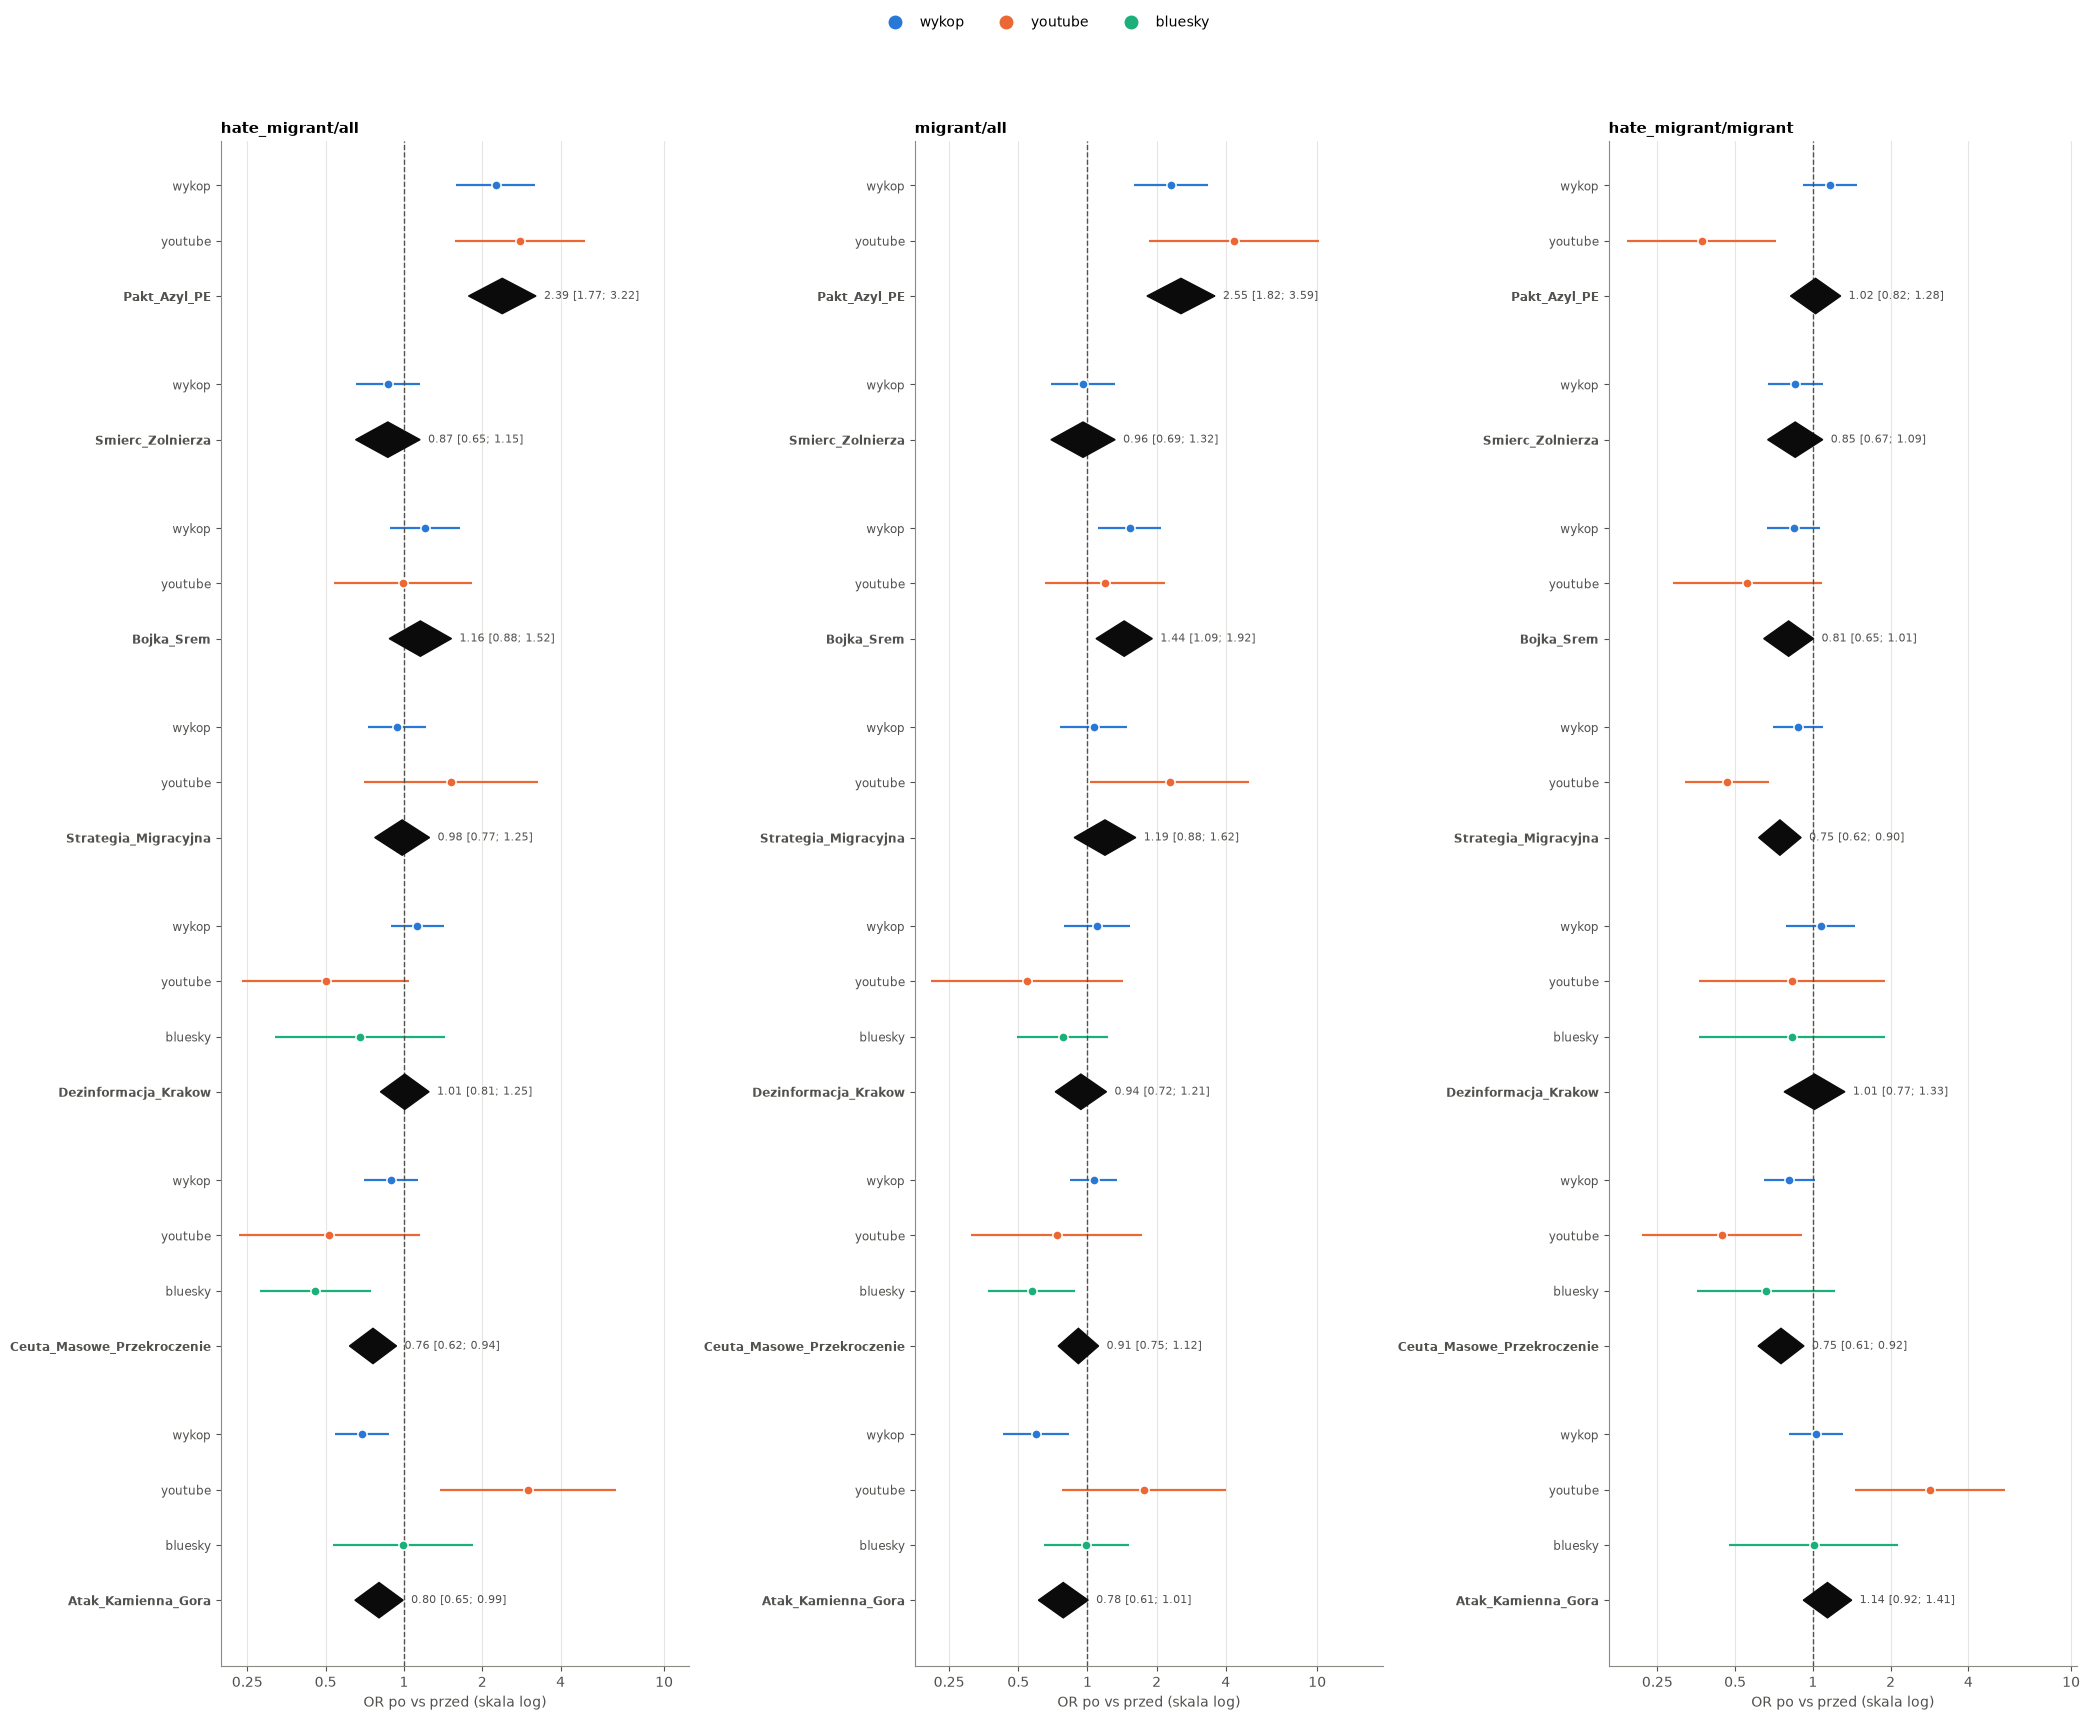

In [9]:
ev_rows = []
for metric in METRICS:
    for ev in EVENT_ORDER:
        e = E(metric)[E(metric)["event"] == ev].dropna(subset=["log OR"])
        m = meta_fixed(e["log OR"], e["se"])
        ev_rows.append({"miara": metric, "event": ev, "typ": EVENT_META[ev][0], "platformy": ", ".join(e["platform"]),
                        "k": m["k"], **or_row(m), "I²": m["I2"], "p Q": m["p Q"],
                        "mu": m["mu"], "se_mu": m["se"]})
ev_pool = pd.DataFrame(ev_rows)
ev_pool["p (Holm)"] = ev_pool.groupby("miara")["p"].transform(holm)
for metric in METRICS:
    print(f"\n=== {metric} ===")
    display(fmt_p(ev_pool[ev_pool["miara"] == metric].drop(columns=["miara", "mu", "se_mu"]).set_index("event"), 2))

fig, axes = plt.subplots(1, len(METRICS), figsize=(7 * len(METRICS), 0.62 * len(CELLS) + 0.9 * len(EVENT_ORDER) + 1))
for ax, metric in zip(axes, METRICS):
    groups = []
    for ev in EVENT_ORDER:
        e = E(metric)[E(metric)["event"] == ev].dropna(subset=["log OR"])
        r = ev_pool[(ev_pool["miara"] == metric) & (ev_pool["event"] == ev)].iloc[0]
        groups.append({"label": f"{ev}", "items": items_from(e.assign(lab="   " + e["platform"]), "lab",
                                                             lambda r_: PLATFORM_COLORS[r_["platform"]]),
                       "diamond": {"OR": r["OR"], "lo": r["OR lo"], "hi": r["OR hi"], "color": INK}})
    forest(ax, groups, title=metric)
platform_legend(fig, top=0.94)
plt.show()

Jak to czytać:

- Środek rombu (najszerszy punkt w pionie) to łączny OR. Jego wartość jest wypisana obok, np. 2.39 dla Pakt_Azyl_PE.
- Lewy i prawy wierzchołek to granice 95% przedziału ufności, czyli liczby w nawiasie [1.77; 3.22].
- Przerywana linia przy 1 oznacza brak zmiany. Jeśli cały romb leży po jednej stronie tej linii, zmiana jest istotna. Na przykład Pakt_Azyl_PE w hate_migrant/all to istotny wzrost, a Ceuta i Atak_Kamienna_Gora to istotny spadek. Romb, który przecina 1, oznacza brak istotnej zmiany.

### 1c. Przed / po wspólnie dla wydarzeń, osobno na platformę (→ H4)

Dla każdej platformy łączymy jej wydarzenia **meta-analizą efektów losowych** (DerSimonian–Laird + Hartung–Knapp).
I² i `p Q` mówią, czy wydarzenia na tej platformie działają podobnie.

In [10]:
plat_rows = []
for metric in METRICS:
    for p in PL:
        e = E(metric)[E(metric)["platform"] == p].dropna(subset=["log OR"])
        m = meta_random(e["log OR"], e["se"])
        plat_rows.append({"miara": metric, "platform": p, "wydarzeń": m["k"],
                          "wzrost w": f"{int((e['log OR'] > 0).sum())}/{len(e)}",
                          "istotnie ↑ / ↓": f"{int((e['kierunek'] == '↑').sum())} / {int((e['kierunek'] == '↓').sum())}",
                          "śr. zmiana pp": e["różnica pp"].mean(), **or_row(m), "I²": m["I2"], "p Q": m["p Q"],
                          "mu": m["mu"], "se_mu": m["se"]})
plat = pd.DataFrame(plat_rows)
display(fmt_p(plat.drop(columns=["mu", "se_mu"]).set_index(["miara", "platform"]), 2))

# poziomy dzienne pre/po (średnia z wydarzeń platformy) – tylko w obrębie platformy
lvl = (counts_tab.groupby(level=0).mean()
       [["komentarze/dzień przed", "komentarze/dzień po", "hate_migrant/dzień przed", "hate_migrant/dzień po"]]
       .reindex(PL))
print("Średnia dzienna na wydarzenie (średnia z wydarzeń platformy):")
display(lvl.round(1))

wydarzeń wzrost w istotnie ↑ / ↓  śr. zmiana pp    OR  OR lo  OR hi      p    I²       p Q
miara                platform                                                                                            
hate_migrant/all     wykop            7      3/7          1 / 1           0.05  1.05   0.74   1.47  0.761  0.83  4.97e-06
                     youtube          6      3/6          1 / 0          -0.20  1.23   0.54   2.81  0.545  0.79  0.000257
                     bluesky          3      0/3          0 / 1          -0.85  0.65   0.23   1.90  0.229  0.47     0.152
migrant/all          wykop            7      5/7          1 / 1           2.22  1.13   0.78   1.65  0.446  0.82  1.05e-05
                     youtube          6      4/6          1 / 0           0.41  1.44   0.66   3.14   0.28  0.66     0.012
                     bluesky          3      0/3          0 / 0          -1.49  0.76   0.38   1.52  0.234  0.35     0.213
hate_migrant/migrant wykop            7      3/7          0 / 0          -1.38  0.93   0.82   1.06   0.24  0.23     0.254
                     youtube          6      1/6          1 / 2          -8.98  0.67   0.31   1.48  0.252  0.81  9.95e-05
                     bluesky          3      1/3          0 / 0          -4.47  0.79   0.32   1.97  0.387  0.00     0.692

Średnia dzienna na wydarzenie (średnia z wydarzeń platformy):


,komentarze/dzień przed,komentarze/dzień po,hate_migrant/dzień przed,hate_migrant/dzień po
wykop,450.1,436.3,62.4,61.2
youtube,3309.3,4382.5,66.9,97.5
bluesky,419.9,422.3,8.9,5.2


### 1d. Przed / po wspólnie dla wydarzeń i platform (→ H1)

**Test główny H1:** meta-analiza efektów losowych ze **wszystkich komórek** (H0: łączny log-OR = 0).
**Potwierdzenie:** jeden model `y ~ po + C(komórka)` na wszystkich komentarzach z błędami klastrowanymi po wątku
(porównanie przed / po *w obrębie* komórki, ale duże komórki – YouTube – mają większą wagę).

In [11]:
all_rows = []
for metric in METRICS:
    e = E(metric).dropna(subset=["log OR"])
    m = meta_random(e["log OR"], e["se"])
    d, col = subset(df, metric)
    mod = logit_cluster(d, col, "y ~ po + C(cell)")
    b, s = mod.params["po"], mod.bse["po"]
    sign = stats.binomtest(int((e["log OR"] > 0).sum()), len(e), 0.5)
    all_rows.append({"miara": metric, "komórek": m["k"],
                     "istotnie ↑ / ↓ / –": f"{int((e['kierunek'] == '↑').sum())} / {int((e['kierunek'] == '↓').sum())} / "
                                           f"{int((e['kierunek'] == '–').sum())}",
                     "OR meta": np.exp(m["mu"]), "OR lo": np.exp(m["lo"]), "OR hi": np.exp(m["hi"]), "p meta": m["p"],
                     "I²": m["I2"], "τ²": m["tau2"],
                     "wzrost w": f"{int((e['log OR'] > 0).sum())}/{len(e)}", "p test znaków": sign.pvalue,
                     "OR model": np.exp(b), "OR model lo": np.exp(b - 1.96 * s), "OR model hi": np.exp(b + 1.96 * s),
                     "p model": mod.pvalues["po"], "mu": m["mu"], "se_mu": m["se"]})
pooled = pd.DataFrame(all_rows).set_index("miara")
display(fmt_p(pooled.drop(columns=["mu", "se_mu"]), 3))

,komórek,istotnie ↑ / ↓ / –,OR meta,OR lo,OR hi,p meta,I²,τ²,wzrost w,p test znaków,OR model,OR model lo,OR model hi,p model
miara,,,,,,,,,,,,,,
hate_migrant/all,16,2 / 2 / 12,1.024,0.770,1.363,0.86,0.793,0.139,6/16,0.454,0.988,0.784,1.245,0.917
migrant/all,16,2 / 1 / 13,1.112,0.846,1.461,0.421,0.756,0.138,9/16,0.804,1.157,0.937,1.429,0.174
hate_migrant/migrant,16,1 / 2 / 13,0.840,0.677,1.042,0.105,0.666,0.061,5/16,0.21,0.785,0.666,0.926,0.00411


**Wykres lasu H1:** wszystkie komórki (kolor = platforma) pogrupowane po platformie, z rombem każdej platformy
i rombem łącznym dla wszystkich komórek na dole (czarny).

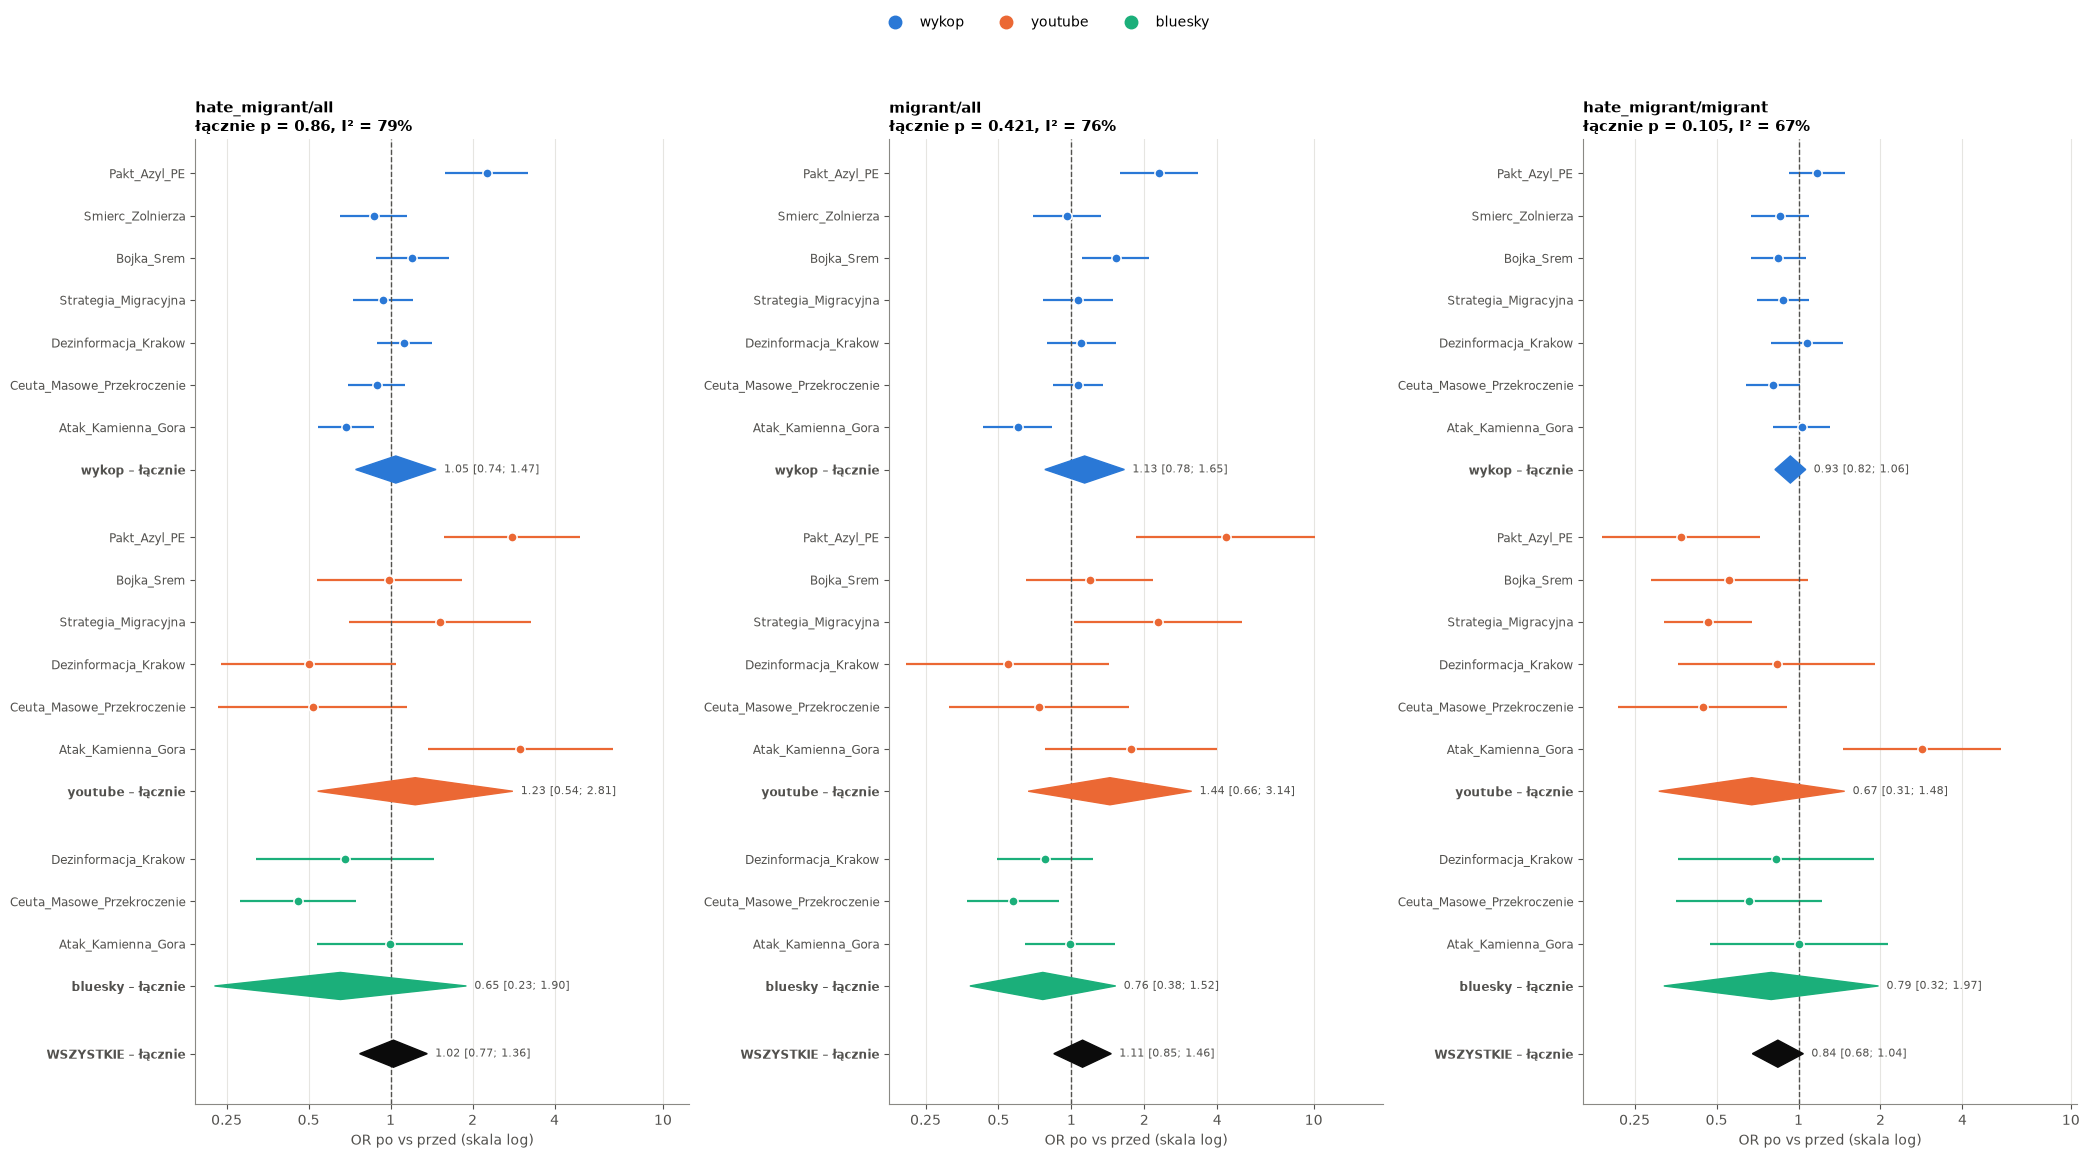

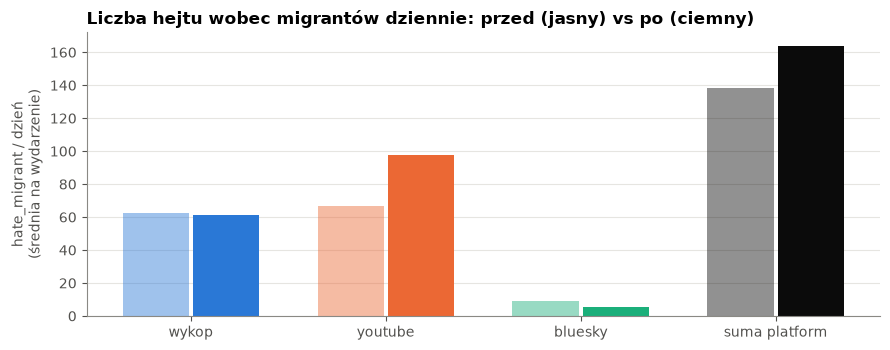

In [12]:
def platform_groups(metric, cells_filter=None):
    groups = []
    for p in PL:
        e = E(metric)[E(metric)["platform"] == p].dropna(subset=["log OR"])
        if cells_filter is not None:
            e = e[e["event"].isin(cells_filter)]
        m = meta_random(e["log OR"], e["se"])
        groups.append({"label": f"{p} – łącznie", "items": items_from(e, "event", lambda r_: PLATFORM_COLORS[r_["platform"]]),
                       "diamond": dia(m, PLATFORM_COLORS[p])})
    return groups


fig, axes = plt.subplots(1, len(METRICS), figsize=(7 * len(METRICS), 0.5 * len(CELLS) + 3.6))
for ax, metric in zip(axes, METRICS):
    r = pooled.loc[metric]
    groups = platform_groups(metric)
    groups.append({"label": "WSZYSTKIE – łącznie", "items": [],
                   "diamond": {"OR": r["OR meta"], "lo": r["OR lo"], "hi": r["OR hi"], "color": INK}})
    forest(ax, groups, title=f"{metric}\nłącznie p = {r['p meta']:.3g}, I² = {r['I²']:.0%}")
platform_legend(fig, top=0.93)
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(PL) + 1)
ax.bar(x[:-1] - 0.18, lvl["hate_migrant/dzień przed"], width=0.34, color=[PLATFORM_COLORS[p] for p in PL], alpha=0.45, label="przed")
ax.bar(x[:-1] + 0.18, lvl["hate_migrant/dzień po"], width=0.34, color=[PLATFORM_COLORS[p] for p in PL], label="po")
tot = lvl[["hate_migrant/dzień przed", "hate_migrant/dzień po"]].sum()
ax.bar(x[-1] - 0.18, tot.iloc[0], width=0.34, color=INK, alpha=0.45)
ax.bar(x[-1] + 0.18, tot.iloc[1], width=0.34, color=INK)
ax.set_xticks(x, [*PL, "suma platform"])
ax.set_ylabel("hate_migrant / dzień\n(średnia na wydarzenie)")
ax.set_title("Liczba hejtu wobec migrantów dziennie: przed (jasny) vs po (ciemny)")
plt.tight_layout()
plt.show()

Słupki platform to średnia dzienna liczba hate_migrant uśredniona po wydarzeniach danej platformy. Dla każdego wydarzenia liczymy hejt na dzień (przed: liczba / 7, po: liczba / 15), a potem bierzemy średnią z wydarzeń. Wykop to średnia z 7 wydarzeń, YouTube z 6, a Bluesky tylko z 2

### Wniosek ogólny: czy wydarzenia podnoszą hejt wobec migrantów?

Wszystkie wydarzenia i platformy razem. Komórka niżej zbiera wyniki z 1d (meta-analiza i model na komentarzach)
oraz liczby bezwzględne z 1a i drukuje werdykt dla każdej miary.

**Jak czytać wykres:** jeden panel na miarę.
- **kropki** – OR „po vs przed” poszczególnych komórek (kolor = platforma) – pokazują, jak różne są wydarzenia,
- **romb** – łączny OR z meta-analizy efektów losowych (szerokość = 95% CI) – test główny,
- **kwadrat** – OR z jednego modelu na wszystkich komentarzach (duże komórki YouTube ważą tu więcej) – potwierdzenie.

Romb / kwadrat przecinający przerywaną linię 1 = brak systematycznej zmiany.

,werdykt,komórek,OR meta,OR lo,OR hi,p meta,I²,wzrost w,istotnie ↑ / ↓ / –,OR model,OR model lo,OR model hi,p model
miara,,,,,,,,,,,,,
hate_migrant/all,BRAK systematycznej zmiany,16,1.024,0.770,1.363,0.86,0.793,6/16,2 / 2 / 12,0.988,0.784,1.245,0.917
migrant/all,BRAK systematycznej zmiany,16,1.112,0.846,1.461,0.421,0.756,9/16,2 / 1 / 13,1.157,0.937,1.429,0.174
hate_migrant/migrant,BRAK systematycznej zmiany,16,0.840,0.677,1.042,0.105,0.666,5/16,1 / 2 / 13,0.785,0.666,0.926,0.00411


hate_migrant/all (hejt wobec migrantów / wszystkie komentarze): BRAK systematycznej zmiany
    łączny OR = 1.02 [0.77; 1.36], p = 0.86; wzrost w 6/16 komórek; I² = 79% (zróżnicowanie wydarzeń)
    model na komentarzach: OR = 0.99 [0.78; 1.24], p = 0.917
migrant/all (komentarze o migracji / wszystkie komentarze): BRAK systematycznej zmiany
    łączny OR = 1.11 [0.85; 1.46], p = 0.421; wzrost w 9/16 komórek; I² = 76% (zróżnicowanie wydarzeń)
    model na komentarzach: OR = 1.16 [0.94; 1.43], p = 0.174
hate_migrant/migrant (hejt wobec migrantów / komentarze o migracji): BRAK systematycznej zmiany
    łączny OR = 0.84 [0.68; 1.04], p = 0.105; wzrost w 5/16 komórek; I² = 67% (zróżnicowanie wydarzeń)
    model na komentarzach: OR = 0.79 [0.67; 0.93], p = 0.00411 – istotny

Liczby bezwzględne (suma 16 komórek, na dzień): komentarze 24,266 → 30,616 (×1.26), hate_migrant 864 → 1,029 (×1.19)


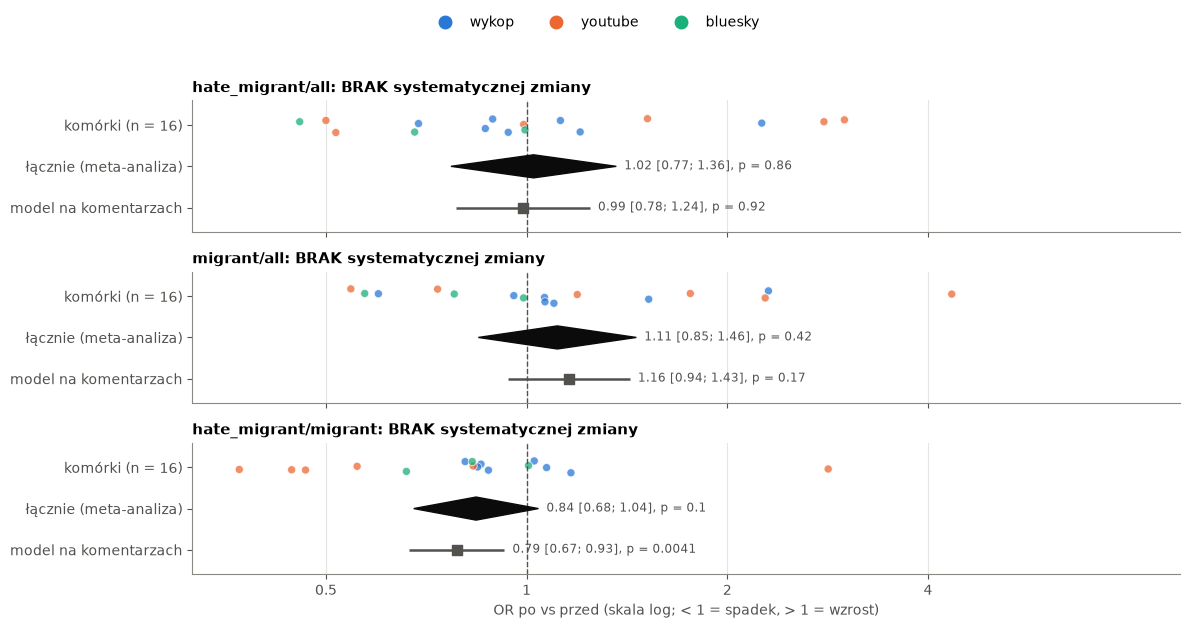

In [13]:
def overall_verdict(r):
    if r["p meta"] >= ALPHA:
        return "BRAK systematycznej zmiany"
    return "istotny WZROST" if r["OR meta"] > 1 else "istotny SPADEK"


overall = pooled[["komórek", "OR meta", "OR lo", "OR hi", "p meta", "I²", "wzrost w", "istotnie ↑ / ↓ / –",
                  "OR model", "OR model lo", "OR model hi", "p model"]].copy()
overall.insert(0, "werdykt", [overall_verdict(r) for _, r in pooled.iterrows()])
display(fmt_p(overall, 3))

for metric, r in pooled.iterrows():
    model = (f"model na komentarzach: OR = {r['OR model']:.2f} [{r['OR model lo']:.2f}; {r['OR model hi']:.2f}], "
             f"p = {r['p model']:.3g}" + (" – istotny" if r["p model"] < ALPHA else ""))
    print(f"{metric} ({METRIC_NAMES[metric]}): {overall_verdict(r)}\n"
          f"    łączny OR = {r['OR meta']:.2f} [{r['OR lo']:.2f}; {r['OR hi']:.2f}], p = {r['p meta']:.3g}; "
          f"wzrost w {r['wzrost w']} komórek; I² = {r['I²']:.0%} (zróżnicowanie wydarzeń)\n    {model}")

# liczby bezwzględne: suma po wszystkich komórkach, średnio na dzień
tot = counts_tab.sum()
print(f"\nLiczby bezwzględne (suma {len(counts_tab)} komórek, na dzień): "
      f"komentarze {tot['komentarze/dzień przed']:,.0f} → {tot['komentarze/dzień po']:,.0f} "
      f"(×{tot['komentarze/dzień po'] / tot['komentarze/dzień przed']:.2f}), "
      f"hate_migrant {tot['hate_migrant/dzień przed']:,.0f} → {tot['hate_migrant/dzień po']:,.0f} "
      f"(×{tot['hate_migrant/dzień po'] / tot['hate_migrant/dzień przed']:.2f})")

fig, axes = plt.subplots(len(METRICS), 1, figsize=(12, 1.7 * len(METRICS) + 1.2), sharex=True)
rng = np.random.default_rng(0)
xs = []
for ax, metric in zip(axes, METRICS):
    e, r = E(metric).dropna(subset=["OR"]), pooled.loc[metric]
    ax.scatter(e["OR"], 2 + rng.uniform(-0.18, 0.18, len(e)), s=34, color=e["platform"].map(PLATFORM_COLORS).tolist(),
               alpha=0.75, edgecolor="white", linewidth=0.6, zorder=2)
    ax.fill([r["OR lo"], r["OR meta"], r["OR hi"], r["OR meta"]], [1, 1.28, 1, 0.72], color=INK, zorder=3)
    ax.hlines(0, r["OR model lo"], r["OR model hi"], color=INK2, lw=1.8)
    ax.scatter(r["OR model"], 0, marker="s", s=42, color=INK2, zorder=3)
    for y, o, lo, hi, p in [(1, r["OR meta"], r["OR lo"], r["OR hi"], r["p meta"]),
                            (0, r["OR model"], r["OR model lo"], r["OR model hi"], r["p model"])]:
        ax.text(hi, y, f"  {o:.2f} [{lo:.2f}; {hi:.2f}], p = {p:.2g}", va="center", fontsize=8.5, color=INK2)
    ax.axvline(1, color=INK2, ls="--", lw=1)
    ax.set_yticks([2, 1, 0], [f"komórki (n = {len(e)})", "łącznie (meta-analiza)", "model na komentarzach"])
    ax.set_ylim(-0.6, 2.6)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_title(f"{metric}: {overall_verdict(r)}", fontsize=10.5)
    xs += [*e["OR"], r["OR lo"], r["OR hi"], r["OR model lo"], r["OR model hi"]]
axes[-1].set_xscale("log")
axes[-1].set_xlim(min(xs) * 0.85, max(xs) * 2.2)
log_ticks(axes[-1], "x")
axes[-1].set_xlabel("OR po vs przed (skala log; < 1 = spadek, > 1 = wzrost)")
platform_legend(fig, top=0.9)
plt.show()

### 1f. Test H4: czy efekt wydarzeń różni się między platformami?

- **Test główny:** różnica podgrup w meta-analizie – czy łączne efekty platform (1c) różnią się bardziej niż przez
  przypadek (statystyka Q między platformami).
- **Model z interakcją:** `y ~ po + po:C(platforma) + C(komórka)`, test Walda wszystkich interakcji `po:platforma`.
- **Pary platform:** stosunek OR (ROR = OR A / OR B) z łącznych efektów platform, korekta Holma dla par.
  ROR > 1 = po wydarzeniach odsetek na platformie A zmienia się bardziej „w górę” niż na B (nie: „na A jest więcej hejtu”).
- **Zbalansowany panel (3 platformy):** test Q i Wald tylko na wydarzeniach wspólnych dla **wszystkich** platform
  (Dezinformacja_Krakow, Ceuta, Atak_Kamienna_Gora) – różnica nie wynika z różnych zestawów wydarzeń.
- **Wspólne wydarzenia pary:** każdą parę platform porównujemy na wydarzeniach, które mają **obie** platformy
  tej pary. Dla wykop / youtube to 6 wydarzeń (wszystkie poza Smierc_Zolnierza), dla par z Bluesky – 3.

Porównujemy **wielkość zmiany**, nie poziomy.

In [14]:
def wald(d, col, formula, keep):
    """Test Walda dla współczynników, których nazwy spełniają keep(name); logit z klastrami po wątku."""
    m = logit_cluster(d, col, formula)
    idx = [i for i, n in enumerate(m.params.index) if keep(n)]
    return float(m.wald_test(np.eye(len(m.params))[idx], scalar=True).pvalue), m


def pair_events(a, b):
    # wydarzenia, które mają komórkę na obu platformach pary
    return [e for e in EVENT_ORDER if f"{a}:{e}" in CELLS and f"{b}:{e}" in CELLS]


def platform_meta(metric, events=None):
    out = {}
    for p in PL:
        e = E(metric)[E(metric)["platform"] == p].dropna(subset=["log OR"])
        if events is not None:
            e = e[e["event"].isin(events)]
        out[p] = meta_random(e["log OR"], e["se"])
    return out


h4_rows, ror_rows = [], []
for metric in METRICS:
    pm = platform_meta(metric)
    q, pq = q_test([pm[p]["mu"] for p in PL], [pm[p]["se"] for p in PL])
    pmb = platform_meta(metric, COMMON_EVENTS)
    qb, pqb = q_test([pmb[p]["mu"] for p in PL], [pmb[p]["se"] for p in PL])
    d, col = subset(df, metric)
    pw, mw = wald(d, col, "y ~ po + po:C(platform) + C(cell)", lambda n: n.startswith("po:C(platform)"))
    pwb, _ = wald(d[d["event"].isin(COMMON_EVENTS)], col, "y ~ po + po:C(platform) + C(cell)",
                  lambda n: n.startswith("po:C(platform)"))
    h4_rows.append({"miara": metric, "Q między platformami": q, "p Q (wszystkie komórki)": pq,
                    "p Q (zbalansowany panel)": pqb, "p Wald po×platforma": pw, "p Wald (zbalansowany)": pwb,
                    **{f"OR {p}": np.exp(pm[p]["mu"]) for p in PL},
                    **{f"OR {p} (panel)": np.exp(pmb[p]["mu"]) for p in PL}})
    for a, b in combinations(PL, 2):
        pe = pair_events(a, b)
        pmp = platform_meta(metric, pe)
        for scope, mm in [("wszystkie komórki", pm), ("wspólne wydarzenia pary", pmp)]:
            dlt, s = mm[a]["mu"] - mm[b]["mu"], np.hypot(mm[a]["se"], mm[b]["se"])
            ror_rows.append({"miara": metric, "zakres": scope, "para": f"{a} / {b}",
                             "wydarzeń": f"{mm[a]['k']} / {mm[b]['k']}", "ROR": np.exp(dlt),
                             "ROR lo": np.exp(dlt - 1.96 * s), "ROR hi": np.exp(dlt + 1.96 * s),
                             "p": 2 * stats.norm.sf(abs(dlt / s))})
h4 = pd.DataFrame(h4_rows).set_index("miara")
ror = pd.DataFrame(ror_rows)
ror["p (Holm)"] = ror.groupby(["miara", "zakres"])["p"].transform(holm)
print("Test H4:")
display(fmt_p(h4, 3))
print("Pary platform (ROR > 1 = silniejsza zmiana względna na pierwszej platformie):")
display(fmt_p(ror.set_index(["miara", "zakres", "para"]), 3))

Test H4:


,Q między platformami,p Q (wszystkie komórki),p Q (zbalansowany panel),p Wald po×platforma,p Wald (zbalansowany),OR wykop,OR youtube,OR bluesky,OR wykop (panel),OR youtube (panel),OR bluesky (panel)
miara,,,,,,,,,,,
hate_migrant/all,3.371,0.185,0.567,0.0117,0.121,1.045,1.231,0.654,0.883,0.917,0.654
migrant/all,4.963,0.0836,0.773,0.00885,0.395,1.134,1.442,0.762,0.896,0.918,0.762
hate_migrant/migrant,1.601,0.449,0.732,0.13,0.506,0.933,0.673,0.793,0.947,1.024,0.793


Pary platform (ROR > 1 = silniejsza zmiana względna na pierwszej platformie):


wydarzeń    ROR  ROR lo  ROR hi       p p (Holm)
miara                zakres                  para                                                              
hate_migrant/all     wszystkie komórki       wykop / youtube      7 / 6  0.849   0.428   1.684   0.639    0.639
                     wspólne wydarzenia pary wykop / youtube      6 / 6  0.877   0.434   1.772   0.715        1
                     wszystkie komórki       wykop / bluesky      7 / 3  1.597   0.916   2.786  0.0989    0.297
                     wspólne wydarzenia pary wykop / bluesky      3 / 3  1.349   0.771   2.361   0.294    0.882
                     wszystkie komórki       youtube / bluesky    6 / 3  1.882   0.850   4.165   0.119    0.297
                     wspólne wydarzenia pary youtube / bluesky    3 / 3  1.401   0.399   4.918   0.599        1
migrant/all          wszystkie komórki       wykop / youtube      7 / 6  0.786   0.404   1.530   0.479    0.479
                     wspólne wydarzenia pary wykop / youtube      6 / 6  0.810   0.406   1.614   0.549        1
                     wszystkie komórki       wykop / bluesky      7 / 3  1.488   0.961   2.305  0.0747    0.188
                     wspólne wydarzenia pary wykop / bluesky      3 / 3  1.176   0.717   1.929   0.521        1
                     wszystkie komórki       youtube / bluesky    6 / 3  1.892   0.967   3.702  0.0625    0.188
                     wspólne wydarzenia pary youtube / bluesky    3 / 3  1.204   0.560   2.591   0.635        1
hate_migrant/migrant wszystkie komórki       wykop / youtube      7 / 6  1.386   0.755   2.547   0.292    0.877
                     wspólne wydarzenia pary wykop / youtube      6 / 6  1.408   0.764   2.593   0.273    0.818
                     wszystkie komórki       wykop / bluesky      7 / 3  1.176   0.768   1.801   0.456    0.912
                     wspólne wydarzenia pary wykop / bluesky      3 / 3  1.193   0.761   1.871   0.441    0.883
                     wszystkie komórki       youtube / bluesky    6 / 3  0.848   0.410   1.757   0.658    0.912
                     wspólne wydarzenia pary youtube / bluesky    3 / 3  1.290   0.385   4.321   0.679    0.883

**Wykresy H4:** (lewy) wykres interakcji – indeks przed → po dla każdej platformy (przed = 1, po = łączny OR platformy
z 95% CI); (prawy) OR tych samych wydarzeń na każdej platformie obok siebie – wszystkie wydarzenia obecne na ≥ 2 platformach.

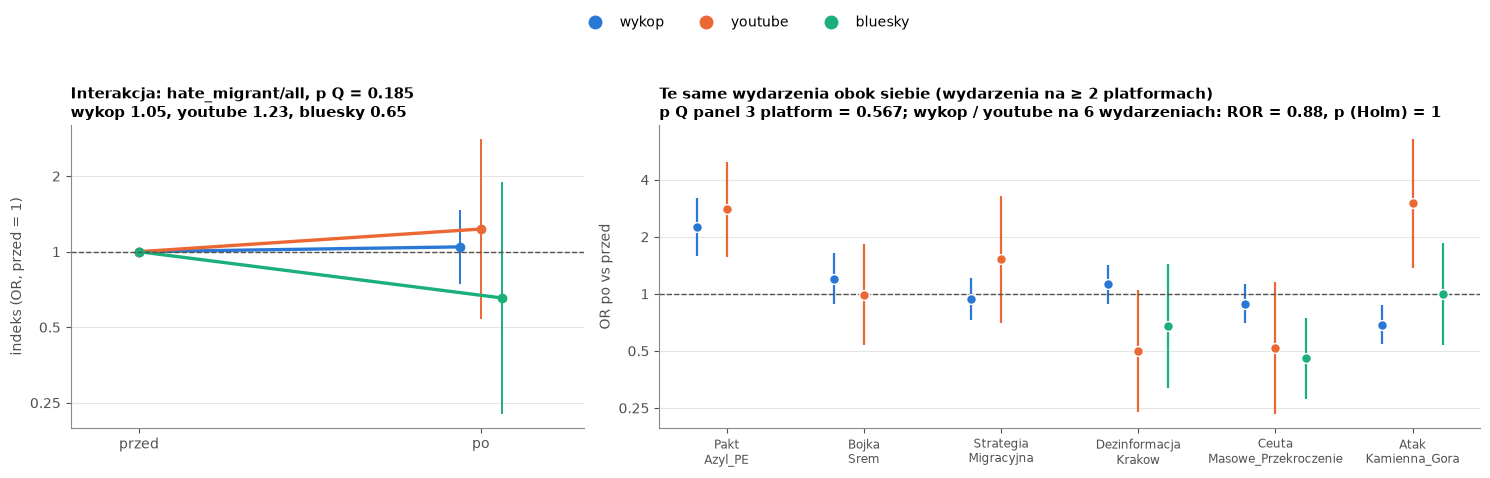

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
pm = platform_meta(MAIN)
for i, p in enumerate(PL):
    m = pm[p]
    xo = 1 + (i - 1) * 0.06
    ax.plot([0, xo], [1, np.exp(m["mu"])], color=PLATFORM_COLORS[p], lw=2.4, marker="o")
    ax.vlines(xo, np.exp(m["lo"]), np.exp(m["hi"]), color=PLATFORM_COLORS[p], lw=1.4)
ax.axhline(1, color=INK2, ls="--", lw=1)
ax.set_xticks([0, 1], ["przed", "po"])
ax.set_xlim(-0.2, 1.3)
ax.set_yscale("log")
log_ticks(ax, "y")
ax.set_ylabel("indeks (OR, przed = 1)")
ax.set_title(f"Interakcja: {MAIN}, p Q = {h4.loc[MAIN, 'p Q (wszystkie komórki)']:.3g}\n"
             + ", ".join(f"{p} {np.exp(pm[p]['mu']):.2f}" for p in PL), fontsize=11)

ax = axes[1]
shared = [e for e in EVENT_ORDER if sum(f"{p}:{e}" in CELLS for p in PL) >= 2]  # wydarzenia na ≥ 2 platformach
pos = {ev: i for i, ev in enumerate(shared)}
offs = np.linspace(-0.22, 0.22, len(PL))
for off, p in zip(offs, PL):
    e = E(MAIN)[(E(MAIN)["platform"] == p) & E(MAIN)["event"].isin(shared)].dropna(subset=["OR"])
    xx = e["event"].map(pos) + off
    ax.vlines(xx, e["OR lo"], e["OR hi"], color=PLATFORM_COLORS[p], lw=1.6)
    ax.scatter(xx, e["OR"], s=50, color=PLATFORM_COLORS[p], zorder=3, edgecolor="white")
ax.axhline(1, color=INK2, ls="--", lw=1)
ax.set_yscale("log")
log_ticks(ax, "y")
ax.set_xticks(range(len(shared)), [ev.replace("_", "\n", 1) for ev in shared], fontsize=8.5)
ax.set_ylabel("OR po vs przed")
r_wy = ror[(ror["miara"] == MAIN) & (ror["zakres"] == "wspólne wydarzenia pary") & (ror["para"] == "wykop / youtube")].iloc[0]
ax.set_title(f"Te same wydarzenia obok siebie (wydarzenia na ≥ 2 platformach)\n"
             f"p Q panel 3 platform = {h4.loc[MAIN, 'p Q (zbalansowany panel)']:.3g}; "
             f"wykop / youtube na {len(shared)} wydarzeniach: ROR = {r_wy['ROR']:.2f}, p (Holm) = {r_wy['p (Holm)']:.3g}",
             fontsize=11)
platform_legend(fig, top=0.86)
plt.show()

**Wnioski H4 (po dodaniu Bluesky / Atak_Kamienna_Gora – 16 komórek, panel 3 × 3):**

| test | `hate_migrant/all` | `migrant/all` | `hate_migrant/migrant` |
|---|---|---|---|
| Q między platformami (wszystkie komórki) | p = 0,19 | p = 0,08 | p = 0,45 |
| Q – zbalansowany panel (3 wspólne wydarzenia) | p = 0,57 | p = 0,77 | p = 0,73 |
| Wald po × platforma (wszystkie komentarze) | **p = 0,012** | **p = 0,009** | p = 0,13 |
| Wald – zbalansowany panel | p = 0,12 | p = 0,40 | p = 0,51 |
| pary platform (Holm), oba zakresy | brak istotnych | brak istotnych | brak istotnych |

- **Platformy reagują na wydarzenia podobnie** – różnice między łącznymi efektami platform (wykop 1,05, youtube 1,23,
  bluesky 0,65) mieszczą się w granicach przypadku. Żadna para platform nie różni się istotnie, także przy porównaniu
  na tych samych wydarzeniach (wykop / youtube na 6 wspólnych wydarzeniach: ROR 0,88, p = 1).
- Jedynie model Walda na wszystkich komentarzach daje p < 0,05, ale nie utrzymuje się na zbalansowanym panelu.
  Ten model waży komentarze, więc dominują go duże komórki YouTube (np. Atak_Kamienna_Gora z OR ≈ 3) – to raczej
  efekt pojedynczych wydarzeń niż platformy.
- **Większe są różnice między wydarzeniami niż między platformami:** na prawym wykresie platformy zwykle idą w tę samą
  stronę (Pakt_Azyl_PE ↑ na obu, Ceuta ↓ na wszystkich trzech). Wyjątek to Atak_Kamienna_Gora: YouTube ↑ (OR 3,0),
  Wykop ↓ (0,69), Bluesky bez zmian (0,99).
- **Werdykt H4: niepotwierdzona** (słaby sygnał tylko w jednym teście, niestabilny po zbalansowaniu).
  Dla porównania: przy 15 komórkach (bez Bluesky / Atak) Q dawał p = 0,01 – wynik zależał od jednej komórki Bluesky.

## 2. Top 3 największe zmiany na osi czasu

**Ranking:** |log RR| miary `hate_migrant/all` – największe zmiany względne w którąkolwiek stronę. Do rankingu wchodzą
tylko komórki **istotne po korekcie Holma** i z co najmniej `MIN_K_PRE_TOP` komentarzami z hejtem „przed”
(mała baza daje absurdalne RR). Jeśli takich komórek jest mniej niż 3, lista jest uzupełniana kolejnymi (nieistotnymi)
komórkami – w tytule wykresu jest wtedy dopisek *nieistotne*.

**Oś czasu:** dni −7..+14, linia przerywana = dzień 0, pozioma kropkowana = średnia „przed”. Linia = dzienny %
ze średnią kroczącą 3-dniową (dni z ≥ `MIN_DAILY_N` komentarzami w mianowniku). Szare słupki w tle = liczba
komentarzy dziennie (prawa oś) – pokazują, kiedy % jest liczony z małej próby.
Gdy na jednym wykresie jest kilka platform, oś Y to **indeks = % dzienny / średnia „przed”** (1 = bez zmiany).


wykop: top 3


,RR,RR lo,RR hi,różnica pp,p (Holm),kierunek,nieistotne
cell,,,,,,,
wykop:Pakt_Azyl_PE,2.09,1.81,2.42,6.67,8.34e-05,↑,False
wykop:Atak_Kamienna_Gora,0.73,0.66,0.81,-4.86,0.0265,↓,False
wykop:Bojka_Srem,1.18,1.05,1.32,1.88,1,–,True


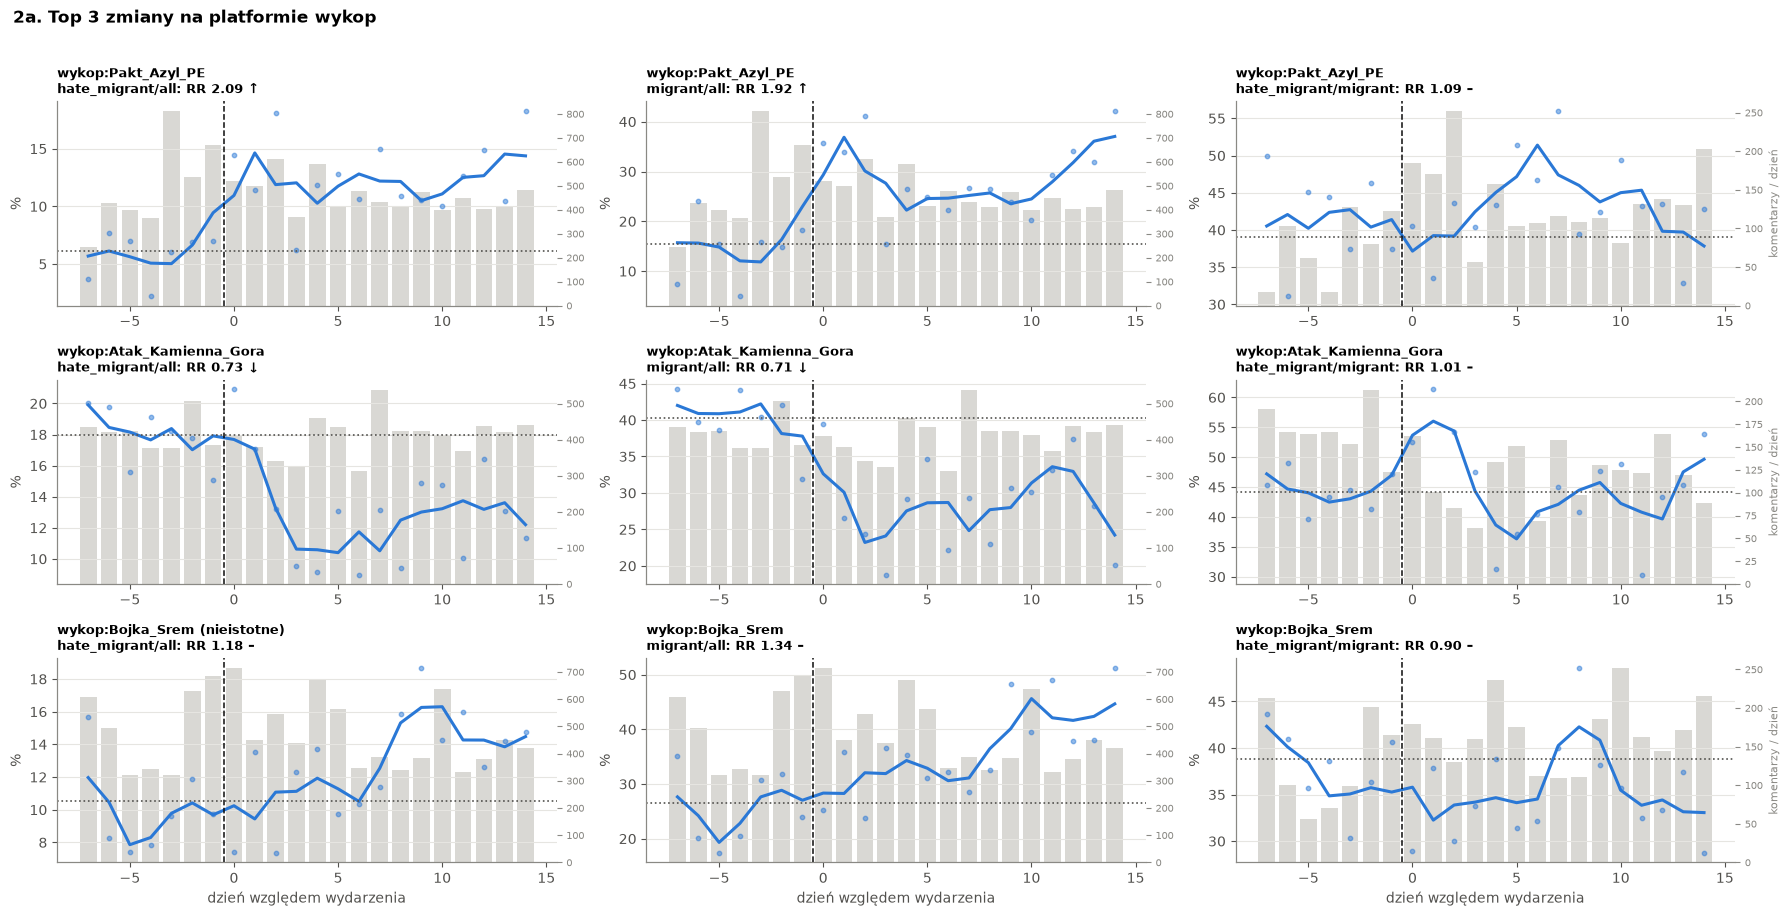


youtube: top 3


,RR,RR lo,RR hi,różnica pp,p (Holm),kierunek,nieistotne
cell,,,,,,,
youtube:Pakt_Azyl_PE,2.77,2.35,3.26,0.88,0.00686,↑,False
youtube:Atak_Kamienna_Gora,2.94,2.50,3.45,2.04,0.0716,–,True
youtube:Dezinformacja_Krakow,0.51,0.45,0.58,-1.27,0.728,–,True


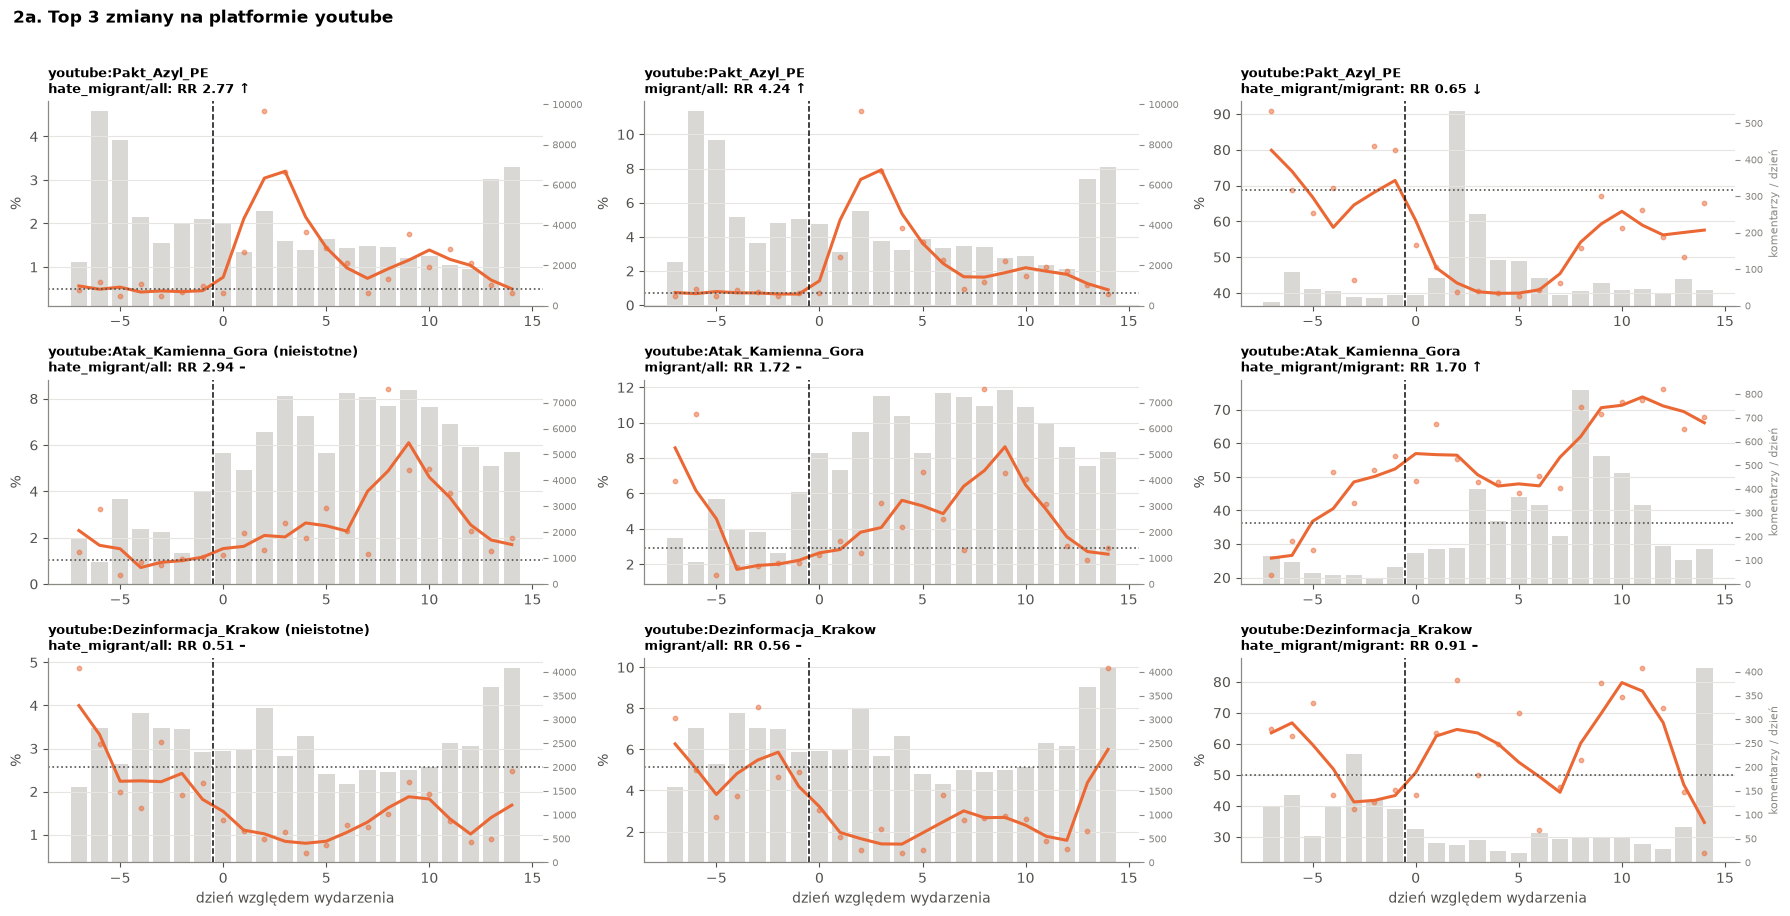


bluesky: top 3


,RR,RR lo,RR hi,różnica pp,p (Holm),kierunek,nieistotne
cell,,,,,,,
bluesky:Ceuta_Masowe_Przekroczenie,0.47,0.37,0.59,-2.23,0.025,↓,False
bluesky:Dezinformacja_Krakow,0.68,0.43,1.08,-0.32,1,–,True
bluesky:Atak_Kamienna_Gora,0.99,0.64,1.55,-0.01,1,–,True


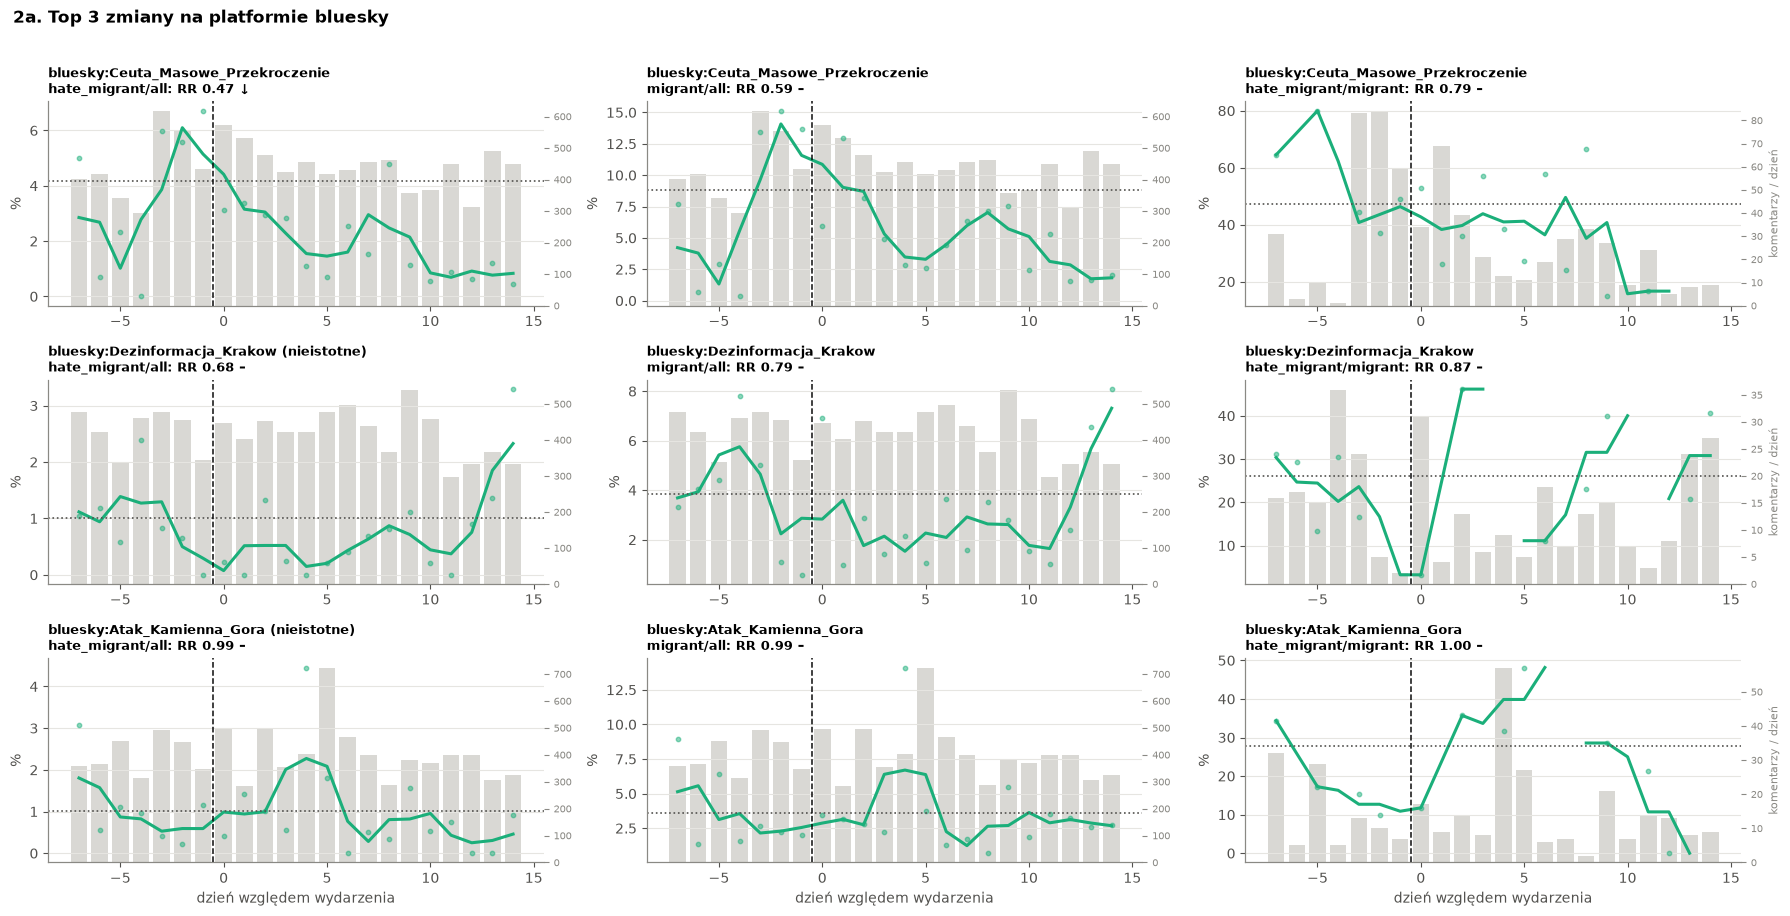

In [16]:
DAYS = range(WINDOW[0], WINDOW[1] + 1)


def daily_cell(cell, metric):
    d, col = subset(df[df["cell"] == cell], metric)
    g = d.groupby("relative_day").agg(num=(col, "sum"), den=(col, "size")).reindex(DAYS, fill_value=0)
    share = (100 * g["num"] / g["den"]).where(g["den"] >= MIN_DAILY_N)
    pre = g.loc[g.index < POST_FROM_DAY]
    base = 100 * pre["num"].sum() / max(pre["den"].sum(), 1)
    return share, base, g["den"]


def rank_cells(e):
    e = e.dropna(subset=["RR"]).assign(abs_lrr=lambda x: np.log(x["RR"]).abs())
    ok = e[e["istotne"] & (e["k przed"] >= MIN_K_PRE_TOP)].sort_values("abs_lrr", ascending=False)
    rest = e[~e.index.isin(ok.index) & (e["k przed"] >= MIN_K_PRE_TOP)].sort_values("abs_lrr", ascending=False)
    top = pd.concat([ok.assign(nieistotne=False), rest.assign(nieistotne=True)]).head(TOP_K)
    return top


def plot_cells(top, title):
    fig, axes = plt.subplots(len(top), len(METRICS), figsize=(6 * len(METRICS), 3.1 * len(top)), squeeze=False)
    for i, (_, r) in enumerate(top.iterrows()):
        for j, metric in enumerate(METRICS):
            ax = axes[i, j]
            share, base, den = daily_cell(r["cell"], metric)
            ax2 = ax.twinx()
            ax2.bar(list(DAYS), den.values, color="#d9d8d4", width=0.8, zorder=0)
            ax2.set_ylabel("komentarzy / dzień" if j == len(METRICS) - 1 else "", color=MUTED, fontsize=8)
            ax2.tick_params(axis="y", colors=MUTED, labelsize=7)
            ax2.grid(False)
            ax.set_zorder(ax2.get_zorder() + 1)
            ax.patch.set_visible(False)
            c = PLATFORM_COLORS[r["platform"]]
            ax.plot(list(DAYS), share.rolling(ROLL_DAYS, center=True, min_periods=1).mean(), color=c, lw=2.2)
            ax.scatter(list(DAYS), share.values, s=10, color=c, alpha=0.5)
            ax.axhline(base, color=INK2, ls=":", lw=1.2)
            ax.axvline(POST_FROM_DAY - 0.5, color=INK, ls="--", lw=1.1)
            ax.set_ylabel("%")
            em = E(metric).set_index("cell").loc[r["cell"]]
            tag = " (nieistotne)" if r["nieistotne"] else ""
            ax.set_title(f"{r['cell']}{tag if j == 0 else ''}\n{metric}: RR {em['RR']:.2f} {em['kierunek']}", fontsize=9.5)
            if i == len(top) - 1:
                ax.set_xlabel("dzień względem wydarzenia")
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()


rank_all = rank_cells(E(MAIN))
for p in PL:
    top = rank_cells(E(MAIN)[E(MAIN)["platform"] == p])
    print(f"\n{p}: top {TOP_K}")
    display(fmt_p(top.set_index("cell")[["RR", "RR lo", "RR hi", "różnica pp", "p (Holm)", "kierunek", "nieistotne"]], 2))
    plot_cells(top, f"2a. Top {TOP_K} zmiany na platformie {p}")

2b. Top 3 komórek ze wszystkich platform (bez łączenia):


,RR,RR lo,RR hi,różnica pp,p (Holm),kierunek,nieistotne
cell,,,,,,,
youtube:Pakt_Azyl_PE,2.77,2.35,3.26,0.88,0.00686,↑,False
bluesky:Ceuta_Masowe_Przekroczenie,0.47,0.37,0.59,-2.23,0.025,↓,False
wykop:Pakt_Azyl_PE,2.09,1.81,2.42,6.67,8.34e-05,↑,False


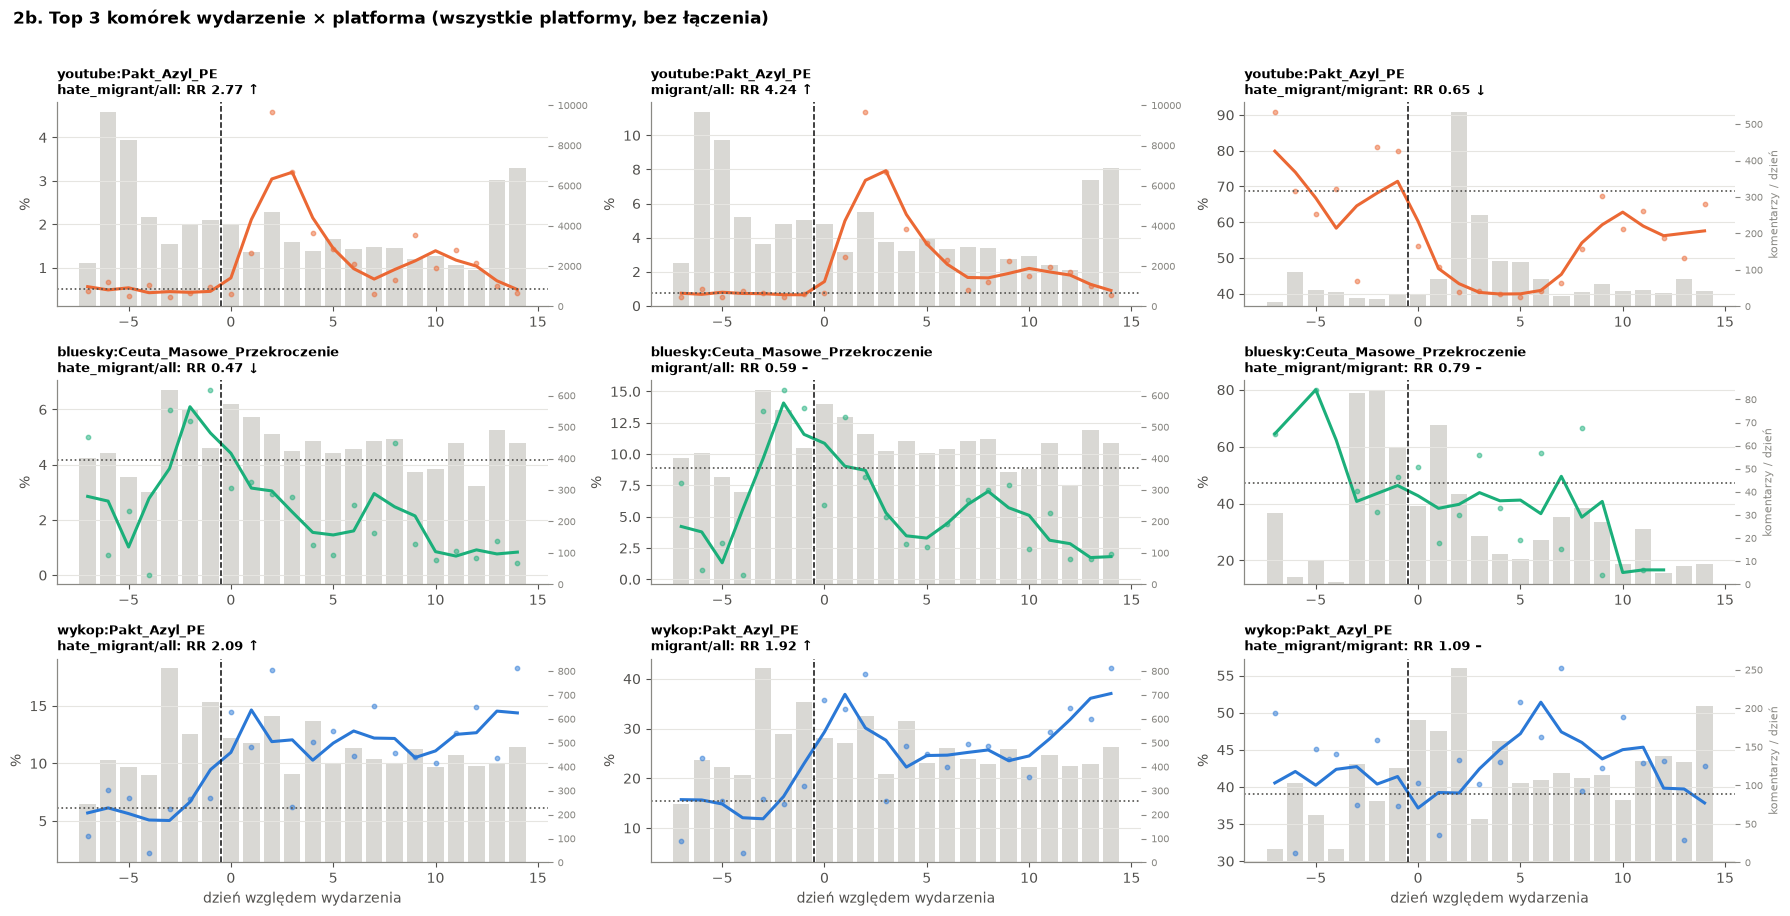

In [17]:
print(f"2b. Top {TOP_K} komórek ze wszystkich platform (bez łączenia):")
display(fmt_p(rank_all.set_index("cell")[["RR", "RR lo", "RR hi", "różnica pp", "p (Holm)", "kierunek", "nieistotne"]], 2))
plot_cells(rank_all, f"2b. Top {TOP_K} komórek wydarzenie × platforma (wszystkie platformy, bez łączenia)")

**2c. Top 3 wydarzenia łącząc platformy:** ranking po |łącznym log-OR| z widoku 1b (efekty stałe po platformach),
tylko wydarzenia z co najmniej 2 platformami. Linie = platformy, oś Y = indeks względem średniej „przed”.

,platformy,OR,OR lo,OR hi,p (Holm),nieistotne
event,,,,,,
Pakt_Azyl_PE,"wykop, youtube",2.39,1.77,3.22,7.74e-08,False
Ceuta_Masowe_Przekroczenie,"wykop, youtube, bluesky",0.76,0.62,0.94,0.0602,True
Atak_Kamienna_Gora,"wykop, youtube, bluesky",0.80,0.65,0.99,0.213,True


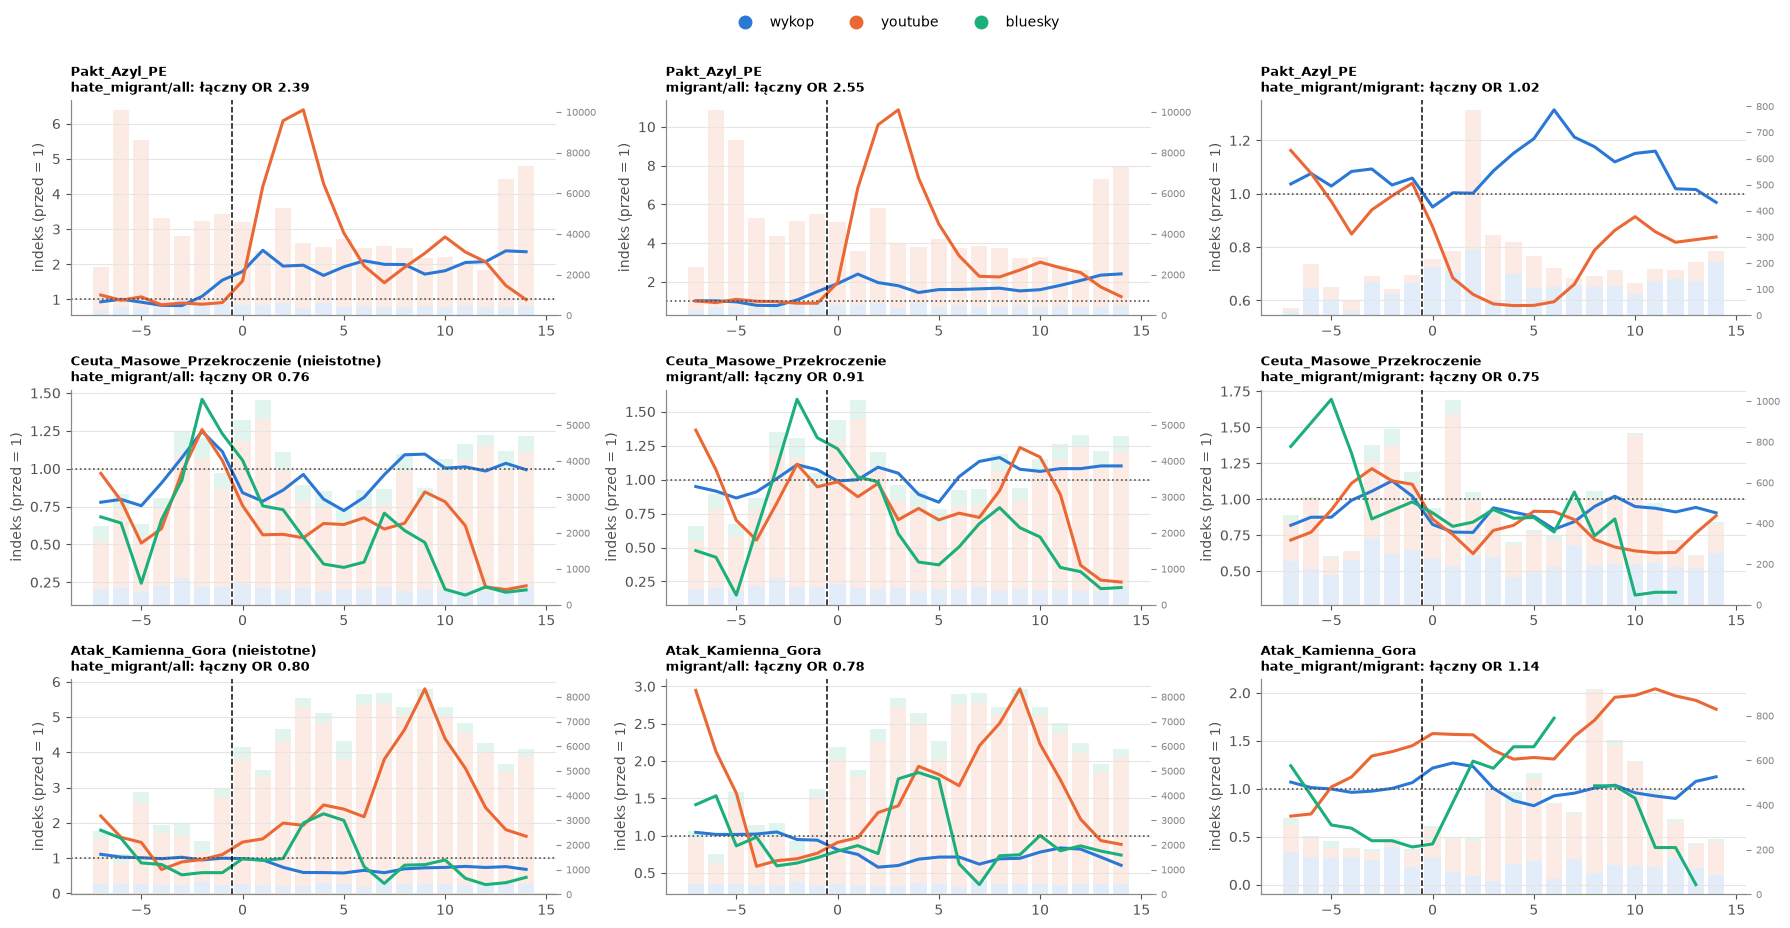

In [18]:
evp = ev_pool[(ev_pool["miara"] == MAIN) & (ev_pool["k"] >= 2)].assign(abs_mu=lambda x: x["mu"].abs())
top_ev = pd.concat([evp[evp["p (Holm)"] < ALPHA].sort_values("abs_mu", ascending=False).assign(nieistotne=False),
                    evp[evp["p (Holm)"] >= ALPHA].sort_values("abs_mu", ascending=False).assign(nieistotne=True)]).head(TOP_K)
display(fmt_p(top_ev.set_index("event")[["platformy", "OR", "OR lo", "OR hi", "p (Holm)", "nieistotne"]], 2))

fig, axes = plt.subplots(len(top_ev), len(METRICS), figsize=(6 * len(METRICS), 3.1 * len(top_ev)), squeeze=False)
for i, (_, r) in enumerate(top_ev.iterrows()):
    for j, metric in enumerate(METRICS):
        ax = axes[i, j]
        ax2 = ax.twinx()
        bottom = np.zeros(len(DAYS))
        for p in PL:
            cell = f"{p}:{r['event']}"
            if cell not in CELLS:
                continue
            share, base, den = daily_cell(cell, metric)
            idx = (share / base) if base > 0 else share * np.nan
            ax.plot(list(DAYS), idx.rolling(ROLL_DAYS, center=True, min_periods=1).mean(), color=PLATFORM_COLORS[p], lw=2.2)
            ax2.bar(list(DAYS), den.values, bottom=bottom, color=PLATFORM_COLORS[p], alpha=0.13, width=0.8)
            bottom += den.values
        ax2.grid(False)
        ax2.tick_params(axis="y", colors=MUTED, labelsize=7)
        ax.set_zorder(ax2.get_zorder() + 1)
        ax.patch.set_visible(False)
        ax.axhline(1, color=INK2, ls=":", lw=1.2)
        ax.axvline(POST_FROM_DAY - 0.5, color=INK, ls="--", lw=1.1)
        ax.set_ylabel("indeks (przed = 1)")
        em = ev_pool[(ev_pool["miara"] == metric) & (ev_pool["event"] == r["event"])].iloc[0]
        tag = " (nieistotne)" if (r["nieistotne"] and j == 0) else ""
        ax.set_title(f"{r['event']}{tag}\n{metric}: łączny OR {em['OR']:.2f}", fontsize=9.5)
platform_legend(fig, top=0.95)
plt.show()

## 3. Najczęstsze słowa w hejcie wobec migrantów (wszystkie platformy razem)

- Materiał: komentarze `hate_migrant = 1` ze wszystkich platform (bez duplikatów z nakładających się okien Wykopu).
- Przetwarzanie: małe litery, bez linków i wzmianek, tokeny ≥ 3 litery, **lematyzacja `simplemma`**, bez stop-słów.
- **Częstość:** najczęstsze lematy i bigramy w hejcie.
- **Słowa wyróżniające:** log-odds z priorytetem Dirichleta (Monroe i in. 2008) – hejt vs komentarze o migracji
  **bez** hejtu; `z` > 2 ≈ wyraźnie częstsze w hejcie.
- Panele per platforma pokazują, czy wynik nie pochodzi z jednej platformy.
- **Chmura słów:** jedna chmura z lematów hejtu ze **wszystkich platform razem** (rozmiar = liczba wystąpień).
  YouTube daje ok. 2/3 tokenów, więc to on najbardziej kształtuje chmurę.

In [19]:
STOPWORDS_PL = set("""
a aby ach acz aczkolwiek aj albo ale ależ ani aż bardziej bardzo bez bo bowiem by byli bym bynajmniej być był była było były będzie będą
cali cała cały chce chcą ci cię ciebie co cokolwiek coraz coś czasami czasem czemu czy czyli często daleko dla dlaczego dlatego do dobrze
dokąd dość dużo dwa dwaj dwie dwoje dziś dzisiaj gdy gdyby gdyż gdzie gdziekolwiek gdzieś go i ich ile im inna inne inny innych iż ja ją
jak jakaś jakby jaki jakichś jakie jakiś jakiż jakkolwiek jako jakoś je jeden jedna jedno jednak jednakże jego jej jemu jest jestem jeszcze
jeśli jeżeli już ją każdy kiedy kilka kimś kto ktokolwiek ktoś która które którego której który których którym którzy ku lat lecz lub
ma mają mam mamy mało mi mimo między mną mnie mogą moi moim moja moje może możliwe można mój mu musi my na nad nam nami nas nasi nasz nasza
nasze naszego naszych natomiast natychmiast nawet nic nich nie niech niego niej niemu nigdy nim nimi niż no o obok od około on ona one oni
ono oraz oto owszem pan pana pani po pod podczas pomimo ponad ponieważ powinien powinna powinni powinno poza prawie przecież przed przede
przedtem przez przy roku również sam sama są się skąd sobie sobą sposób swoje ta tak taka taki takie także tam te tego tej temu ten teraz
też to tobą tobie toteż trzeba tu tutaj twoi twoim twoja twoje twym twój ty tych tylko tym u w wam wami was wasz wasza wasze we według
wiele wielu więc więcej wszyscy wszystkich wszystkie wszystkim wszystko wtedy wy właśnie z za zapewne zawsze ze zł znowu znów został żaden
żadna żadne żadnych że żeby tez juz sie jak ktory ktora ktore bylo byl beda bedzie moze takze zeby ze tylko wiec niz przez tego tym jeszcze
tych tej mnie mieć mają ma mial miał było będą bylo były jakis jakies cos nikt nikogo niczego wszystkiego swój swoją swojej swoich swoim
naszym tymi takich takiej takim tamtych coś ktoś kogoś czegoś bym byś byście byśmy będę będziesz będziemy jestes jesteś jesteśmy
http https www com html pdf amp quot xd xdd xddd lenny bo tam tu oni ich sa sā też dla gdzie potem teraz chyba raczej
link user email phone mieć móc chcieć wiedzieć mówić czas rok raz ten taki który swój wszystek inny jakiś cały sam też
""".split())

URL_RE = re.compile(r"https?://\S+|www\.\S+|@\w+|\[\w+\]")
TOKEN_RE = re.compile(r"[a-ząćęłńóśźż]{3,}")
_LEMMA = {}


def lemma(t):
    if t not in _LEMMA:
        _LEMMA[t] = simplemma.lemmatize(t, lang="pl").lower()
    return _LEMMA[t]


STOP = STOPWORDS_PL | {lemma(w) for w in STOPWORDS_PL}


def tokens(text):
    toks = [lemma(t) for t in TOKEN_RE.findall(URL_RE.sub(" ", text.lower()))]
    return [t for t in toks if t not in STOP and len(t) >= 3]


def count_terms(texts):
    uni, bi = Counter(), Counter()
    for txt in texts:
        t = tokens(txt)
        uni.update(t)
        bi.update(f"{a} {b}" for a, b in zip(t, t[1:]))
    return uni, bi


def log_odds(c1, c2, prior, min_count=10):
    """Ważony log-odds ratio z informatywnym priorem Dirichleta (Monroe i in. 2008); z > 0 = częstsze w c1."""
    n1, n2, a0 = sum(c1.values()), sum(c2.values()), sum(prior.values())
    rows = []
    for w, y1 in c1.items():
        if y1 < min_count:
            continue
        a, y2 = prior[w], c2.get(w, 0)
        delta = np.log((y1 + a) / (n1 + a0 - y1 - a)) - np.log((y2 + a) / (n2 + a0 - y2 - a))
        rows.append((w, y1, y2, delta / np.sqrt(1 / (y1 + a) + 1 / (y2 + a))))
    return pd.DataFrame(rows, columns=["słowo", "n hejt", "n bez hejtu", "z"]).sort_values("z", ascending=False)


# bez duplikatów: ten sam komentarz Wykopu może należeć do dwóch nakładających się wydarzeń
uniq = df.drop_duplicates(["platform", "uid"])
hm = uniq[uniq["hate_migrant"]]
nh = uniq[uniq["migrant"] & ~uniq["hate_migrant"]]
print("komentarze z hejtem wobec migrantów:", hm.groupby("platform").size().reindex(PL).to_dict())
print("komentarze o migracji bez hejtu:", nh.groupby("platform").size().reindex(PL).to_dict())

terms = {}
for p in PL:
    terms[(p, "hejt")] = count_terms(hm.loc[hm["platform"] == p, "text"])
    terms[(p, "bez")] = count_terms(nh.loc[nh["platform"] == p, "text"])
uni_h = sum((terms[(p, "hejt")][0] for p in PL), Counter())
bi_h = sum((terms[(p, "hejt")][1] for p in PL), Counter())
uni_n = sum((terms[(p, "bez")][0] for p in PL), Counter())
bi_n = sum((terms[(p, "bez")][1] for p in PL), Counter())

komentarze z hejtem wobec migrantów: {'wykop': 9019, 'youtube': 11581, 'bluesky': 420}
komentarze o migracji bez hejtu: {'wykop': 14381, 'youtube': 10361, 'bluesky': 826}


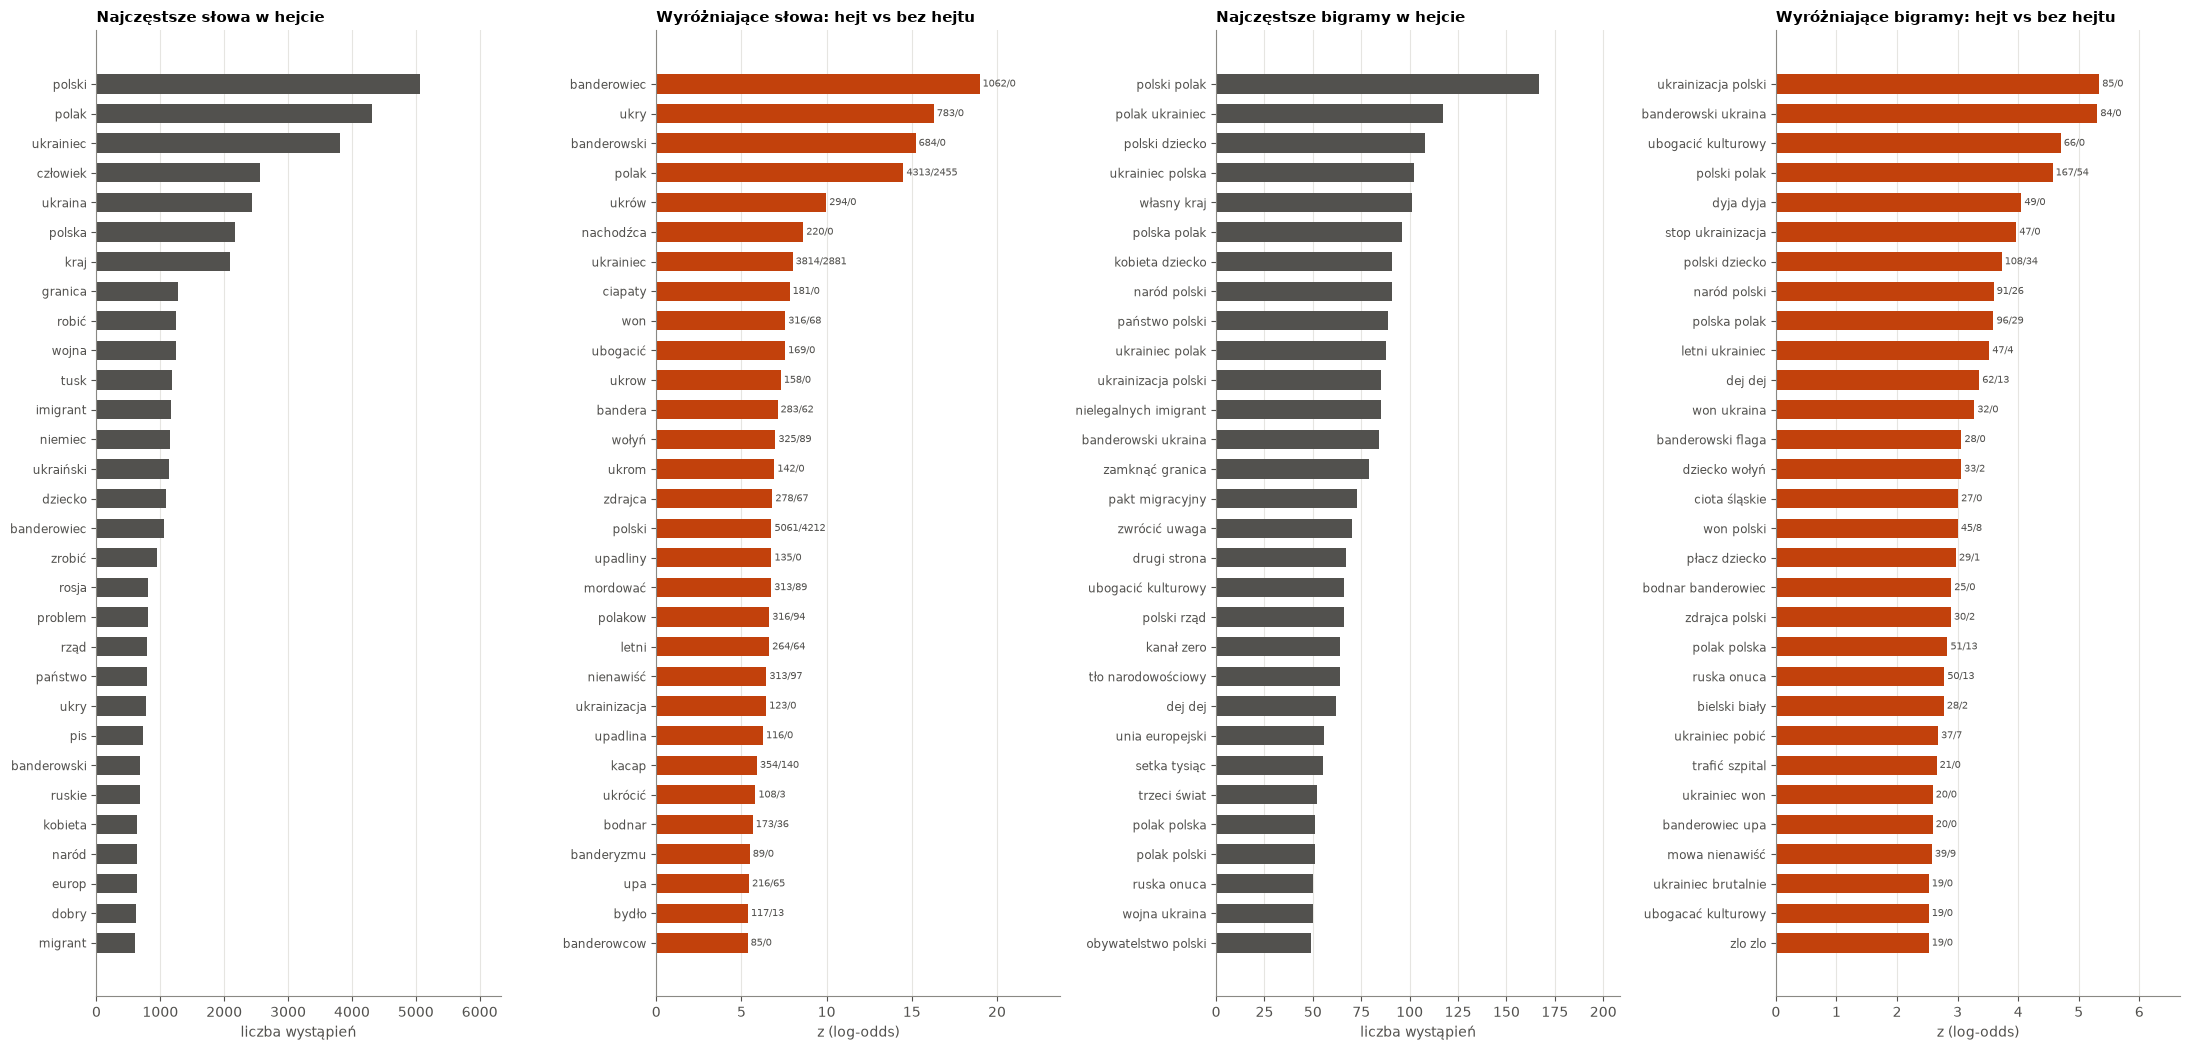

In [20]:
def barh(ax, labels, values, color, title, xlabel, notes=None):
    ax.barh(labels[::-1], values[::-1], color=color, height=0.65)
    if notes is not None:
        for yi, (v, n) in enumerate(zip(values[::-1], notes[::-1])):
            ax.text(v, yi, f" {n}", va="center", color=INK2, fontsize=7.5)
    ax.margins(x=0.25)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.tick_params(axis="y", labelsize=8.5)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(xlabel)


fig, axes = plt.subplots(1, 4, figsize=(22, 0.3 * TOP_N_WORDS + 1.6))
for ax, (c_h, c_n, kind) in zip([axes[:2], axes[2:]], [(uni_h, uni_n, "słowa"), (bi_h, bi_n, "bigramy")]):
    top = c_h.most_common(TOP_N_WORDS)
    barh(ax[0], [w for w, _ in top], [n for _, n in top], INK2, f"Najczęstsze {kind} w hejcie", "liczba wystąpień")
    lo_ = log_odds(c_h, c_n, c_h + c_n, min_count=10 if kind == "słowa" else 5).head(TOP_N_WORDS)
    barh(ax[1], lo_["słowo"].tolist(), lo_["z"].tolist(), "#c2410c", f"Wyróżniające {kind}: hejt vs bez hejtu",
         "z (log-odds)", notes=[f"{a}/{b}" for a, b in zip(lo_["n hejt"], lo_["n bez hejtu"])])
plt.tight_layout()
plt.show()

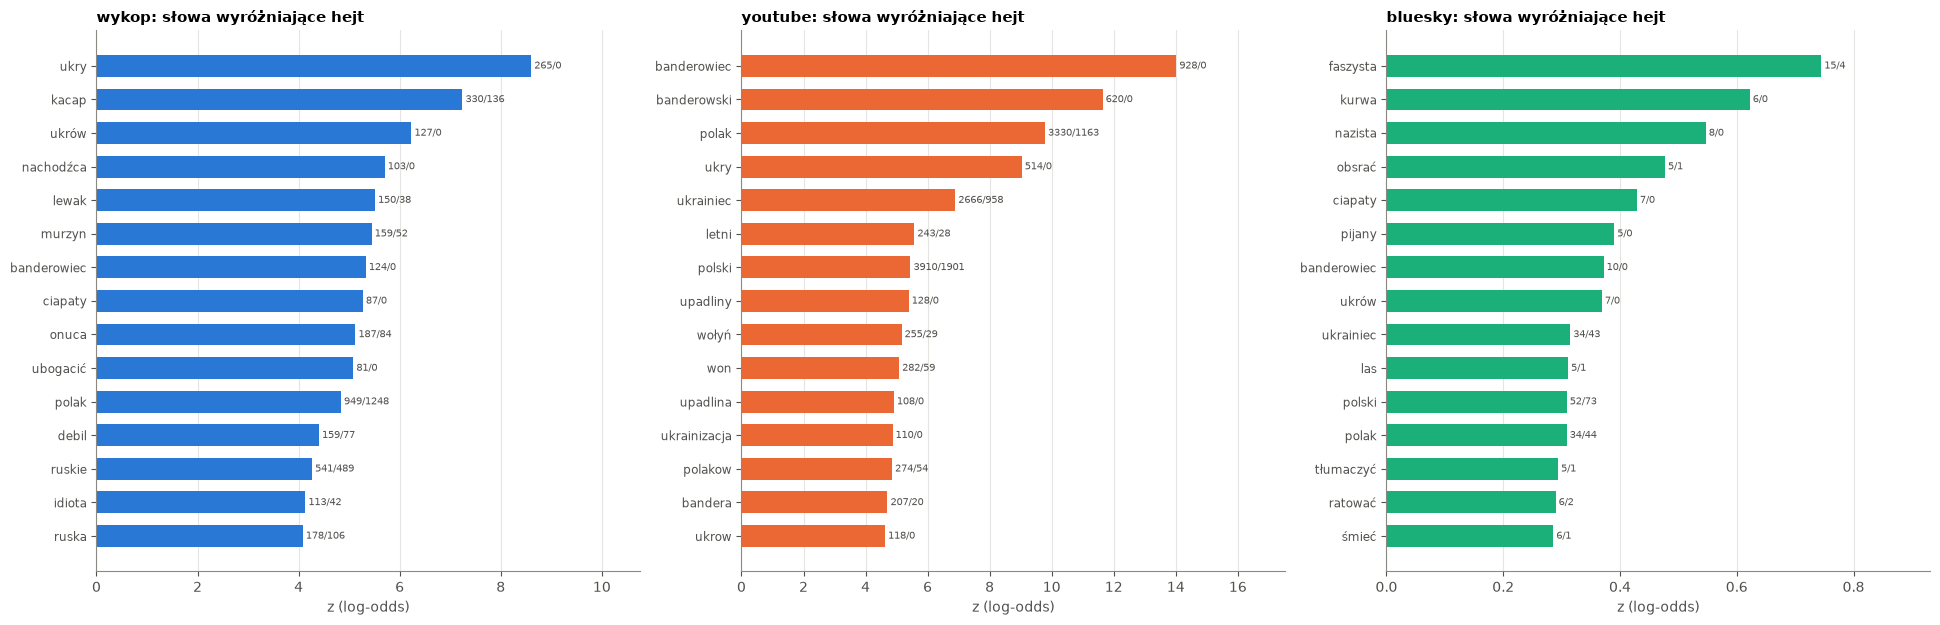

Udział platform w puli słów hejtu (tokeny): {'wykop': '35%', 'youtube': '64%', 'bluesky': '1%'}


In [21]:
TOP_PER_PL = 15
fig, axes = plt.subplots(1, len(PL), figsize=(6.5 * len(PL), 0.33 * TOP_PER_PL + 1.4))
for ax, p in zip(axes, PL):
    c_h, c_n = terms[(p, "hejt")][0], terms[(p, "bez")][0]
    lo_ = log_odds(c_h, c_n, uni_h + uni_n, min_count=5).head(TOP_PER_PL)
    barh(ax, lo_["słowo"].tolist(), lo_["z"].tolist(), PLATFORM_COLORS[p],
         f"{p}: słowa wyróżniające hejt", "z (log-odds)", notes=[f"{a}/{b}" for a, b in zip(lo_["n hejt"], lo_["n bez hejtu"])])
plt.tight_layout()
plt.show()

print("Udział platform w puli słów hejtu (tokeny):",
      {p: f"{100 * sum(terms[(p, 'hejt')][0].values()) / sum(uni_h.values()):.0f}%" for p in PL})

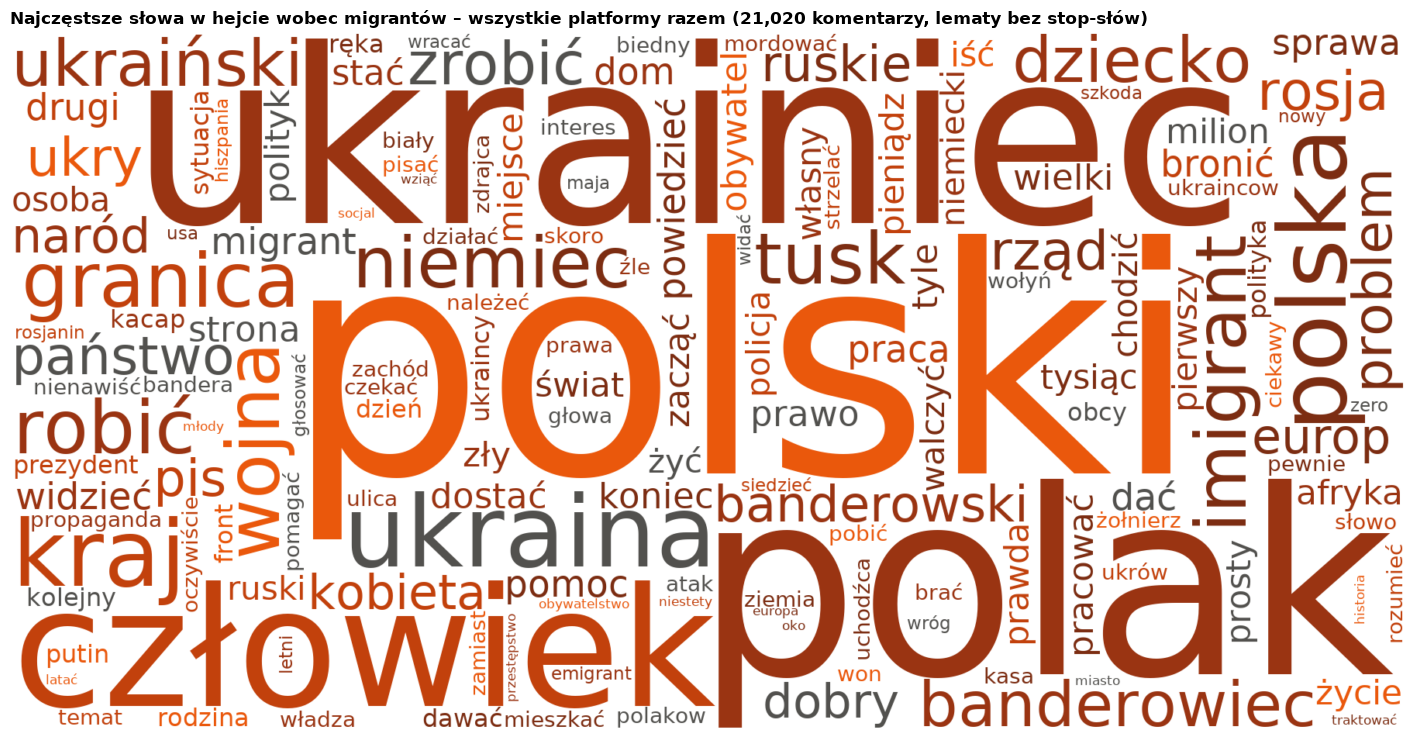

In [22]:
HATE_SHADES = ["#7c2d12", "#9a3412", "#c2410c", "#ea580c", "#52514e"]


def hate_color(word, font_size, position, orientation, random_state=None, **kw):
    return random_state.choice(HATE_SHADES)


wc = WordCloud(width=1800, height=900, background_color="white", max_words=150, prefer_horizontal=0.95,
               font_path=font_manager.findfont("DejaVu Sans"), color_func=hate_color, random_state=0,
               margin=4).generate_from_frequencies(dict(uni_h.most_common(400)))
fig, ax = plt.subplots(figsize=(15, 7.5))
ax.imshow(wc, interpolation="bilinear")
ax.axis("off")
ax.set_title(f"Najczęstsze słowa w hejcie wobec migrantów – wszystkie platformy razem "
             f"({len(hm):,} komentarzy, lematy bez stop-słów)")
plt.tight_layout()
plt.show()

## 4. Kogo obrażano i jakimi obelgami

**Grupy docelowe:** słowa kluczowe (`TARGET_GROUPS`, jak w poprzednich notebookach) w komentarzach `hate_migrant = 1`.
Komentarz może trafić do kilku grup; osobno pokazujemy, ile komentarzy nie wskazuje żadnej grupy.

**Kategorie obelg:** leksykon `src/lexicon/slurs.py` uruchomiony na tekstach `hate_migrant = 1` ze wszystkich platform
(dla YouTube nie ma etapu `slurs/`, więc liczymy tutaj). 15 kategorii zwiniętych do 6 grup. Leksykon łapie tylko część
hejtu – **pokrycie** (drukowane nad wykresem) mówi, jaki % komentarzy z hejtem zawiera **jakikolwiek** termin
z leksykonu. Kategorie na mapie to % **wszystkich** komentarzy z hejtem (nie tylko pokrytych), więc żadna nie może
przekroczyć pokrycia, a reszta to hejt bez słownikowych obelg (np. „niech wracają do siebie”, sarkazm, groźby
opisowe). Pokrycie różni się między platformami, więc porównując kategorie między platformami, lepiej patrzeć na ich
proporcje do pokrycia niż na same procenty.

Wartości = % komentarzy z hejtem wobec migrantów (cały okres −7..+14). Wiersze per wydarzenie łączą platformy
(liczone na komentarzach, więc większa platforma waży więcej – `n` podane w etykiecie).

Pokrycie leksykonem (% komentarzy z hejtem, w których jest ≥ 1 termin z leksykonu): wykop 20%, youtube 42%, bluesky 13%


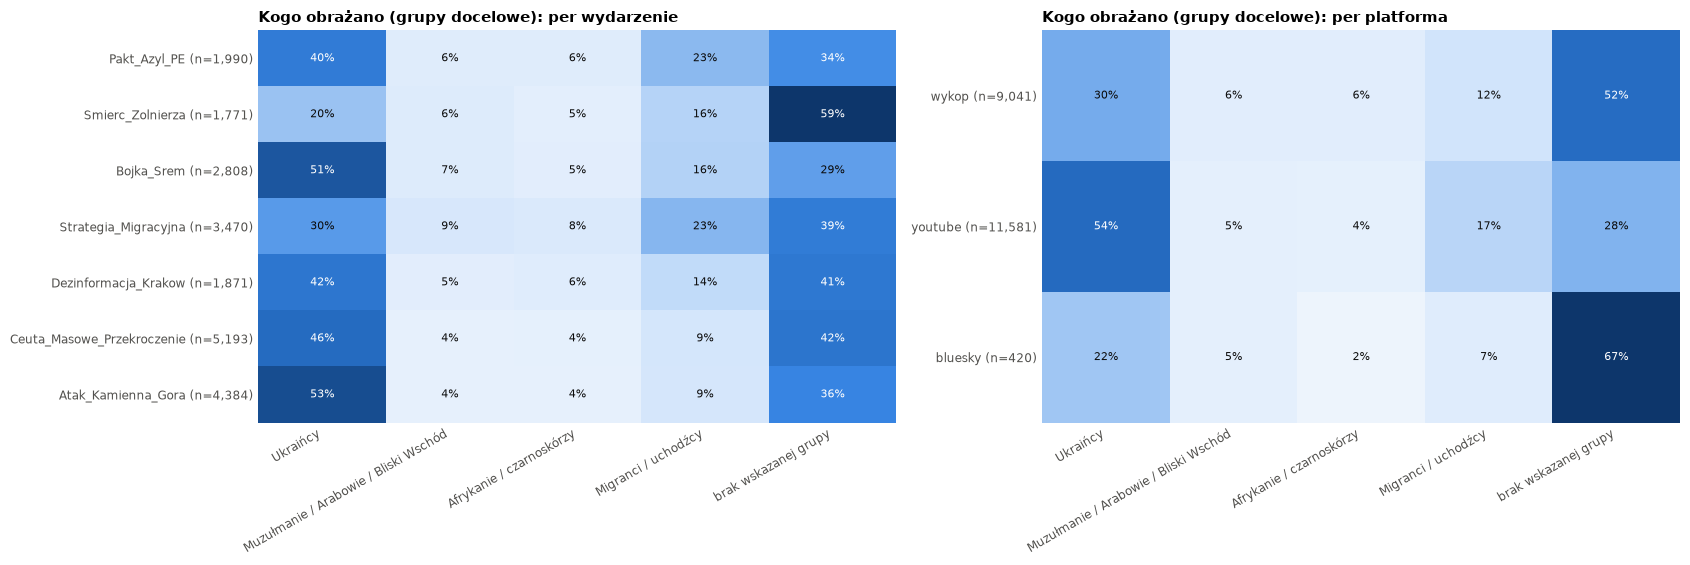

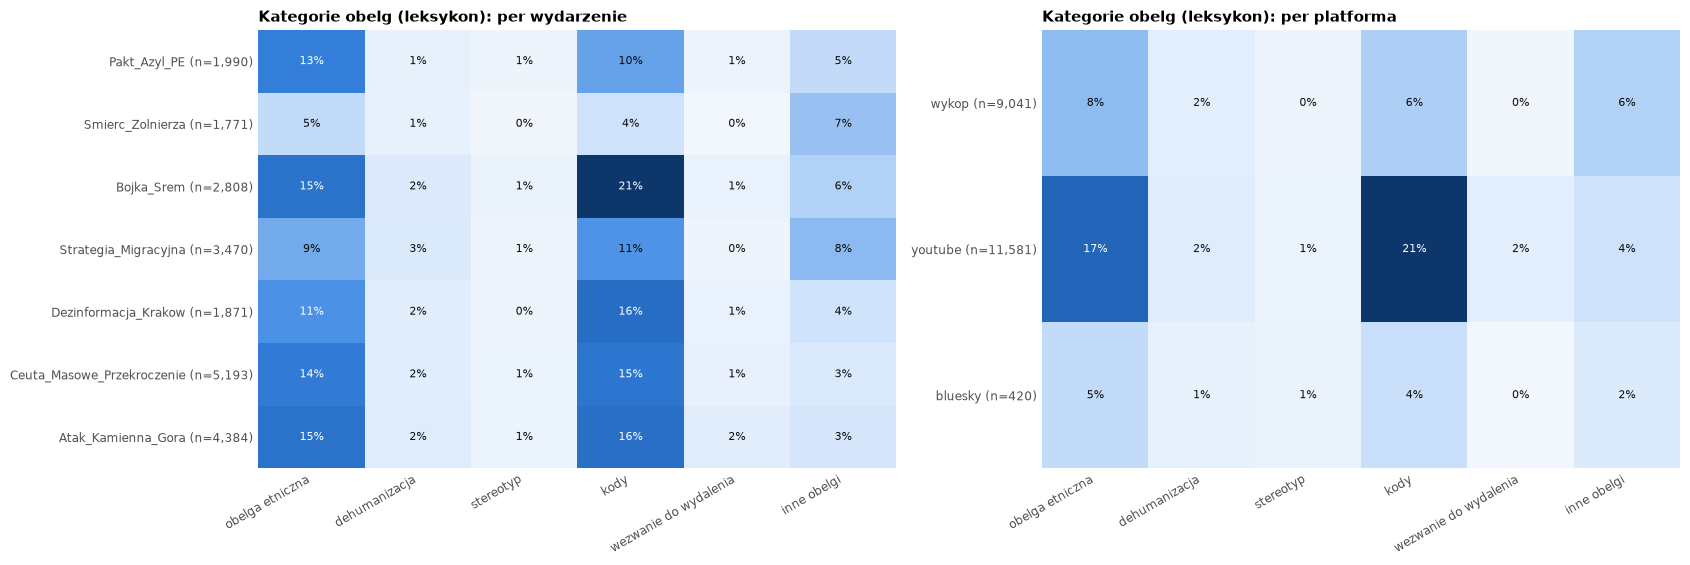

In [23]:
TARGET_GROUPS = {
    "Ukraińcy": r"ukrai|ukraiń|\bukr|ukrop|bander|\bupa\b|upain|upowc|slava|sława|chachoł|chochoł",
    "Muzułmanie / Arabowie / Bliski Wschód": r"muzu?ł?m|muslim|islam|arab|allah|ciap|kozoj|talib|afga|syryj|syri|irak|turk|turc|pakist|czeczen|kebab|szariat|meczet",
    "Afrykanie / czarnoskórzy": r"murzyn|afryk|czarn|bambus|asfalt|nigeri|somal|erytre|małp|malp",
    "Migranci / uchodźcy (ogólnie)": r"migran|imigran|uchodź|uchodz|nachodź|nachodz|najeźdź|najezdz|relokac|azyl|ubogac|nielegal|przybysz|inwazj",
}
SLUR_GROUPS = {
    "obelga etniczna": ["obelga_etniczna", "obelga_etniczna_zlozenie", "obelga_historyczna"],
    "dehumanizacja": ["dehumanizacja"],
    "stereotyp": ["stereotyp", "stereotyp_swiadczenia", "stereotyp_seksistowski"],
    "kody": ["kod", "kod_historyczny", "kod_ironiczny", "kod_spiskowy", "kod_inwazji", "kod_prorosyjski"],
    "wezwanie do wydalenia": ["wezwanie_do_wydalenia"],
    "inne obelgi": ["obelga"],
}
CAT2GROUP = {c: g for g, cs in SLUR_GROUPS.items() for c in cs}

hm_ev = df[df["hate_migrant"]].copy()  # per wydarzenie (z ewentualnymi duplikatami między wydarzeniami)
low = hm_ev["text"].str.lower()
tg = pd.DataFrame({g: low.str.contains(rx, regex=True) for g, rx in TARGET_GROUPS.items()}, index=hm_ev.index)
tg["brak wskazanej grupy"] = ~tg.any(axis=1)

found = hm_ev["text"].map(find_slurs)
sg = pd.DataFrame({g: found.map(lambda ts, g=g: any(CAT2GROUP.get(t.category) == g for t in ts)) for g in SLUR_GROUPS},
                  index=hm_ev.index)
unknown = {t.category for ts in found for t in ts} - set(CAT2GROUP)
if unknown:
    print("kategorie spoza mapowania:", unknown)
for t in [tg, sg]:
    t[["platform", "event", "uid"]] = hm_ev[["platform", "event", "uid"]]

coverage = (hm_ev.assign(pokryte=found.map(bool)).drop_duplicates(["platform", "uid"])
            .groupby("platform")["pokryte"].mean().reindex(PL))
print("Pokrycie leksykonem (% komentarzy z hejtem, w których jest ≥ 1 termin z leksykonu):",
      ", ".join(f"{p} {100 * v:.0f}%" for p, v in coverage.items()))


def share_tab(t, by, order):
    cols = [c for c in t.columns if c not in ("platform", "event", "uid")]
    if by == "platform":  # per platforma bez duplikatów z nakładających się okien
        t = t.drop_duplicates(["platform", "uid"])
    tab = 100 * t.groupby(by)[cols].mean().reindex(order)
    n = t.groupby(by).size().reindex(order)
    tab.index = [f"{i} (n={int(k):,})" for i, k in zip(tab.index, n)]
    return tab


def heat(ax, tab, title):
    vmax = np.nanmax(tab.values)
    ax.imshow(tab.values, cmap=BLUES, aspect="auto", vmin=0, vmax=vmax)
    for (i, j), v in np.ndenumerate(tab.values):
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="white" if v > 0.55 * vmax else INK)
    ax.set_xticks(range(tab.shape[1]), [c.split(" (")[0] for c in tab.columns], rotation=30, ha="right", fontsize=8.5)
    ax.set_yticks(range(len(tab)), tab.index, fontsize=8.5)
    ax.grid(False)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title, fontsize=11)


for t, name in [(tg, "Kogo obrażano (grupy docelowe)"), (sg, "Kategorie obelg (leksykon)")]:
    fig, axes = plt.subplots(1, 2, figsize=(17, 0.45 * len(EVENT_ORDER) + 2.6), gridspec_kw={"width_ratios": [1, 1]})
    heat(axes[0], share_tab(t, "event", EVENT_ORDER), f"{name}: per wydarzenie")
    heat(axes[1], share_tab(t, "platform", PL), f"{name}: per platforma")
    plt.tight_layout()
    plt.show()

In [24]:
# najczęstsze terminy z leksykonu i zmiana grup docelowych przed → po
uniq_found = hm_ev.assign(found=found).drop_duplicates(["platform", "uid"])
term_tabs = {}
for p in PL:
    c = Counter(t.name for ts in uniq_found.loc[uniq_found["platform"] == p, "found"] for t in ts)
    n = (uniq_found["platform"] == p).sum()
    term_tabs[p] = [f"{w} ({100 * k / n:.1f}%)" for w, k in c.most_common(10)]
print("Najczęstsze terminy z leksykonu (% komentarzy z hejtem na platformie):")
display(pd.DataFrame({p: v + [""] * (10 - len(v)) for p, v in term_tabs.items()}, index=range(1, 11)))

tg_u = tg.assign(okres=hm_ev["okres"]).drop_duplicates(["platform", "uid"])
cols = list(TARGET_GROUPS) + ["brak wskazanej grupy"]
chg = (100 * tg_u.groupby(["platform", "okres"])[cols].mean()).unstack("okres")
print("Grupy docelowe przed → po (% komentarzy z hejtem):")
display(pd.concat({c: chg[c][["przed", "po"]].assign(**{"zmiana pp": chg[c]["po"] - chg[c]["przed"]}) for c in cols},
                  axis=1).reindex(PL).round(1))

Najczęstsze terminy z leksykonu (% komentarzy z hejtem na platformie):


,wykop,youtube,bluesky
1,ukry (5.0%),banderowiec (13.4%),ukry (3.8%)
2,banderowiec (2.0%),ukry (7.7%),banderowiec (2.9%)
3,murzyni (2.0%),upadlina (5.1%),ciapaci (1.9%)
4,ciapaci (1.9%),banderyzm (2.2%),bydlo_holota (1.0%)
5,bydlo_holota (1.7%),bydlo_holota (1.8%),ukro-* (1.0%)
6,ukro-* (1.4%),nachodzcy (1.7%),banderyzm (0.7%)
7,ubogacacze (1.4%),ukrainizacja (1.5%),ukr_nazisci (0.7%)
8,nachodzcy (1.3%),ukro-* (1.5%),upa (0.5%)
9,bandera (0.6%),wypad_na_ukraine (1.4%),ukrainska_mafia (0.5%)
10,upadlina (0.5%),upa (1.3%),roszczeniowi (0.5%)


Grupy docelowe przed → po (% komentarzy z hejtem):


Ukraińcy                 Muzułmanie / Arabowie / Bliski Wschód                Afrykanie / czarnoskórzy                Migranci / uchodźcy (ogólnie)                 brak wskazanej grupy                
okres       przed    po zmiana pp                                 przed   po zmiana pp                    przed   po zmiana pp                         przed    po zmiana pp                przed    po zmiana pp
platform                                                                                                                                                                                                         
wykop        32.7  28.6      -4.1                                   5.6  6.4       0.8                      5.2  6.5       1.4                           7.8  13.5       5.7                 53.2  51.9      -1.3
youtube      63.4  50.4     -13.1                                   4.0  5.2       1.2                      3.0  5.0       2.0                          10.0  19.3       9.3                 26.4  28.1       1.7
bluesky      22.6  21.4      -1.2                                   3.8  6.4       2.6                      0.5  2.6       2.0                           5.4   7.7       2.3                 68.8  65.8      -3.0

## 5. Koncentracja autorów hejtu

Tylko **Wykop i Bluesky** – na YouTube autorzy są puste już w surowych danych.
Na Bluesky pseudonimy są nadawane od nowa w każdym wydarzeniu, więc autor = (wydarzenie, pseudonim);
na Wykopie hash autora jest stały, więc autor jest liczony łącznie dla wszystkich wydarzeń.

- **udział top 1% / top 10%** autorów hejtu w całym hejcie, **Gini**, **krzywa Lorenza**,
- punkt odniesienia: ta sama koncentracja dla **wszystkich komentarzy** – czy hejt jest bardziej skupiony niż zwykłe pisanie?
- **% autorów, którzy napisali choć jeden hejt**,
- (Wykop) autorzy hejtujący przy **kilku wydarzeniach**.

autorów  komentarzy  top 1% autorów [% treści]  top 10% autorów [% treści]  Gini  śr. na autora  % autorów z ≥1 hejtem
platform co                                                                                                                                          
wykop    wszystkie komentarze    11177       65325                      16.06                       53.76  0.65           5.84                    NaN
         hejt wobec migrantów     4033        9019                       8.38                       36.86  0.43           2.24                  36.08
bluesky  wszystkie komentarze     2579       27822                      14.81                       54.48  0.68          10.79                    NaN
         hejt wobec migrantów      238         420                      12.62                       35.00  0.36           1.76                   9.23

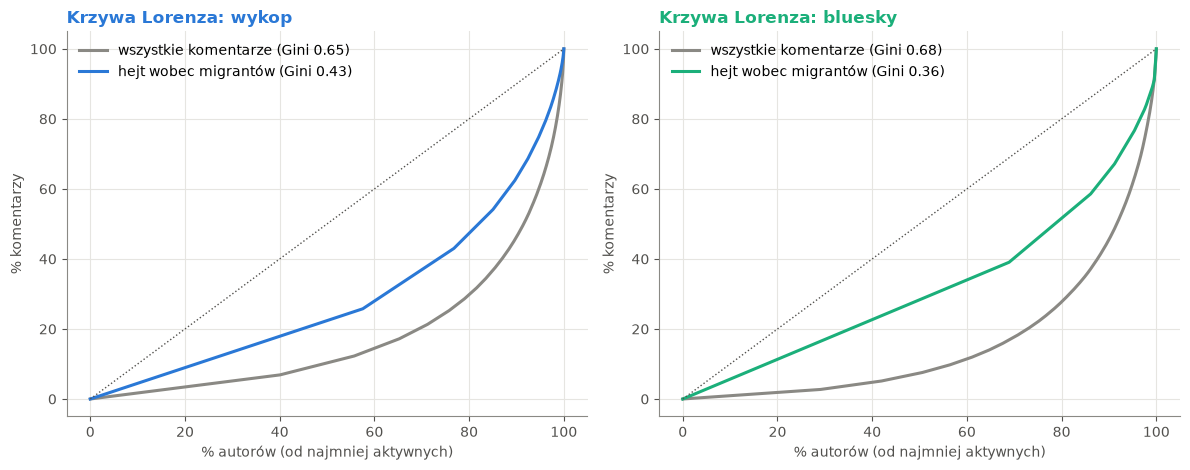

In [25]:
def gini(x):
    x = np.sort(np.asarray(x, float))
    n = len(x)
    if n == 0 or x.sum() == 0:
        return np.nan
    return 2 * (np.arange(1, n + 1) * x).sum() / (n * x.sum()) - (n + 1) / n


def top_share(x, q):
    x = np.sort(np.asarray(x, float))[::-1]
    k = max(1, int(np.ceil(q * len(x))))
    return 100 * x[:k].sum() / x.sum()


def lorenz(x):
    x = np.sort(np.asarray(x, float))
    return np.r_[0, np.arange(1, len(x) + 1) / len(x)], np.r_[0, np.cumsum(x) / x.sum()]


AUTH_PL = [p for p in ["wykop", "bluesky"] if p in PL]
conc_rows, curves = [], {}
for p in AUTH_PL:
    d = uniq[(uniq["platform"] == p) & uniq["author_id"].notna()].copy()
    d["author"] = d["author_id"] if p == "wykop" else d["event"] + ":" + d["author_id"]
    per_author = d.groupby("author").agg(all=("comment_id", "size"), hate=("hate_migrant", "sum"))
    haters = per_author.loc[per_author["hate"] > 0, "hate"]
    curves[p] = {"wszystkie komentarze": lorenz(per_author["all"]), "hejt wobec migrantów": lorenz(haters)}
    for name, x in [("wszystkie komentarze", per_author["all"]), ("hejt wobec migrantów", haters)]:
        conc_rows.append({"platform": p, "co": name, "autorów": len(x), "komentarzy": int(x.sum()),
                          "top 1% autorów [% treści]": top_share(x, 0.01), "top 10% autorów [% treści]": top_share(x, 0.10),
                          "Gini": gini(x), "śr. na autora": x.mean()})
    conc_rows[-1]["% autorów z ≥1 hejtem"] = 100 * len(haters) / len(per_author)
conc = pd.DataFrame(conc_rows).set_index(["platform", "co"])
display(conc.round(2))

fig, axes = plt.subplots(1, len(AUTH_PL), figsize=(6 * len(AUTH_PL), 4.8), squeeze=False)
for ax, p in zip(axes[0], AUTH_PL):
    for (name, (x, y)), ls in zip(curves[p].items(), ["-", "-"]):
        c = MUTED if name == "wszystkie komentarze" else PLATFORM_COLORS[p]
        ax.plot(x * 100, y * 100, color=c, ls=ls, lw=2.2,
                label=f"{name} (Gini {conc.loc[(p, name), 'Gini']:.2f})")
    ax.plot([0, 100], [0, 100], color=INK2, ls=":", lw=1)
    ax.set_xlabel("% autorów (od najmniej aktywnych)")
    ax.set_ylabel("% komentarzy")
    ax.grid(axis="x", visible=True)
    ax.legend(loc="upper left")
    ax.set_title(f"Krzywa Lorenza: {p}", color=PLATFORM_COLORS[p])
plt.tight_layout()
plt.show()

In [26]:
if "wykop" in AUTH_PL:
    d = df[(df["platform"] == "wykop") & df["hate_migrant"] & df["author_id"].notna()]
    ev_per_author = d.groupby("author_id")["event"].nunique()
    hate_per_author = d.drop_duplicates("comment_id").groupby("author_id").size()
    rep = pd.DataFrame({"wydarzeń": ev_per_author, "hejtów": hate_per_author})
    tab = rep.groupby(rep["wydarzeń"].clip(upper=4)).agg(autorów=("hejtów", "size"), hejtów=("hejtów", "sum"))
    tab.index = [f"{i}" if i < 4 else "4+" for i in tab.index]
    tab["% autorów"] = 100 * tab["autorów"] / tab["autorów"].sum()
    tab["% hejtu"] = 100 * tab["hejtów"] / tab["hejtów"].sum()
    print("Wykop: przy ilu wydarzeniach autor pisał hejt wobec migrantów")
    display(tab.round(1))
    print("Uwaga: Bojka/Strategia i Ceuta/Kamienna Góra mają bliskie okna – ten sam okres aktywności może liczyć się do dwóch wydarzeń.")

Wykop: przy ilu wydarzeniach autor pisał hejt wobec migrantów


,autorów,hejtów,% autorów,% hejtu
1,2687,3429,66.5,37.9
2,853,2383,21.1,26.4
3,320,1517,7.9,16.8
4+,180,1712,4.5,18.9


Uwaga: Bojka/Strategia i Ceuta/Kamienna Góra mają bliskie okna – ten sam okres aktywności może liczyć się do dwóch wydarzeń.


**Jak czytać:** *Gini* (0 = każdy autor pisze tyle samo, 1 = wszystko pisze jedna osoba) i *udział top 1% / 10%*
mówią, czy treść tworzy wąska grupa. Krzywa Lorenza: im dalej od przekątnej, tym większa koncentracja.
Punkt odniesienia to wszystkie komentarze – jeśli hejt byłby dziełem kilku „trolli”, byłby bardziej skupiony niż
zwykłe pisanie.

**Wnioski:**
- **Hejt jest mniej skoncentrowany niż zwykła aktywność**, nie bardziej. Wykop: Gini 0,43 dla hejtu vs 0,65 dla
  wszystkich komentarzy; top 10% autorów hejtu pisze 37% hejtu, a top 10% wszystkich autorów – 54% wszystkich
  komentarzy. Bluesky – to samo (0,36 vs 0,68).
- **Hejt pisze szerokie grono:** na Wykopie 36% aktywnych autorów napisało co najmniej jeden komentarz z hejtem wobec
  migrantów (średnio 2,2 na autora). Na Bluesky – 9% autorów (1,8 na autora).
- **Na Wykopie jest jednak stały rdzeń:** 12% autorów hejtowało przy 3+ wydarzeniach i odpowiada za 36% całego hejtu
  (część przez bliskie okna Ceuta / Kamienna Góra – patrz uwaga pod tabelą).
- Wniosek: hejt wobec migrantów to zjawisko **rozproszone** (wielu „okazjonalnych” autorów) z mniejszym rdzeniem
  powracających autorów, a nie dzieło kilku kont. Na YouTube nie da się tego sprawdzić (brak autorów).

## 6. Czy hejt zbiera więcej polubień?

Porównujemy komentarze **o migracji** (`migrant = 1`): z hejtem wobec migrantów vs bez hejtu, osobno na każdej
platformie (ten sam temat, więc różnica nie wynika z tego, że migracja ogólnie przyciąga więcej uwagi).

- mediana, średnia, % komentarzy z ≥ 1 polubieniem,
- **test Manna-Whitneya** (rangi; odporny na pojedyncze komentarze z tysiącami polubień) i prawdopodobieństwo przewagi
  P(hejt > bez hejtu),
- **model ujemny dwumianowy** `likes ~ hejt + C(wydarzenie)` z błędami klastrowanymi po wątku →
  **stosunek średnich** (ile razy więcej polubień ma średnio hejt w tym samym wydarzeniu).

Wykop: `likes` to głosy (plusy − minusy), mogą być ujemne – w testach rangowych zostają, w modelu przycinamy je do 0.

,n hejt,n bez hejtu,mediana hejt,mediana bez,średnia hejt,średnia bez,% ≥1 hejt,% ≥1 bez,P(hejt > bez),p Mann-Whitney,stosunek średnich (NB),lo,hi,p NB,p NB (Holm)
platform,,,,,,,,,,,,,,,
wykop,8952,14381,1.0,1.0,14.519,12.879,60.925,57.145,0.522,1.5e-08,1.135,1.018,1.265,0.0224,0.0224
youtube,11581,10361,0.0,1.0,7.212,12.953,48.890,50.208,0.477,3.52e-10,0.523,0.445,0.615,3.74e-15,1.12e-14
bluesky,420,826,1.0,1.0,2.555,1.800,71.429,67.918,0.567,6.11e-05,1.334,1.071,1.662,0.0101,0.0202


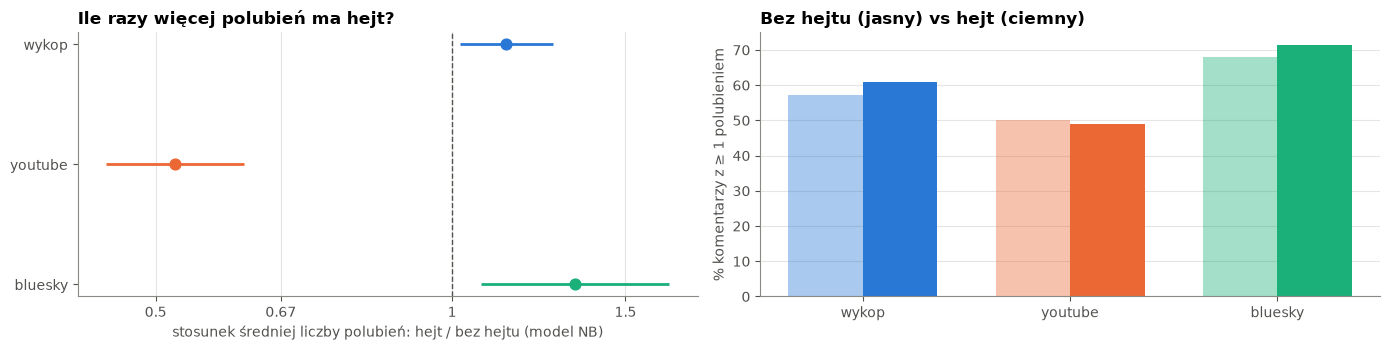

In [27]:
like_rows = []
for p in PL:
    d = uniq[(uniq["platform"] == p) & uniq["migrant"]].dropna(subset=["likes"]).copy()
    h, n = d.loc[d["hate_migrant"], "likes"], d.loc[~d["hate_migrant"], "likes"]
    mw = stats.mannwhitneyu(h, n, alternative="two-sided")
    d["likes0"] = d["likes"].clip(lower=0).astype(int)
    d["hejt"] = d["hate_migrant"].astype(int)
    formula = "likes0 ~ hejt + C(event)" if d["event"].nunique() > 1 else "likes0 ~ hejt"
    try:
        m = smf.negativebinomial(formula, data=d).fit(
            disp=0, maxiter=300, cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread"])[0]})
        b, s, pv = m.params["hejt"], m.bse["hejt"], m.pvalues["hejt"]
    except Exception as ex:
        print(p, "model NB nie zbiegł:", str(ex)[:80])
        b, s, pv = np.nan, np.nan, np.nan
    like_rows.append({"platform": p, "n hejt": len(h), "n bez hejtu": len(n),
                      "mediana hejt": h.median(), "mediana bez": n.median(),
                      "średnia hejt": h.mean(), "średnia bez": n.mean(),
                      "% ≥1 hejt": 100 * (h >= 1).mean(), "% ≥1 bez": 100 * (n >= 1).mean(),
                      "P(hejt > bez)": mw.statistic / (len(h) * len(n)), "p Mann-Whitney": mw.pvalue,
                      "stosunek średnich (NB)": np.exp(b), "lo": np.exp(b - 1.96 * s), "hi": np.exp(b + 1.96 * s),
                      "p NB": pv})
likes = pd.DataFrame(like_rows).set_index("platform")
likes["p NB (Holm)"] = holm(likes["p NB"]).values
display(fmt_p(likes, 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
ax = axes[0]
y = np.arange(len(PL))
for yi, p in zip(y, PL):
    r = likes.loc[p]
    ax.hlines(yi, r["lo"], r["hi"], color=PLATFORM_COLORS[p], lw=2)
    ax.scatter(r["stosunek średnich (NB)"], yi, s=60, color=PLATFORM_COLORS[p], zorder=3)
ax.axvline(1, color=INK2, ls="--", lw=1)
ax.set_xscale("log")
log_ticks(ax, "x")
ax.set_yticks(y, PL)
ax.invert_yaxis()
ax.grid(axis="x", visible=True)
ax.grid(axis="y", visible=False)
ax.set_xlabel("stosunek średniej liczby polubień: hejt / bez hejtu (model NB)")
ax.set_title("Ile razy więcej polubień ma hejt?")
ax = axes[1]
w = 0.36
ax.bar(y - w / 2, likes["% ≥1 bez"], width=w, color=[PLATFORM_COLORS[p] for p in PL], alpha=0.4, label="bez hejtu")
ax.bar(y + w / 2, likes["% ≥1 hejt"], width=w, color=[PLATFORM_COLORS[p] for p in PL], label="hejt")
ax.set_xticks(y, PL)
ax.set_ylabel("% komentarzy z ≥ 1 polubieniem")
ax.set_title("Bez hejtu (jasny) vs hejt (ciemny)")
plt.tight_layout()
plt.show()

**Jak czytać:** *P(hejt > bez)* = szansa, że losowy komentarz z hejtem ma więcej polubień niż losowy komentarz o
migracji bez hejtu (0,5 = brak różnicy). *Stosunek średnich (NB)* = ile razy więcej polubień ma średnio hejt w tym
samym wydarzeniu (1 = tyle samo).

**Wnioski:**
- **Wykop i Bluesky: hejt zbiera nieco więcej polubień.** Wykop – średnio 1,14× więcej [1,02; 1,27], Bluesky – 1,33×
  [1,07; 1,66]; oba istotne po korekcie Holma. Efekt jest jednak mały: P(hejt > bez) = 0,52 i 0,57, a mediana
  polubień jest taka sama (1).
- **YouTube: odwrotnie – hejt zbiera ok. 2× mniej polubień** (0,52× [0,45; 0,62]); mediana 0 vs 1.
  Możliwe wyjaśnienia: hejt częściej pojawia się w odpowiedziach głęboko w wątkach (mniej wyświetleń), a polubienia
  na YouTube kumulują się głównie przy najwyżej wyświetlanych komentarzach.
- **Brak uniwersalnego „nagradzania hejtu”** – wynik zależy od platformy. Na Wykopie `likes` to bilans plusów i
  minusów, więc tam przewaga oznacza, że hejt jest *netto* lepiej oceniany przez społeczność.

## 7. Typ wydarzenia a wielkość zmiany (H2)

**Typy:** kryminalne (przemoc / incydent; 3 wydarzenia), polityczne (2), dezinformacja (1), kryzys graniczny (1).
**Zasięg:** krajowe (5) vs zagraniczne (2).

- **Test główny:** meta-regresja log-OR (wszystkie komórki) z moderatorem `typ` i kontrolą platformy;
  test omnibus moderatora (F, poprawka Knappa–Hartunga).
- **Kontrast:** kryminalne vs reszta; **zasięg:** krajowe vs zagraniczne (ta sama meta-regresja).
- **Test permutacyjny:** przetasowujemy etykiety typu między **wydarzeniami** (wszystkie możliwe przypisania) i
  liczymy, jak często statystyka jest co najmniej tak duża jak prawdziwa – dokładne p bez założenia normalności.
- **Kierunek:** ile komórek każdego typu ma istotny wzrost / spadek.
- **Per platforma:** Wykop i YouTube – kontrast kryminalne vs reszta; Bluesky (po jednym wydarzeniu na typ) – tylko opis.

⚠️ Wynik eksploracyjny: 7 wydarzeń, a dezinformacja i kryzys graniczny mają po jednym – „efekt typu” jest tam
nieodróżnialny od efektu konkretnego wydarzenia.

In [28]:
def meta_reg(y, se, X):
    """Meta-regresja efektów mieszanych: τ² metodą momentów (DerSimonian–Laird), błędy Knappa–Hartunga."""
    y, v, X = np.asarray(y, float), np.asarray(se, float) ** 2, np.asarray(X, float)
    k, p = X.shape
    W = np.diag(1 / v)
    XtWX_inv = np.linalg.pinv(X.T @ W @ X)
    P = W - W @ X @ XtWX_inv @ X.T @ W
    q_e = float(y @ P @ y)
    tau2 = max(0.0, (q_e - (k - p)) / np.trace(P))
    Ws = np.diag(1 / (v + tau2))
    cov = np.linalg.pinv(X.T @ Ws @ X)
    b = cov @ X.T @ Ws @ y
    s2 = max(1.0, float((y - X @ b) @ Ws @ (y - X @ b)) / (k - p))
    return b, cov * s2, tau2, k - p


def moderator_test(e, mod_cols, control_platform=True):
    """Test omnibus (F) dla kolumn moderatora; zwraca (F, p, współczynniki moderatora, df)."""
    X = pd.DataFrame({"const": 1.0}, index=e.index)
    for c in mod_cols:
        X[c] = e[c].astype(float)
    if control_platform:
        for p in PL[1:]:
            X[f"pl_{p}"] = (e["platform"] == p).astype(float)
    X = X.loc[:, X.std().fillna(0).gt(0) | (X.columns == "const")]
    keep = [c for c in mod_cols if c in X.columns]
    if not keep:
        return np.nan, np.nan, {}, 0
    b, cov, tau2, dfr = meta_reg(e["log OR"], e["se"], X.values)
    idx = [list(X.columns).index(c) for c in keep]
    bm, cm = b[idx], cov[np.ix_(idx, idx)]
    F = float(bm @ np.linalg.pinv(cm) @ bm) / len(idx)
    return F, stats.f.sf(F, len(idx), dfr), dict(zip(keep, bm)), dfr


def type_dummies(e, typ_of_event):
    t = e["event"].map(typ_of_event)
    return e.assign(**{f"typ_{x}": (t == x).astype(float) for x in TYPE_ORDER[1:]},
                    kryminalne=(t == "kryminalne").astype(float),
                    zagraniczne=e["event"].map(lambda ev: EVENT_META[ev][1] == "zagraniczne").astype(float))


TYPE_COLS = [f"typ_{x}" for x in TYPE_ORDER[1:]]
true_typ = {ev: EVENT_META[ev][0] for ev in EVENT_ORDER}


def perm_test(e, kind):
    """Wszystkie przypisania etykiet typu do wydarzeń o tych samych licznościach; statystyka = F moderatora."""
    events = list(dict.fromkeys(e["event"]))
    labels = [true_typ[ev] for ev in events]
    obs = moderator_test(type_dummies(e, true_typ), TYPE_COLS if kind == "typ" else ["kryminalne"])[0]
    from itertools import permutations
    stats_ = []
    for perm in set(permutations(labels)):
        tp = dict(zip(events, perm))
        F = moderator_test(type_dummies(e, tp), TYPE_COLS if kind == "typ" else ["kryminalne"])[0]
        if not np.isnan(F):
            stats_.append(F)
    stats_ = np.array(stats_)
    return obs, np.mean(stats_ >= obs - 1e-12), stats_


h2_rows, perm_dist = [], {}
for metric in METRICS:
    e = type_dummies(E(metric).dropna(subset=["log OR"]), true_typ)
    F, p, coef, dfr = moderator_test(e, TYPE_COLS)
    Fk, pk, ck, _ = moderator_test(e, ["kryminalne"])
    Fz, pz, cz, _ = moderator_test(e, ["zagraniczne"])
    obs, pperm, dist = perm_test(e, "typ")
    obs_k, pperm_k, dist_k = perm_test(e, "kryminalne")
    perm_dist[metric] = (obs, dist, obs_k, dist_k)
    h2_rows.append({"miara": metric, "komórek": len(e), "F typ": F, "p typ (meta-regresja)": p,
                    "p typ (permutacyjny)": pperm, "przypisań typ": len(dist),
                    "OR kryminalne vs reszta": np.exp(ck.get("kryminalne", np.nan)), "p kryminalne": pk,
                    "p kryminalne (permutacyjny)": pperm_k, "przypisań kontrast": len(dist_k),
                    "OR zagraniczne vs krajowe": np.exp(cz.get("zagraniczne", np.nan)), "p zasięg": pz,
                    **{f"OR {t} vs kryminalne": np.exp(coef.get(f"typ_{t}", np.nan)) for t in TYPE_ORDER[1:]}})
h2 = pd.DataFrame(h2_rows).set_index("miara")
display(fmt_p(h2, 3))

,komórek,F typ,p typ (meta-regresja),p typ (permutacyjny),przypisań typ,OR kryminalne vs reszta,p kryminalne,p kryminalne (permutacyjny),przypisań kontrast,OR zagraniczne vs krajowe,p zasięg,OR polityczne vs kryminalne,OR dezinformacja vs kryminalne,OR kryzys graniczny vs kryminalne
miara,,,,,,,,,,,,,,
hate_migrant/all,16,2.041,0.172,0.29,420,1.031,0.916,0.971,420,1.141,0.661,1.516,0.767,0.620
migrant/all,16,2.138,0.159,0.348,420,0.904,0.706,0.829,420,1.232,0.46,1.783,0.834,0.777
hate_migrant/migrant,16,0.641,0.606,0.595,420,1.224,0.336,0.429,420,0.840,0.437,0.778,1.000,0.707


In [29]:
dir_rows = []
for metric in METRICS:
    e = E(metric).dropna(subset=["log OR"])
    for t in TYPE_ORDER:
        g = e[e["typ"] == t]
        m = meta_random(g["log OR"], g["se"])
        dir_rows.append({"miara": metric, "typ": t, "wydarzeń": g["event"].nunique(), "komórek": len(g),
                         "wzrost": int((g["log OR"] > 0).sum()), "spadek": int((g["log OR"] < 0).sum()),
                         "istotnie ↑": int((g["kierunek"] == "↑").sum()), "istotnie ↓": int((g["kierunek"] == "↓").sum()),
                         **or_row(m)})
dirs = pd.DataFrame(dir_rows).set_index(["miara", "typ"])
print("Kierunek i siła zmian per typ (OR = meta-analiza efektów losowych komórek danego typu):")
display(fmt_p(dirs, 2))

pp_rows = []
for metric in METRICS:
    for p in PL:
        e = type_dummies(E(metric)[E(metric)["platform"] == p].dropna(subset=["log OR"]), true_typ)
        row = {"miara": metric, "platform": p, "wydarzeń": len(e)}
        if p != "bluesky" and e["kryminalne"].nunique() > 1:
            Fk, pk, ck, _ = moderator_test(e, ["kryminalne"], control_platform=False)
            Fz, pz, cz, _ = moderator_test(e, ["zagraniczne"], control_platform=False)
            row.update({"OR kryminalne vs reszta": np.exp(ck.get("kryminalne", np.nan)), "p kryminalne": pk,
                        "OR zagraniczne vs krajowe": np.exp(cz.get("zagraniczne", np.nan)), "p zasięg": pz})
        pp_rows.append(row)
print("Per platforma (Bluesky: tylko opis – każdy typ ma jedno wydarzenie):")
display(fmt_p(pd.DataFrame(pp_rows).set_index(["miara", "platform"]), 3))

Kierunek i siła zmian per typ (OR = meta-analiza efektów losowych komórek danego typu):


wydarzeń  komórek  wzrost  spadek  istotnie ↑  istotnie ↓    OR  OR lo  OR hi       p
miara                typ                                                                                                    
hate_migrant/all     kryminalne               3        6       2       4           0           1  1.03   0.65   1.63   0.882
                     polityczne               2        4       3       1           2           0  1.70   0.66   4.40   0.173
                     dezinformacja            1        3       1       2           0           0  0.80   0.25   2.56   0.494
                     kryzys graniczny         1        3       0       3           0           1  0.63   0.21   1.90   0.214
migrant/all          kryminalne               3        6       3       3           0           1  1.05   0.68   1.62   0.773
                     polityczne               2        4       4       0           2           0  2.06   0.80   5.35  0.0942
                     dezinformacja            1        3       1       2           0           0  0.90   0.44   1.86   0.597
                     kryzys graniczny         1        3       1       2           0           0  0.80   0.29   2.21   0.439
hate_migrant/migrant kryminalne               3        6       3       3           1           0  0.97   0.62   1.54    0.89
                     polityczne               2        4       1       3           0           2  0.69   0.30   1.58   0.253
                     dezinformacja            1        3       1       2           0           0  1.01   0.56   1.84   0.926
                     kryzys graniczny         1        3       0       3           0           0  0.71   0.37   1.37   0.154

Per platforma (Bluesky: tylko opis – każdy typ ma jedno wydarzenie):


wydarzeń  OR kryminalne vs reszta p kryminalne  OR zagraniczne vs krajowe p zasięg
miara                platform                                                                                    
hate_migrant/all     wykop            7                    0.752        0.356                      1.452    0.264
                     youtube          6                    1.607        0.563                      1.036    0.965
                     bluesky          3                      NaN                                     NaN         
migrant/all          wykop            7                    0.744        0.393                      1.517    0.257
                     youtube          6                    0.990        0.989                      1.381    0.672
                     bluesky          3                      NaN                                     NaN         
hate_migrant/migrant wykop            7                    0.945        0.646                      1.049    0.717
                     youtube          6                    2.550        0.167                      0.470    0.313
                     bluesky          3                      NaN                                     NaN

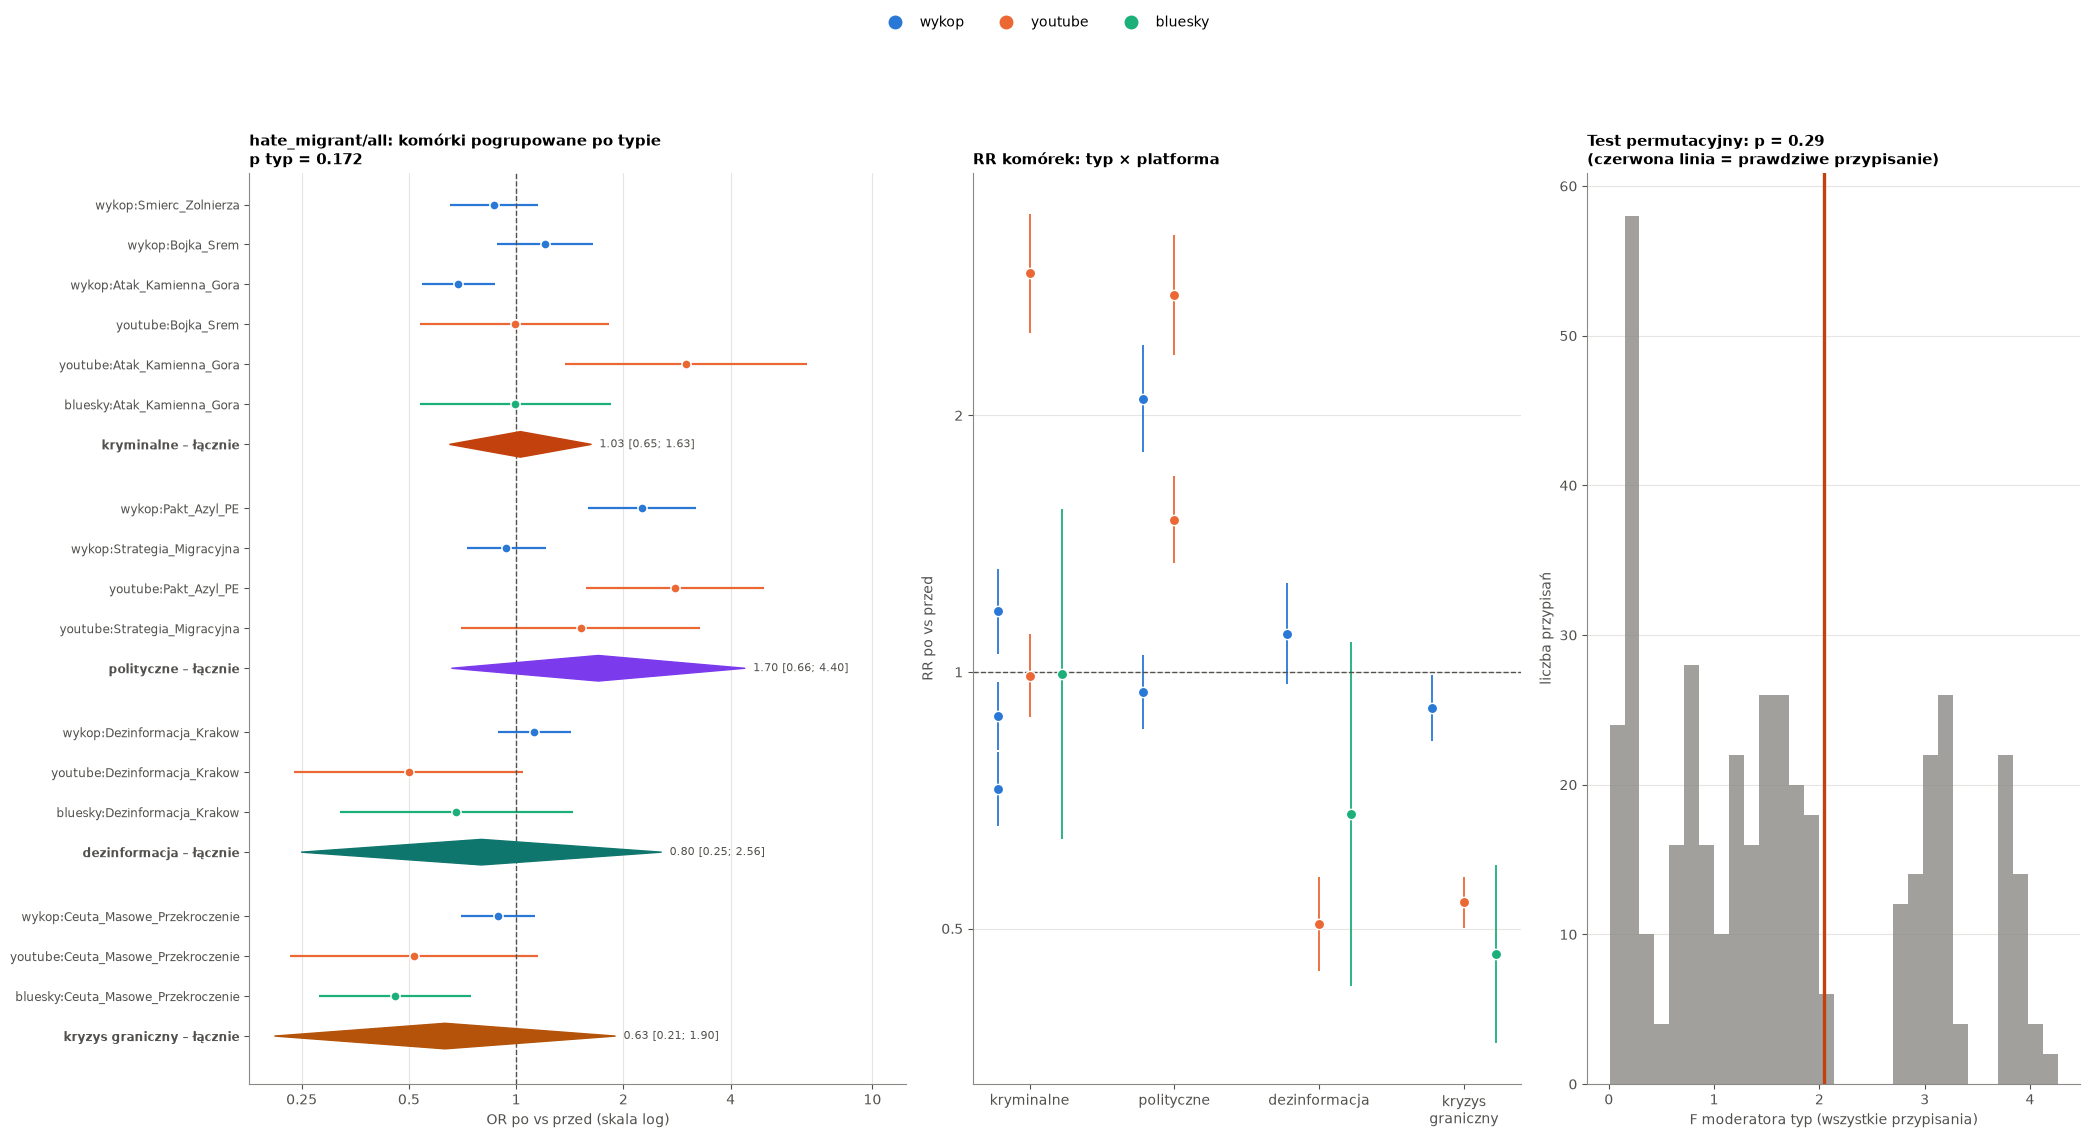

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(21, 0.5 * len(CELLS) + 3.4), gridspec_kw={"width_ratios": [1.2, 1, 0.9]})
groups = []
for t in TYPE_ORDER:
    g = E(MAIN)[E(MAIN)["typ"] == t].dropna(subset=["log OR"])
    m = meta_random(g["log OR"], g["se"])
    groups.append({"label": f"{t} – łącznie", "items": items_from(g.assign(lab=g["cell"]), "lab",
                                                                   lambda r_: PLATFORM_COLORS[r_["platform"]]),
                   "diamond": dia(m, TYPE_COLORS[t])})
forest(axes[0], groups, title=f"{MAIN}: komórki pogrupowane po typie\np typ = {h2.loc[MAIN, 'p typ (meta-regresja)']:.3g}")

ax = axes[1]
offs = np.linspace(-0.22, 0.22, len(PL))
for off, p in zip(offs, PL):
    e = E(MAIN)[E(MAIN)["platform"] == p].dropna(subset=["RR"])
    xx = e["typ"].map({t: i for i, t in enumerate(TYPE_ORDER)}) + off
    ax.vlines(xx, e["RR lo"], e["RR hi"], color=PLATFORM_COLORS[p], lw=1.3)
    ax.scatter(xx, e["RR"], s=55, color=PLATFORM_COLORS[p], edgecolor="white", zorder=3)
ax.axhline(1, color=INK2, ls="--", lw=1)
ax.set_yscale("log")
log_ticks(ax, "y")
ax.set_xticks(range(len(TYPE_ORDER)), [t.replace(" ", "\n") for t in TYPE_ORDER])
ax.set_ylabel("RR po vs przed")
ax.set_title("RR komórek: typ × platforma", fontsize=11)

ax = axes[2]
obs, dist, obs_k, dist_k = perm_dist[MAIN]
ax.hist(dist, bins=30, color=MUTED, alpha=0.8)
ax.axvline(obs, color="#c2410c", lw=2.4)
ax.set_xlabel("F moderatora typ (wszystkie przypisania)")
ax.set_ylabel("liczba przypisań")
ax.set_title(f"Test permutacyjny: p = {h2.loc[MAIN, 'p typ (permutacyjny)']:.3g}\n"
             f"(czerwona linia = prawdziwe przypisanie)", fontsize=11)
platform_legend(fig, top=0.9)
plt.show()

**Jak czytać:** meta-regresja sprawdza, czy log-OR komórek różni się w zależności od typu wydarzenia (przy kontroli
platformy). Test permutacyjny przestawia etykiety typu między wydarzeniami – p mówi, jak często losowe przypisanie
typów daje równie duże różnice. Lewy wykres: komórki pogrupowane po typie, romb = łączny OR typu.

**Wnioski:**
- **H2 niepotwierdzona: typ wydarzenia nie wyjaśnia, czy hejt rośnie.** `hate_migrant/all`: p typ = 0,17
  (permutacyjny 0,29); kryminalne vs reszta OR 1,03 (p = 0,92); zagraniczne vs krajowe OR 1,14 (p = 0,66).
  To samo dla obu miar wspierających.
- **Opisowo:** wydarzenia **polityczne** mają największy łączny wzrost (OR 1,70; 3 z 4 komórek ↑, 2 istotnie – głównie
  Pakt_Azyl_PE), a **kryzys graniczny** (Ceuta) – spadek na wszystkich trzech platformach (OR 0,63). Wydarzenia
  **kryminalne** dają wynik mieszany (OR 1,03; 2 komórki ze wzrostem, 4 ze spadkiem).
- **Ostrożnie:** przy 7 wydarzeniach (dezinformacja i kryzys graniczny – po jednym) „efekt typu” jest nieodróżnialny
  od efektu konkretnego wydarzenia. Wynik eksploracyjny – brak istotności nie wyklucza, że typ ma znaczenie, ale te
  dane go nie pokazują.